# Feature-Based Machine Unlearning for Gradient Boosted Trees under Concept Drift

## Detecting stale features and removing their influence from an already-trained model

---

### Research idea

When a model is repeatedly updated on new data, the data distribution, and sometimes the
relationship between features and label, drifts over time (concept drift / data drift).
As a result, a feature that was informative in an earlier period can become stale, or even
misleading, while the model keeps relying on it because it has never been retrained from scratch.

This notebook addresses the following problem: how can stale features be identified, and their
influence removed from an already-trained model, without retraining the whole model from scratch
(this is machine unlearning, applied at the feature level rather than the instance level used in
most existing work).

The target architecture is Gradient Boosted Trees (GBT), the most common model family for tabular
data in practice. Unlike linear models, GBT has no closed-form unlearning update (see Warnecke et
al., NDSS'23, for the linear-model case). The contribution of this work is two purpose-built
methods that approximate "forgetting" a feature on a GBT ensemble, benchmarked against an ideal
full-retraining baseline (Gold Retrain).

### Notebook pipeline

This notebook contains exactly the pipeline reported in the paper. Two exploratory parts from the
original development notebook that are **not** referenced by any result in the paper (a baseline
comparison on the non-drifted data, and a diagnostic extension that included the Membership
Inference Attack, later dropped from the evaluation framework) have been removed for brevity; the
part numbers below are kept as in the original pipeline for traceability.

| Part | Content | Main output |
|---|---|---|
| **1** | Minimal EDA on the two original datasets (Census, Forest CoverType) | Label distribution, imbalance ratio |
| **1b** | Class imbalance handling (SMOTE / RandomOverSampler) | Balanced source data |
| **2** | Synthetic drift generation, 6 domains simulating 6 time periods | `df_*_drifted` (D0-D2 = stale/old, D3-D5 = current/new) |
| **4** | Encode + split the drifted data; define the two linear helper models | Data ready for drift-score analysis |
| **5** | Train GBT on the drifted data | The "Original" model used by every method below |
| **6** | Stale feature identification, Drift Score | `stale_idx_c`, `stale_idx_f`, the features to unlearn |
| **7** | Feature-based unlearning for GBT: Method 1, Method 2, Gold Retrain | Utility / forgetting comparison across methods |
| **8** | Security evaluation, Attribute Inference Attack (AIA) | How much information about the unlearned feature leaks back |
| **10** | Comparison against the closest prior work (Warnecke et al., NDSS'23) | Cross-architecture benchmark table |
| **11** | Reconstruction attack: ensemble attacker, identifiability-ceiling normalization, Top-1 attack | Final security metric reported in the paper |


## Part 0 — Environment Setup

Install the required libraries:
- `pandas`, `numpy` for data handling
- `matplotlib`, `seaborn` for visualization
- `scikit-learn` for preprocessing, metrics, Logistic Regression, and **GradientBoostingClassifier**
  — used throughout the notebook, both as the baseline and as the model being unlearned in Part 7,
  so that a single model architecture is used consistently. XGBoost/LightGBM are intentionally not
  used: neither library exposes the internal tree structure (`tree_.value`, `tree_.feature`, ...)
  that the unlearning methods in Part 7 need direct access to.


In [1]:
# !pip install -q scikit-learn pandas numpy matplotlib seaborn

import warnings; warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['figure.dpi'] = 120
sns.set_theme(style='whitegrid', palette='Set2')
# ---- Shared imports (used across Parts 1-11) ----
import copy, time
from scipy.special import expit
from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier, RandomForestRegressor
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score, roc_curve,
                             auc as sk_auc, confusion_matrix, classification_report,
                             balanced_accuracy_score, r2_score)

SEED = 42
np.random.seed(SEED)
print('Setup done')

Setup done


## Data Upload

Two CSV files are used:

| File | Description |
|------|-------------|
| `census_stable.csv` | Cleaned Adult Census Income dataset |
| `covtype_stable.csv` | Cleaned Forest CoverType dataset |


In [2]:
!gdown 1BrR9UMFox4-DKYt4g3gYc8hDQTAwwnO2
!gdown 1aE4163bJluyY9Y95X551Ggc6foC8rdXW

Downloading...
From: https://drive.google.com/uc?id=1BrR9UMFox4-DKYt4g3gYc8hDQTAwwnO2
To: /content/census_stable.csv
100% 5.72M/5.72M [00:00<00:00, 105MB/s]
Downloading...
From: https://drive.google.com/uc?id=1aE4163bJluyY9Y95X551Ggc6foC8rdXW
To: /content/covtype_stable.csv
100% 24.0M/24.0M [00:00<00:00, 34.5MB/s]


In [ ]:
# ======================================================================================
# [LOCAL ALTERNATIVE]  Load data WITHOUT Google Colab and/or WITHOUT `!gdown`
# --------------------------------------------------------------------------------------
# Every line in this cell is commented out on purpose: Colab users can simply ignore it.
# To run locally, skip the `!gdown` cell above and use ONE of the two options below.
#
# Expected repository layout (this notebook lives in source/, data lives in dataset/):
#   Drift-Aware-MU/
#   |-- dataset/
#   |   |-- census_stable.csv
#   |   `-- covtype_stable.csv
#   `-- source/
#       `-- <this notebook>          <- the kernel's working directory must be source/
#
# --- Option A: download with the gdown *Python API* (no shell command needed) -----------
# import os, gdown
# os.makedirs('../dataset', exist_ok=True)
# gdown.download(id='1BrR9UMFox4-DKYt4g3gYc8hDQTAwwnO2', output='../dataset/census_stable.csv',  quiet=False)
# gdown.download(id='1aE4163bJluyY9Y95X551Ggc6foC8rdXW', output='../dataset/covtype_stable.csv', quiet=False)
#
# --- Option B: manual download (if gdown is blocked / unavailable) ----------------------
# Open each link in a browser and save the file into ../dataset/ under EXACTLY this name:
#   https://drive.google.com/uc?id=1BrR9UMFox4-DKYt4g3gYc8hDQTAwwnO2   ->  census_stable.csv   (~5.7 MB)
#   https://drive.google.com/uc?id=1aE4163bJluyY9Y95X551Ggc6foC8rdXW   ->  covtype_stable.csv  (~24 MB)
#
# --- Then point the pipeline to the local files -----------------------------------------
# In the two loading cells below ("Load Census" and "Load Forest"), comment out the Colab
# `pd.read_csv('<name>.csv')` line and uncomment the local `pd.read_csv('../dataset/<name>.csv')` line.

---

# Part 1 — Exploratory Data Analysis on the Original Datasets

**Goal:** understand each dataset before injecting drift.

We look at:
1. Label distribution — class imbalance
2. Numerical feature distributions — shape, range, outliers
3. Categorical feature distributions (Census only)
4. Correlation matrix — which features relate most strongly to the label

---


## 1.1 Census (Adult Income) — Descriptive Statistics

### About this dataset

Adult Census Income predicts whether a person's income is **above or below $50K/year** from
demographic attributes.

| Feature group | Columns |
|---|---|
| **Numerical** | `age`, `fnlwgt`, `education-num`, `capital-gain`, `capital-loss`, `hours-per-week` |
| **Categorical** | `workclass`, `education`, `marital-status`, `occupation`, `relationship`, `race`, `sex`, `native-country` |
| **Label** | `>50K` (1) or `<=50K` (0) |


In [3]:
# Load Census
# --- Local run (no Colab / no gdown): comment out the Colab line below and uncomment this one ---
# df_census = pd.read_csv('../dataset/census_stable.csv')
df_census = pd.read_csv('census_stable.csv')
for col in df_census.select_dtypes(include='object').columns:
    df_census[col] = df_census[col].str.strip()

# Column definitions -- used throughout the notebook
NUMERICAL_COLS  = ['age', 'fnlwgt', 'education-num',
                   'capital-gain', 'capital-loss', 'hours-per-week']
CATEGORICAL_COLS = ['workclass', 'education', 'marital-status',
                    'occupation', 'relationship', 'race', 'sex', 'native-country']

print(f'Shape: {df_census.shape}')
print(f'Missing ("?"): {(df_census=="?").sum().sum()} cells')
df_census.head()


Shape: (48841, 15)
Missing ("?"): 6465 cells


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,label
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


### Label Distribution — Census

Census is **mildly imbalanced** (~3:1), so a majority-class baseline already reaches ~75% accuracy;
F1 and AUC are used alongside accuracy throughout.


Label Distribution:
  <=50K: 37,154 (76.07%)
  >50K: 11,687 (23.93%)
Imbalance ratio: 3.18x


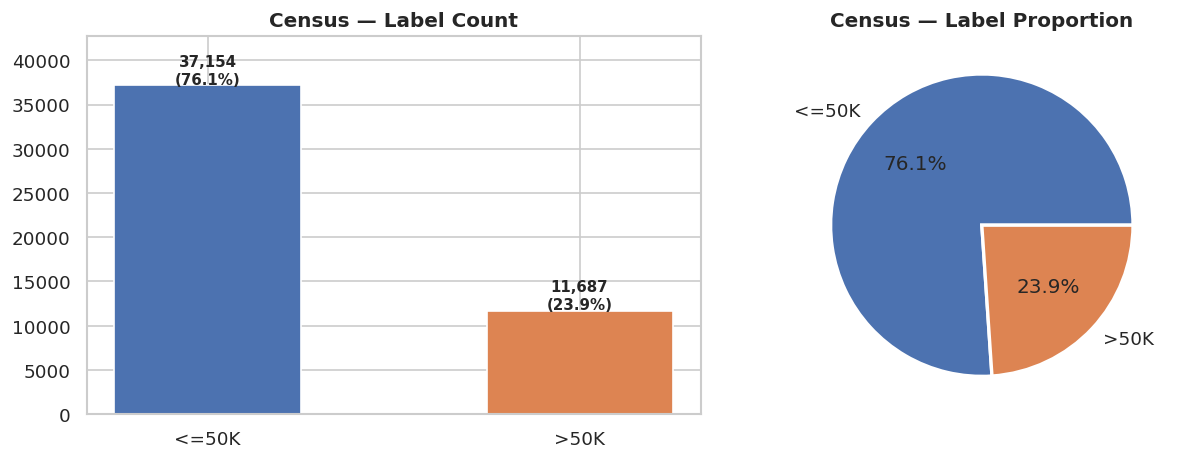

In [4]:
lc = df_census['label'].value_counts()
lp = lc / len(df_census) * 100
print('Label Distribution:')
for l in lc.index:
    print(f'  {l}: {lc[l]:,} ({lp[l]:.2f}%)')
print(f'Imbalance ratio: {lc.max()/lc.min():.2f}x')

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
colors = ['#4C72B0', '#DD8452']
axes[0].bar(lc.index, lc.values, color=colors, width=0.5, edgecolor='white')
for i, (l, c_) in enumerate(lc.items()):
    axes[0].text(i, c_+200, f'{c_:,}\n({c_/len(df_census)*100:.1f}%)',
                 ha='center', fontsize=9, fontweight='bold')
axes[0].set_title('Census — Label Count', fontweight='bold')
axes[0].set_ylim(0, lc.max()*1.15)
axes[1].pie(lc.values, labels=lc.index, autopct='%1.1f%%', colors=colors,
            wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[1].set_title('Census — Label Proportion', fontweight='bold')
plt.tight_layout()
plt.savefig('census_label_dist.png', bbox_inches='tight')
plt.show()


## 1.2 Forest CoverType — Descriptive Statistics

### About this dataset

Forest CoverType predicts the **forest cover type** of each 30x30m cell in a Colorado forest, from
cartographic and hydrological attributes.

| Label | Cover type | Terrain characteristics |
|-------|----------|-------------------|
| 1 | Spruce/Fir | High elevation, heavily shaded |
| 2 | Lodgepole Pine | Most common, widely distributed |
| 3 | Ponderosa Pine | Lower elevation, gentle slope |
| 4 | Cottonwood/Willow | Near water, very rare |
| 5 | Aspen | Mid elevation |
| 6 | Douglas-fir | Steep slope, south-facing |
| 7 | Krummholz | Very high elevation, exposed to wind |


In [5]:
# Load Forest
# --- Local run (no Colab / no gdown): comment out the Colab line below and uncomment this one ---
# df_forest = pd.read_csv('../dataset/covtype_stable.csv')
df_forest = pd.read_csv('covtype_stable.csv')

CLASS_NAMES = {1:'Spruce/Fir', 2:'Lodgepole Pine', 3:'Ponderosa Pine',
               4:'Cottonwood/Willow', 5:'Aspen', 6:'Douglas-fir', 7:'Krummholz'}
FEATURE_COLS = ['Elevation', 'Aspect', 'Slope',
                'Horizontal_Distance_To_Hydrology', 'Vertical_Distance_To_Hydrology',
                'Horizontal_Distance_To_Roadways',
                'Hillshade_9am', 'Hillshade_Noon', 'Hillshade_3pm',
                'Horizontal_Distance_To_Fire_Points']

print(f'Shape: {df_forest.shape}')
df_forest.head()


Shape: (581012, 11)


,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,label
0,2596,51,3,258,0,510,221,232,148,6279,5
1,2590,56,2,212,-6,390,220,235,151,6225,5
2,2804,139,9,268,65,3180,234,238,135,6121,2
3,2785,155,18,242,118,3090,238,238,122,6211,2
4,2595,45,2,153,-1,391,220,234,150,6172,5


### Label Distribution

Forest CoverType is **severely imbalanced**: classes 1 and 2 dominate, class 4 (Cottonwood/Willow)
is extremely rare (~0.5%). This matters because the minority class must not disappear entirely
once older domains are forgotten during unlearning.


Label Distribution (Forest):
  C1 Spruce/Fir          : 211,840 (36.46%) IIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIII
  C2 Lodgepole Pine      : 283,301 (48.76%) IIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIII
  C3 Ponderosa Pine      :  35,754 ( 6.15%) IIIIII
  C4 Cottonwood/Willow   :   2,747 ( 0.47%) 
  C5 Aspen               :   9,493 ( 1.63%) I
  C6 Douglas-fir         :  17,367 ( 2.99%) II
  C7 Krummholz           :  20,510 ( 3.53%) III
Imbalance ratio: 103.1x


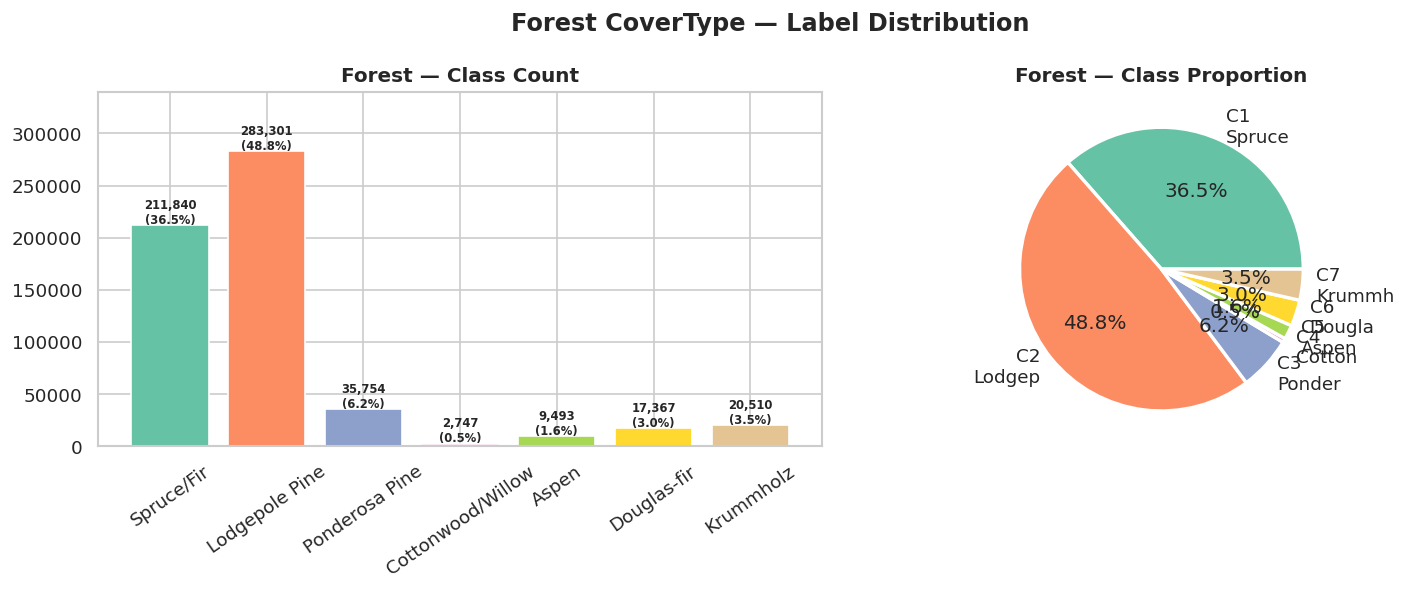

In [6]:
lc_f = df_forest['label'].value_counts().sort_index()
lp_f = lc_f / len(df_forest) * 100
print('Label Distribution (Forest):')
for l in lc_f.index:
    bar = 'I' * int(lp_f[l])
    print(f'  C{l} {CLASS_NAMES[l]:<20s}: {lc_f[l]:>7,} ({lp_f[l]:>5.2f}%) {bar}')
print(f'Imbalance ratio: {lc_f.max()/lc_f.min():.1f}x')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
pal = sns.color_palette('Set2', 7)
bars = axes[0].bar([CLASS_NAMES[i] for i in lc_f.index], lc_f.values,
                   color=pal, edgecolor='white')
for bar, cnt in zip(bars, lc_f.values):
    axes[0].text(bar.get_x()+bar.get_width()/2, bar.get_height()+1500,
                 f'{cnt:,}\n({cnt/len(df_forest)*100:.1f}%)',
                 ha='center', fontsize=7, fontweight='bold')
axes[0].set_title('Forest — Class Count', fontweight='bold')
axes[0].tick_params(axis='x', rotation=35)
axes[0].set_ylim(0, lc_f.max()*1.2)
axes[1].pie(lc_f.values,
            labels=[f'C{i}\n{CLASS_NAMES[i][:6]}' for i in lc_f.index],
            autopct='%1.1f%%', colors=pal,
            wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[1].set_title('Forest — Class Proportion', fontweight='bold')
plt.suptitle('Forest CoverType — Label Distribution', fontweight='bold')
plt.tight_layout()
plt.savefig('forest_label_dist.png', bbox_inches='tight')
plt.show()


---

# Part 1b — Class Imbalance Handling (Before Drift Generation)

## Why balance before generating drift?

```
Correct order:
  Original data
       -> SMOTE / oversampling (once)
       -> Generate drift domains   (drawn from the balanced pool)
       -> Freeze domains           (no further rebalancing — the drift is intentional)
       -> Train models
       -> Unlearning
```

**Reasoning:** weighted sampling for the drift domains draws from the original data; if that source
is already imbalanced, the minority class stays underrepresented in every domain. Balancing first
gives the domain-construction step a fair pool to sample from. After the drift domains are built,
no further rebalancing is applied, since each domain's class ratio is now an intentional part of
the injected label shift, not an imbalance to correct.

**Census:** binary SMOTE, balancing `>50K` vs `<=50K`.
**Forest:** multiclass SMOTE would be prohibitively memory-heavy at 581K rows, so
**RandomOverSampler** is used instead to balance all seven classes.


## 1b.1 Census — SMOTE on the Original Data


In [7]:
!pip install -q imbalanced-learn
from imblearn.over_sampling import SMOTE, RandomOverSampler
from sklearn.preprocessing import MinMaxScaler

print('=== Census - Class Balancing (BEFORE drift generation) ===')
print(f'  Original shape: {df_census.shape}')
lc_orig = df_census['label'].value_counts()
for l, cnt in lc_orig.items():
    print(f'    {l}: {cnt:,} ({cnt/len(df_census)*100:.2f}%)')
print(f'  Imbalance ratio: {lc_orig.max()/lc_orig.min():.2f}x')

# One-hot + encode (SMOTE needs full numerical input)
df_c_raw = df_census.copy()
df_c_raw['label_bin'] = (df_c_raw['label'] == '>50K').astype(int)
df_c_enc_raw = pd.get_dummies(
    df_c_raw[NUMERICAL_COLS + CATEGORICAL_COLS + ['label_bin']],
    columns=CATEGORICAL_COLS
)
X_c_raw = df_c_enc_raw.drop(columns=['label_bin']).values.astype(np.float32)
y_c_raw = df_c_enc_raw['label_bin'].values

sc_c_raw = MinMaxScaler()
X_c_raw_sc = sc_c_raw.fit_transform(X_c_raw)

# SMOTE
smote_c = SMOTE(random_state=SEED, k_neighbors=5)
X_c_balanced, y_c_balanced = smote_c.fit_resample(X_c_raw_sc, y_c_raw)

print(f'\n  After SMOTE:')
print(f'  Shape: {X_c_balanced.shape}')
u_c, cnt_c = np.unique(y_c_balanced, return_counts=True)
for u, cnt in zip(u_c, cnt_c):
    print(f'    {"<=50K" if u==0 else ">50K"}: {cnt:,} ({cnt/len(y_c_balanced)*100:.2f}%)')
print(f'  Imbalance ratio: {cnt_c.max()/cnt_c.min():.2f}x')

# Rebuild df_c_bal_enc -- keep all encoded columns + label string
feat_cols_c = df_c_enc_raw.drop(columns=['label_bin']).columns.tolist()
X_c_inv = sc_c_raw.inverse_transform(X_c_balanced)
df_c_bal_enc = pd.DataFrame(X_c_inv, columns=feat_cols_c)
df_c_bal_enc['label_bin'] = y_c_balanced
df_c_bal_enc['label']     = df_c_bal_enc['label_bin'].map({1: '>50K', 0: '<=50K'})

# Ensure NUMERICAL_COLS exist in df_c_bal_enc
for col in NUMERICAL_COLS:
    if col not in df_c_bal_enc.columns:
        print(f'  WARNING: {col} missing -- using the encoded version instead')

print(f'\n  df_c_bal_enc: {df_c_bal_enc.shape}')
print(f'  Columns sample: {list(df_c_bal_enc.columns[:8])}')
print(f'  Ready for Census drift generation')


=== Census - Class Balancing (BEFORE drift generation) ===
  Original shape: (48841, 15)
    <=50K: 37,154 (76.07%)
    >50K: 11,687 (23.93%)
  Imbalance ratio: 3.18x

  After SMOTE:
  Shape: (74308, 108)
    <=50K: 37,154 (50.00%)
    >50K: 37,154 (50.00%)
  Imbalance ratio: 1.00x

  df_c_bal_enc: (74308, 110)
  Columns sample: ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week', 'workclass_?', 'workclass_Federal-gov']
  Ready for Census drift generation


## 1b.2 Forest — RandomOverSampler on the Original Data

At 581K rows and 7 classes, SMOTE would be memory-prohibitive, so `RandomOverSampler`
(random duplication of minority-class rows) is used instead.


In [8]:
from sklearn.preprocessing import StandardScaler

# Define constants needed for Forest (must exist before use)
CLASSES_ORIGINAL = [1, 2, 3, 4, 5, 6, 7]
N_CLASSES        = len(CLASSES_ORIGINAL)
label_map_f      = {c: i for i, c in enumerate(CLASSES_ORIGINAL)}  # {1:0,...,7:6}

print('=== Forest - Class Balancing (BEFORE drift generation) ===')
print(f'  Original shape: {df_forest.shape}')
print(f'  Label dist (original):')
vc_f_orig = df_forest['label'].value_counts().sort_index()
for l, cnt in vc_f_orig.items():
    print(f'    C{l} {CLASS_NAMES[l]:<20s}: {cnt:>7,} ({cnt/len(df_forest)*100:.3f}%)')
print(f'  Imbalance ratio: {vc_f_orig.max()/vc_f_orig.min():.1f}x')

# RandomOverSampler -- faster, less RAM than SMOTE at 581K rows
X_f_raw_ros = df_forest[FEATURE_COLS].values.astype(np.float64)
y_f_raw_ros = df_forest['label'].values   # labels 1-7

ros = RandomOverSampler(random_state=SEED)
X_f_balanced, y_f_balanced = ros.fit_resample(X_f_raw_ros, y_f_raw_ros)

# Rebuild the DataFrame with the original label and label_idx
df_forest_balanced = pd.DataFrame(X_f_balanced, columns=FEATURE_COLS)
df_forest_balanced['label']     = y_f_balanced                           # 1-7
df_forest_balanced['label_idx'] = df_forest_balanced['label'].map(label_map_f)  # 0-6

print(f'\n  After RandomOverSampler:')
print(f'  Shape: {df_forest_balanced.shape}')
unique_f, counts_f = np.unique(y_f_balanced, return_counts=True)
for u, cnt in zip(unique_f, counts_f):
    print(f'    C{u} {CLASS_NAMES[u]:<20s}: {cnt:>7,} ({cnt/len(y_f_balanced)*100:.2f}%)')
print(f'  Imbalance ratio: {counts_f.max()/counts_f.min():.2f}x')
print(f'  df_forest_balanced ready — label_idx range: {df_forest_balanced["label_idx"].min()}-{df_forest_balanced["label_idx"].max()}')


=== Forest - Class Balancing (BEFORE drift generation) ===
  Original shape: (581012, 11)
  Label dist (original):
    C1 Spruce/Fir          : 211,840 (36.461%)
    C2 Lodgepole Pine      : 283,301 (48.760%)
    C3 Ponderosa Pine      :  35,754 (6.154%)
    C4 Cottonwood/Willow   :   2,747 (0.473%)
    C5 Aspen               :   9,493 (1.634%)
    C6 Douglas-fir         :  17,367 (2.989%)
    C7 Krummholz           :  20,510 (3.530%)
  Imbalance ratio: 103.1x

  After RandomOverSampler:
  Shape: (1983107, 12)
    C1 Spruce/Fir          : 283,301 (14.29%)
    C2 Lodgepole Pine      : 283,301 (14.29%)
    C3 Ponderosa Pine      : 283,301 (14.29%)
    C4 Cottonwood/Willow   : 283,301 (14.29%)
    C5 Aspen               : 283,301 (14.29%)
    C6 Douglas-fir         : 283,301 (14.29%)
    C7 Krummholz           : 283,301 (14.29%)
  Imbalance ratio: 1.00x
  df_forest_balanced ready — label_idx range: 0-6


---

# Part 2 — Synthetic Drift Data Generation

**Goal:** simulate how the data changes over time by constructing six domains with different
distributions.

---

### Idea: weighted resampling

Rather than collecting real data across multiple time periods, we resample the same underlying
pool with different weights per domain. This follows the domain-construction idea used by
Drift-Resilient TabPFN, where domains are built by sorting on a time-relevant feature and
resampling with weights.

### Domain layout

```
D0 ---- D1 ---- D2 ---- D3 ---- D4 ---- D5
<------- STALE (forget) ------->  <---- CURRENT (retain) ---->
t=0                               t=0.6                     t=1
```

| Domain | Tag | t |
|--------|-----|---|
| D0 | STALE | 0.0 |
| D1 | STALE | 0.2 |
| D2 | STALE | 0.4 |
| D3 | CURRENT | 0.6 |
| D4 | CURRENT | 0.8 |
| D5 | CURRENT | 1.0 |

### Three kinds of injected drift

| Type | Description | Census | Forest |
|------|-------------|--------|--------|
| **Covariate** | P(X) shifts | Age 28->47, education 9->13, hours 38->43 | Elevation low->high, slope gentle->steep |
| **Label shift** | P(Y) shifts | P(>50K): 15%->38% | Classes 1,2 decrease; 3,4,5 increase |
| **Concept** | P(Y\|X) shifts | `capital-gain` gives way to `education x hours` as the main predictor | `Hillshade_Noon x Slope` becomes more important |

---


## 2.1 Drift Parameters — Census

| Parameter | Value | Meaning |
|---------|---------|----------|
| `N_DOMAINS` | 6 | Number of domains (time periods) |
| `SAMPLES_PER_DOMAIN` | 5,000 | Rows sampled per domain |
| `COVARIATE_STRENGTH` | 0.6 | Strength of covariate drift (0 = none, 1 = full) |
| `LABEL_SHIFT_RANGE` | (0.15, 0.38) | P(>50K) rises from 15% at D0 to 38% at D5 |
| `CONCEPT_NOISE_SCALE` | 0.15 | Gaussian noise added to numerical features in later domains |
| `FORGET_DOMAINS` | [0, 1, 2] | STALE domains, to be unlearned |
| `RETAIN_DOMAINS` | [3, 4, 5] | CURRENT domains, to be preserved |


In [9]:
N_DOMAINS = 6
SAMPLES_PER_DOMAIN_C = 5000
COVARIATE_STRENGTH = 0.6
LABEL_SHIFT_RANGE = (0.15, 0.38)
CONCEPT_NOISE_C = 0.15
FORGET_DOMAINS = [0, 1, 2]
RETAIN_DOMAINS = [3, 4, 5]
print('Config OK')
print(f'Label shift: {LABEL_SHIFT_RANGE[0]} -> {LABEL_SHIFT_RANGE[1]}')
print(f'Forget: D{FORGET_DOMAINS}  |  Retain: D{RETAIN_DOMAINS}')

Config OK
Label shift: 0.15 -> 0.38
Forget: D[0, 1, 2]  |  Retain: D[3, 4, 5]


## 2.2 Sampling-Weight Function — Census

The core of the drift-generation process: for each domain `d`, this function assigns a sampling
weight `w[i]` to every row `i` of the original data. Higher-weight rows are more likely to be drawn
when resampling that domain.

**Three drift mechanisms combined:**

```
(1) Covariate: w[i] ~ Gaussian(age_i; center=28+t*19, sigma=15)
    -> D0 favors younger people (~28), D5 favors middle-aged people (~47)

(2) Label shift: w[i] ~ target_rate / actual_rate (per class)
    -> adjusts sampling so that P(>50K) matches label_rate[d]

(3) Concept: w[i] ~ (1-t)*early_signal + t*late_signal
    early: capital-gain is the dominant predictor
    late:  education x hours is the dominant predictor
```

Weights are normalized (`w /= w.sum()`) before being used as sampling probabilities.

**No-overlap constraint:** each domain excludes rows already used by an earlier domain before
resampling, so no record appears in more than one domain (with a warning printed if the remaining
pool ever runs short).


In [10]:
def compute_census_weights(df, domain_idx, n_domains, drift_strength, target_label_rate):
    n = len(df)
    t = domain_idx / max(n_domains - 1, 1)
    weights = np.ones(n, dtype=np.float64)
    # Covariate: age
    age = df['age'].values
    age_center = 28.0 + t * (47.0 - 28.0)
    age_w = np.exp(-0.5 * ((age - age_center) / 15.0) ** 2)
    weights *= (1 - drift_strength) + drift_strength * age_w
    # Covariate: education-num
    edu = df['education-num'].values
    edu_center = 9.0 + t * (13.0 - 9.0)
    edu_w = np.exp(-0.5 * ((edu - edu_center) / 3.0) ** 2) + 0.1
    weights *= (1 - drift_strength*0.5) + drift_strength*0.5 * edu_w
    # Covariate: hours-per-week
    hrs = df['hours-per-week'].values
    hrs_center = 38.0 + t * (43.0 - 38.0)
    hrs_w = np.exp(-0.5 * ((hrs - hrs_center) / 10.0) ** 2) + 0.2
    weights *= (1 - drift_strength*0.3) + drift_strength*0.3 * hrs_w
    # Label shift
    labels = (df['label'] == '>50K').astype(int).values
    cr = labels.mean()
    if cr > 0:
        pos_w = target_label_rate / cr
        neg_w = (1 - target_label_rate) / max(1 - cr, 1e-8)
        weights *= np.where(labels == 1, pos_w, neg_w)
    # Concept: capital-gain -> edu x hours
    cap = np.clip(df['capital-gain'].values / 15000.0, 0, 1)
    edu_n = (edu - edu.min()) / (edu.max() - edu.min() + 1e-8)
    hrs_n = (hrs - hrs.min()) / (hrs.max() - hrs.min() + 1e-8)
    edu_hrs = edu_n * hrs_n
    early_c = np.where(labels==1, cap+0.3, 1-cap+0.3)
    late_c  = np.where(labels==1, edu_hrs+0.3, 1-edu_hrs+0.3)
    cw = (1-t)*early_c + t*late_c
    weights *= cw / (cw.mean() + 1e-12)
    weights = np.clip(weights, 1e-8, None)
    weights /= weights.sum()
    return weights

print('Weight function defined')

Weight function defined


## 2.3 Building the Six Domains — Census

For each domain `d` from 0 to 5:
1. Compute `weights` via `compute_census_weights()`.
2. Exclude rows already used by an earlier domain (no-overlap constraint above).
3. Resample 5,000 rows from the remaining pool according to `weights` (with replacement within a
   domain, but never across domains).
4. Add Gaussian noise to numerical features to strengthen concept drift in later domains.

The printed table verifies the direction of drift: `P(>50K)`, mean age, and mean education-num
should all increase from D0 to D5, and the count of rows shared between domains should be zero.


In [11]:
# Census drift generation -- source: df_c_bal_enc (SMOTE-balanced)
rng_c = np.random.default_rng(SEED)
label_rates  = np.linspace(LABEL_SHIFT_RANGE[0], LABEL_SHIFT_RANGE[1], N_DOMAINS)
census_frames, census_stats = [], []

def sample_domain_indices_no_overlap(rng, n_pool, size, w, used_global, domain_tag=''):
    """
    Weighted resampling with weights `w`, EXCLUDING indices already used by an earlier domain
    (`used_global`) so domains never share a record.
    If the remaining pool has fewer than `size` rows with weight > 0, a warning is printed and
    reuse is allowed (only if unavoidable) so the pipeline does not crash.
    """
    w_adj = w.copy()
    if used_global:
        excl = np.fromiter(used_global, dtype=int)
        w_adj[excl] = 0.0
    n_avail = int((w_adj > 0).sum())
    fallback = False
    if n_avail < size:
        fallback = True
        print(f'    [!] {domain_tag}: only {n_avail} unused rows left (need {size}) '
              f'-> allowing reuse of already-used rows ONLY for this domain.')
        w_adj = w.copy()
    w_adj = w_adj / w_adj.sum()
    idx = rng.choice(n_pool, size=size, replace=True, p=w_adj)
    return idx, fallback

used_idx_global_c = set()
print(f'Generating {N_DOMAINS} Census domains x {SAMPLES_PER_DOMAIN_C} samples')
print(f'Source: df_c_bal_enc ({len(df_c_bal_enc):,} rows, SMOTE balanced)')
print(f'At least {N_DOMAINS * SAMPLES_PER_DOMAIN_C:,} unique rows are needed for the 6 domains to be fully disjoint.')
print(f'{"Dom":>4} | {"Tag":>7} | {"P(>50K)":>8} | {"Age":>6} | {"Edu":>5} | {"Hrs":>5}')
print('-'*50)

for d in range(N_DOMAINS):
    w = compute_census_weights(df_c_bal_enc, d, N_DOMAINS,
                                COVARIATE_STRENGTH, label_rates[d])
    idx, _fb = sample_domain_indices_no_overlap(
        rng_c, len(df_c_bal_enc), SAMPLES_PER_DOMAIN_C, w, used_idx_global_c, domain_tag=f'D{d}')
    used_idx_global_c.update(idx.tolist())

    d_df = df_c_bal_enc.iloc[idx].copy().reset_index(drop=True)
    d_df['domain'] = d

    noise_scale = CONCEPT_NOISE_C * (d / max(1, N_DOMAINS-1))
    if noise_scale > 0:
        for col in NUMERICAL_COLS:
            if col in d_df.columns:
                col_min = df_c_bal_enc[col].min()
                col_max = df_c_bal_enc[col].max()
                col_range = col_max - col_min
                noise = rng_c.normal(0, noise_scale * col_range, size=SAMPLES_PER_DOMAIN_C)
                d_df[col] = (d_df[col] + noise).clip(col_min, col_max)

    census_frames.append(d_df)
    tag = 'STALE' if d < 3 else 'CURRENT'
    lr  = (d_df['label_bin'] == 1).mean()
    s   = dict(domain=d, tag=tag, label_rate=round(float(lr), 4))
    if 'age' in d_df.columns:
        s['mean_age'] = round(float(d_df['age'].mean()), 2)
    if 'education-num' in d_df.columns:
        s['mean_edu'] = round(float(d_df['education-num'].mean()), 2)
    if 'hours-per-week' in d_df.columns:
        s['mean_hrs'] = round(float(d_df['hours-per-week'].mean()), 2)
    census_stats.append(s)
    print(f'  D{d:>2} | {tag:>7} | {lr:>8.4f} | '
          f'{d_df.get("age", pd.Series([0])).mean():>6.1f} | '
          f'{d_df.get("education-num", pd.Series([0])).mean():>5.1f} | '
          f'{d_df.get("hours-per-week", pd.Series([0])).mean():>5.1f}')

df_census_drifted = pd.concat(census_frames, ignore_index=True)
print(f'\nTotal: {len(df_census_drifted):,} rows')
print(f'Columns: {list(df_census_drifted.columns[:6])}...')

# -- Sanity check: records used across domains --
print('\n--- Checking domain overlap (sanity check) ---')
print(f'Total unique source rows used across all 6 domains: {len(used_idx_global_c):,} '
      f'/ pool {len(df_c_bal_enc):,}')
print('-> Excluding already-used indices at resampling time guarantees no record is shared '
      'between domains, unless a [!] pool-exhausted warning was printed above.')

Generating 6 Census domains x 5000 samples
Source: df_c_bal_enc (74,308 rows, SMOTE balanced)
At least 30,000 unique rows are needed for the 6 domains to be fully disjoint.
 Dom |     Tag |  P(>50K) |    Age |   Edu |   Hrs
--------------------------------------------------
  D 0 |   STALE |   0.0466 |   34.4 |   9.7 |  39.3
  D 1 |   STALE |   0.0924 |   35.8 |   9.8 |  39.9
  D 2 |   STALE |   0.1488 |   36.8 |  10.0 |  40.2
  D 3 | CURRENT |   0.2324 |   38.7 |  10.1 |  40.8
  D 4 | CURRENT |   0.3446 |   40.4 |  10.4 |  41.7
  D 5 | CURRENT |   0.4648 |   42.3 |  10.7 |  42.6

Total: 30,000 rows
Columns: ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']...

--- Checking domain overlap (sanity check) ---
Total unique source rows used across all 6 domains: 28,175 / pool 74,308
-> Excluding already-used indices at resampling time guarantees no record is shared between domains, unless a [!] pool-exhausted warning was printed above.


## 2.5 Drift Parameters & Generation — Forest CoverType

Forest uses **Elevation** as the time proxy: D0 (low elevation) is dominated by Spruce/Fir and
Lodgepole Pine; D5 (high elevation) shifts toward Ponderosa Pine and Aspen.

| Parameter | Value | Meaning |
|---------|---------|----------|
| `SAMPLES_PER_DOMAIN` | 8,000 | Larger than Census since the source dataset is larger |
| `DRIFT_STRENGTH` | 0.55 | Moderate drift |
| `CONCEPT_NOISE` | 0.10 | Smaller than Census |

`target_class_rates` is a (6 domains x 7 classes) matrix specifying the desired class proportions
per domain; `compute_forest_weights()` adjusts sampling weights to approach these targets. The same
no-overlap sampling routine defined for Census (`sample_domain_indices_no_overlap`) is reused here.


In [12]:
SAMPLES_PER_DOMAIN_F = 8000
DRIFT_STRENGTH_F = 0.55
CONCEPT_NOISE_F = 0.10
CLASSES_ORIGINAL = [1, 2, 3, 4, 5, 6, 7]
N_CLASSES = 7

def make_target_class_rates(n_domains, n_classes):
    rates = np.zeros((n_domains, n_classes))
    for d in range(n_domains):
        t = d / max(n_domains-1, 1)
        rates[d,0] = 0.40 - t*0.20
        rates[d,1] = 0.35 - t*0.05
        rates[d,2] = 0.08 + t*0.10
        rates[d,3] = 0.01 + t*0.01
        rates[d,4] = 0.02 + t*0.06
        rates[d,5] = 0.08 + t*0.04
        rates[d,6] = max(0.01, 1.0 - rates[d,:6].sum())
        rates[d] /= rates[d].sum()
    return rates

target_rates = make_target_class_rates(N_DOMAINS, N_CLASSES)
df_f = pd.DataFrame(target_rates, columns=[f'C{i+1}' for i in range(N_CLASSES)],
                    index=[f'D{d}' for d in range(N_DOMAINS)])
print('Target class rates per domain:')
print(df_f.round(3).to_string())

Target class rates per domain:
      C1    C2    C3     C4     C5     C6     C7
D0  0.40  0.35  0.08  0.010  0.020  0.080  0.060
D1  0.36  0.34  0.10  0.012  0.032  0.088  0.068
D2  0.32  0.33  0.12  0.014  0.044  0.096  0.076
D3  0.28  0.32  0.14  0.016  0.056  0.104  0.084
D4  0.24  0.31  0.16  0.018  0.068  0.112  0.092
D5  0.20  0.30  0.18  0.020  0.080  0.120  0.100


In [13]:
def compute_forest_weights(df, domain_idx, n_domains, target_class_rates):
    n = len(df)
    t = domain_idx / max(n_domains-1, 1)
    weights = np.ones(n, dtype=np.float64)
    elev = df['Elevation'].values.astype(float)
    e_min, e_max = elev.min(), elev.max()
    ec = (e_min+0.30*(e_max-e_min)) + t*((e_min+0.65*(e_max-e_min)) - (e_min+0.30*(e_max-e_min)))
    e_sig = 0.20*(e_max-e_min)
    elev_w = np.exp(-0.5*((elev-ec)/e_sig)**2)
    weights *= (1-DRIFT_STRENGTH_F) + DRIFT_STRENGTH_F*elev_w
    slope = df['Slope'].values.astype(float)
    sc = slope.min() + t*(slope.mean()-slope.min())
    slope_w = np.exp(-0.5*((slope-sc)/(slope.std()+1e-8))**2) + 0.1
    weights *= (1-DRIFT_STRENGTH_F*0.3) + DRIFT_STRENGTH_F*0.3*slope_w
    labels = df['label_idx'].values.astype(int)
    for ci in range(N_CLASSES):
        tr = target_class_rates[domain_idx, ci]
        ar = (labels==ci).mean()
        if ar > 1e-8:
            weights = np.where(labels==ci, weights*tr/ar, weights)
    hs = df['Hillshade_Noon'].values.astype(float)
    hs_n = (hs-hs.min())/(hs.max()-hs.min()+1e-8)
    early_c = np.where(labels==0, 1-hs_n+0.3, hs_n+0.3)
    late_c  = np.where(labels==0, hs_n+0.3, 1-hs_n+0.3)
    cw = (1-t)*early_c + t*late_c
    weights *= cw/(cw.mean()+1e-12)
    weights = np.clip(weights, 1e-8, None)
    weights /= weights.sum()
    return weights

print('compute_forest_weights defined')


compute_forest_weights defined


In [14]:
# -- Generate Forest drift from df_forest_balanced (RandomOverSampler-balanced) --
# Reuses sample_domain_indices_no_overlap(), defined earlier for the Census domains (Cell 2.3)
rng_f = np.random.default_rng(SEED)
rates = make_target_class_rates(N_DOMAINS, N_CLASSES)
forest_frames, forest_stats = [], []
used_idx_global_f = set()

print(f'Generating {N_DOMAINS} Forest domains x {SAMPLES_PER_DOMAIN_F} samples')
print(f'Source: df_forest_balanced ({len(df_forest_balanced):,} rows, balanced classes)')
print(f'At least {N_DOMAINS * SAMPLES_PER_DOMAIN_F:,} unique rows are needed for the 6 domains to be fully disjoint.')

for d in range(N_DOMAINS):
    w = compute_forest_weights(df_forest_balanced, d, N_DOMAINS, rates)
    idx, _fb = sample_domain_indices_no_overlap(
        rng_f, len(df_forest_balanced), SAMPLES_PER_DOMAIN_F, w, used_idx_global_f, domain_tag=f'D{d}')
    used_idx_global_f.update(idx.tolist())

    d_df = df_forest_balanced.iloc[idx].copy().reset_index(drop=True)
    d_df['domain'] = d
    noise_scale = CONCEPT_NOISE_F * (d / max(1, N_DOMAINS-1))
    if noise_scale > 0:
        for col in FEATURE_COLS:
            cr = df_forest_balanced[col].max() - df_forest_balanced[col].min()
            noise = rng_f.normal(0, noise_scale*cr, size=SAMPLES_PER_DOMAIN_F)
            d_df[col] = (d_df[col]+noise).clip(
                df_forest_balanced[col].min(), df_forest_balanced[col].max())
    forest_frames.append(d_df)
    tag = 'STALE' if d < 3 else 'CURRENT'
    cls_d = dict(zip(*np.unique(d_df['label_idx'].values, return_counts=True)))
    print(f'  D{d} [{tag:>7}] elev={d_df["Elevation"].mean():.0f}  cls={cls_d}')
    forest_stats.append(dict(domain=d, tag=tag, n=len(d_df),
                             mean_elevation=round(float(d_df['Elevation'].mean()),1),
                             class_dist={int(k):int(v) for k,v in cls_d.items()}))

df_forest_drifted = pd.concat(forest_frames, ignore_index=True)
print(f'Total: {len(df_forest_drifted):,} rows')
print(f'Total unique source rows used across all 6 domains: {len(used_idx_global_f):,} '
      f'/ pool {len(df_forest_balanced):,}')

Generating 6 Forest domains x 8000 samples
Source: df_forest_balanced (1,983,107 rows, balanced classes)
At least 48,000 unique rows are needed for the 6 domains to be fully disjoint.
  D0 [  STALE] elev=2817  cls={np.int64(0): np.int64(1296), np.int64(1): np.int64(3860), np.int64(2): np.int64(1022), np.int64(3): np.int64(126), np.int64(4): np.int64(238), np.int64(5): np.int64(1020), np.int64(6): np.int64(438)}
  D1 [  STALE] elev=2840  cls={np.int64(0): np.int64(1707), np.int64(1): np.int64(3391), np.int64(2): np.int64(1078), np.int64(3): np.int64(126), np.int64(4): np.int64(352), np.int64(5): np.int64(891), np.int64(6): np.int64(455)}
  D2 [  STALE] elev=2871  cls={np.int64(0): np.int64(2209), np.int64(1): np.int64(2943), np.int64(2): np.int64(960), np.int64(3): np.int64(113), np.int64(4): np.int64(429), np.int64(5): np.int64(827), np.int64(6): np.int64(519)}
  D3 [CURRENT] elev=2912  cls={np.int64(0): np.int64(2688), np.int64(1): np.int64(2720), np.int64(2): np.int64(860), np.int64(

## Shared Constant

The L2 regularization strength below is shared by the drift-score logistic models (Part 6) and the Warnecke et al. baseline (Part 10).

In [15]:
LAMBDA = 0.01  # L2 regularization strength, shared with Part 6 and Part 10
print('LAMBDA =', LAMBDA)

LAMBDA = 0.01


---

# Part 4 — Preparing the Drifted Data

Two linear helper models (`BinaryLogisticModel` / `MultinomialLogisticModel`) are fit on the two
drifted datasets:
- `df_census_drifted` (30,000 rows, 6 domains)
- `df_forest_drifted` (48,000 rows, 6 domains)

This is preparation for the drift-score computation in Part 6: each model is fit once on all six
domains combined, and separately on the forget-side and retain-side domains to measure how much
each feature's relationship with the label has shifted.

---


## 4.0 Define Linear Helper Models

`BinaryLogisticModel` and `MultinomialLogisticModel`, defined inline (no external file needed).


In [16]:
import time
from scipy.linalg import inv
from scipy.optimize import minimize
from scipy.special import expit
from sklearn.metrics import roc_curve, auc as sk_auc

class BinaryLogisticModel:
    """
    L2-regularised logistic regression, labels {-1, +1}.
    Used for Census (binary classification).
    Optimizer: L-BFGS-B -> converges to an accurate theta*.
    """
    def __init__(self, x_tr, y_tr, lambda_=0.01):
        self.x_tr = x_tr; self.y_tr = y_tr
        self.n, self.d = x_tr.shape
        self.lam = lambda_; self.theta = np.zeros(self.d)

    def _snm(self, x, y, th): return expit(-y * x.dot(th))

    def _loss(self, th):
        z = -self.y_tr * self.x_tr.dot(th)
        ce = np.where(z>=0, np.log1p(np.exp(-z))+z, np.log1p(np.exp(z)))
        return float(ce.sum()) + 0.5*self.lam*np.dot(th,th)

    def _grad(self, th):
        return self.x_tr.T.dot(self._snm(self.x_tr,self.y_tr,th)*(-self.y_tr)) + self.lam*th

    def fit(self, init_theta=None, verbose=True):
        t0 = time.time()
        x0 = np.zeros(self.d) if init_theta is None else np.asarray(init_theta).copy()
        r  = minimize(self._loss, x0, jac=self._grad, method='L-BFGS-B',
                      options={'maxiter':5000,'ftol':1e-15,'gtol':1e-10})
        self.theta = r.x
        if verbose:
            m = self.evaluate(self.x_tr, self.y_tr)
            print(f'  [BinaryLR] ok={r.success}  acc={m["accuracy"]:.4f}  '
                  f'auc={m["roc_auc"]:.4f}  t={time.time()-t0:.1f}s')
        return r.x.copy()

    def gradient(self, theta, x, y):
        return x.T.dot(self._snm(x, y, theta)*(-y))

    def hessian_inv(self, theta, x=None):
        if x is None: x = self.x_tr
        p = expit(x.dot(theta))
        H = (x.T*(p*(1-p))).dot(x) + self.lam*np.eye(self.d)
        return inv(H)

    def evaluate(self, x, y, theta=None):
        if theta is None: theta = self.theta
        probs = expit(x.dot(theta))
        pred  = np.where(probs>=0.5, 1.0, -1.0)
        acc   = float((pred==y).mean())
        fpr, tpr, _ = roc_curve(y, probs)
        z  = -y*x.dot(theta)
        ce = float(np.where(z>=0, np.log1p(np.exp(-z))+z, np.log1p(np.exp(z))).mean())
        return {'accuracy':acc, 'roc_auc':float(sk_auc(fpr,tpr)), 'data_loss':ce}


class MultinomialLogisticModel:
    """
    L2-regularised multinomial logistic regression.
    Used for Forest (7-class classification).
    theta shape: (K*d,) flat, reshaped internally to (K, d).
    H_inv shape: (K*d, K*d) -- Forest: 7*10=70 -> 70x70, very fast.
    """
    def __init__(self, x_tr, y_tr, n_classes, lambda_=0.01):
        self.x_tr = x_tr; self.y_tr = y_tr.astype(int)
        self.n, self.d = x_tr.shape
        self.K = n_classes; self.lam = lambda_
        self.theta_mat = np.zeros((self.K, self.d))

    def _softmax(self, logits):
        z = logits - logits.max(axis=1, keepdims=True)
        e = np.exp(z); return e/e.sum(axis=1, keepdims=True)

    def _probs(self, th, x): return self._softmax(x @ th.reshape(self.K,self.d).T)

    def _loss(self, th):
        P = self._probs(th, self.x_tr)
        return float(-np.log(P[np.arange(self.n),self.y_tr]+1e-15).sum()
                     + 0.5*self.lam*np.dot(th,th))

    def _grad(self, th):
        P = self._probs(th, self.x_tr); R = P.copy()
        R[np.arange(self.n), self.y_tr] -= 1.0
        return (R.T @ self.x_tr).flatten() + self.lam*th

    def fit(self, init_theta=None, verbose=True):
        t0 = time.time()
        x0 = np.zeros(self.K*self.d) if init_theta is None else np.asarray(init_theta).flatten()
        r  = minimize(self._loss, x0, jac=self._grad, method='L-BFGS-B',
                      options={'maxiter':5000,'ftol':1e-15,'gtol':1e-10})
        self.theta_mat = r.x.reshape(self.K, self.d)
        if verbose:
            m = self.evaluate(self.x_tr, self.y_tr, r.x)
            print(f'  [MultinomialLR] ok={r.success}  acc={m["accuracy"]:.4f}  '
                  f'macro_auc={m["roc_auc"]:.4f}  t={time.time()-t0:.1f}s')
        return r.x.copy()

    def gradient(self, theta_flat, x, y):
        P = self._probs(theta_flat, x); R = P.copy()
        R[np.arange(len(y)), y.astype(int)] -= 1.0
        return (R.T @ x).flatten()

    def hessian_inv(self, theta_flat, x=None):
        if x is None: x = self.x_tr
        P = self._probs(theta_flat, x)
        Kd = self.K*self.d; H = np.zeros((Kd, Kd))
        for k in range(self.K):
            for l in range(self.K):
                w = P[:,k]*((1.0 if k==l else 0.0) - P[:,l])
                H[k*self.d:(k+1)*self.d, l*self.d:(l+1)*self.d] = (x.T*w)@x
        H += self.lam*np.eye(Kd); return inv(H)

    def evaluate(self, x, y, theta_flat=None):
        if theta_flat is None: theta_flat = self.theta_mat.flatten()
        P = self._probs(theta_flat, x); pred = P.argmax(axis=1)
        acc = float((pred==y.astype(int)).mean())
        try: roc_a = float(roc_auc_score(y, P, multi_class='ovr', average='macro'))
        except: roc_a = float('nan')
        loss = float(-np.log(P[np.arange(len(y)),y.astype(int)]+1e-15).mean())
        return {'accuracy':acc, 'roc_auc':roc_a, 'data_loss':loss}


print('BinaryLogisticModel      OK')
print('MultinomialLogisticModel OK')


BinaryLogisticModel      OK
MultinomialLogisticModel OK


## 4.1 Census Drift — Encoding + Stratified Split

Encoded the same way as the original data (one-hot categoricals, MinMax-scaled numericals), with
the label mapped to {-1, +1} as required by `BinaryLogisticModel`. The split is stratified by
domain x label so every domain is represented in train/val/test.


In [17]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

# -- df_census_drifted was already one-hot encoded from df_c_bal_enc --
# No need to re-encode -- just build the {-1,+1} label and read off the domain
df_cd = df_census_drifted.copy()

# Check available columns
print(f'df_census_drifted columns: {list(df_cd.columns[:8])}...')
print(f'Total columns: {len(df_cd.columns)}')

# Label: use the existing label_bin (0/1) -> convert to {-1, +1}
if 'label_bin' in df_cd.columns:
    df_cd['label_lr'] = df_cd['label_bin'].map({1: 1.0, 0: -1.0})
elif 'label' in df_cd.columns:
    df_cd['label_lr'] = df_cd['label'].map({'>50K': 1.0, '<=50K': -1.0})
else:
    raise KeyError('Label column not found in df_census_drifted')

# Split into features / label / domain
drop_cols = [c for c in ['label_bin','label','label_lr','domain'] if c in df_cd.columns]
feat_cols_drift = [c for c in df_cd.columns if c not in drop_cols]

X_cd_all = df_cd[feat_cols_drift].values.astype(np.float32)
y_cd_all = df_cd['label_lr'].values
d_cd_all = df_cd['domain'].values

# ── Stratified split 60/20/20 ──
X_cd_tr_raw, X_cd_tmp, y_cd_tr, y_cd_tmp, d_cd_tr, d_cd_tmp = train_test_split(
    X_cd_all, y_cd_all, d_cd_all,
    test_size=0.40, random_state=SEED,
    stratify=y_cd_all)
X_cd_val_raw, X_cd_te_raw, y_cd_val, y_cd_te, d_cd_val, d_cd_te = train_test_split(
    X_cd_tmp, y_cd_tmp, d_cd_tmp,
    test_size=0.50, random_state=SEED,
    stratify=y_cd_tmp)

# -- Scale (features were MinMax-scaled by SMOTE; rescaled here on train) --
sc_cd = MinMaxScaler()
X_cd_tr_sc  = sc_cd.fit_transform(X_cd_tr_raw)
X_cd_val    = sc_cd.transform(X_cd_val_raw)
X_cd_te     = sc_cd.transform(X_cd_te_raw)

print('\n=== Census Drift — Split ===')
print(f'  Total : {len(X_cd_all):,}  (6 domains × {SAMPLES_PER_DOMAIN_C})')
print(f'  Train : {len(X_cd_tr_sc):,}  pos={(y_cd_tr==1).mean():.3f}')
print(f'  Val   : {len(X_cd_val):,}   pos={(y_cd_val==1).mean():.3f}')
print(f'  Test  : {len(X_cd_te):,}   pos={(y_cd_te==1).mean():.3f}')
print(f'  Features: {X_cd_tr_sc.shape[1]}')
print(f'\n  Domain dist (train):')
for d in range(N_DOMAINS):
    print(f'    D{d} ({"STALE  " if d<3 else "CURRENT"}): {(d_cd_tr==d).sum():,}')

# Save feat_cols for later evaluation
feat_names_c_drift = feat_cols_drift
print(f'\n  feat_names_c_drift saved: {len(feat_names_c_drift)} features')


df_census_drifted columns: ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week', 'workclass_?', 'workclass_Federal-gov']...
Total columns: 111

=== Census Drift — Split ===
  Total : 30,000  (6 domains × 5000)
  Train : 18,000  pos=0.222
  Val   : 6,000   pos=0.222
  Test  : 6,000   pos=0.222
  Features: 108

  Domain dist (train):
    D0 (STALE  ): 2,993
    D1 (STALE  ): 3,058
    D2 (STALE  ): 3,002
    D3 (CURRENT): 3,003
    D4 (CURRENT): 2,991
    D5 (CURRENT): 2,953

  feat_names_c_drift saved: 108 features


## 4.4 Forest Drift — Encoding + Stratified Split

The drifted Forest data (48K rows) is much smaller than the original (581K), so it is used in full
without subsampling. Labels stay 0-indexed (0-6) for `MultinomialLogisticModel`.


In [18]:
# ── Encode df_forest_drifted ──
X_fd_all = df_forest_drifted[FEATURE_COLS].values.astype(np.float64)
y_fd_all = df_forest_drifted['label_idx'].values.astype(int)
d_fd_all = df_forest_drifted['domain'].values.astype(int)

# ── Stratified split 60/20/20 ──
X_fd_tr_raw, X_fd_tmp, y_fd_tr, y_fd_tmp, d_fd_tr, d_fd_tmp = train_test_split(
    X_fd_all, y_fd_all, d_fd_all,
    test_size=0.40, random_state=SEED, stratify=y_fd_all)
X_fd_val_raw, X_fd_te_raw, y_fd_val, y_fd_te, d_fd_val, d_fd_te = train_test_split(
    X_fd_tmp, y_fd_tmp, d_fd_tmp,
    test_size=0.50, random_state=SEED, stratify=y_fd_tmp)

# ── Scale ──
sc_fd = StandardScaler()
X_fd_tr  = sc_fd.fit_transform(X_fd_tr_raw)
X_fd_val = sc_fd.transform(X_fd_val_raw)
X_fd_te  = sc_fd.transform(X_fd_te_raw)

print('=== Forest Drift — Split ===')
print(f'  Total : {len(X_fd_all):,}  (6 domains × 8000)')
print(f'  Train : {len(X_fd_tr):,}')
print(f'  Val   : {len(X_fd_val):,}')
print(f'  Test  : {len(X_fd_te):,}')
print(f'  Features: {X_fd_tr.shape[1]}  |  Classes: {N_CLASSES}')
print(f'\n  Class dist (train):')
for i in range(N_CLASSES):
    print(f'    C{i+1} {CLASS_NAMES[i+1]:<20s}: {(y_fd_tr==i).sum():>5,} ({(y_fd_tr==i).mean()*100:.2f}%)')
print(f'\n  Domain dist (train):')
for d in range(N_DOMAINS):
    print(f'    D{d} ({"STALE  " if d<3 else "CURRENT"}): {(d_fd_tr==d).sum():,} rows')


=== Forest Drift — Split ===
  Total : 48,000  (6 domains × 8000)
  Train : 28,800
  Val   : 9,600
  Test  : 9,600
  Features: 10  |  Classes: 7

  Class dist (train):
    C1 Spruce/Fir          : 8,926 (30.99%)
    C2 Lodgepole Pine      : 10,090 (35.03%)
    C3 Ponderosa Pine      : 3,300 (11.46%)
    C4 Cottonwood/Willow   :   358 (1.24%)
    C5 Aspen               : 1,502 (5.22%)
    C6 Douglas-fir         : 2,665 (9.25%)
    C7 Krummholz           : 1,959 (6.80%)

  Domain dist (train):
    D0 (STALE  ): 4,823 rows
    D1 (STALE  ): 4,784 rows
    D2 (STALE  ): 4,801 rows
    D3 (CURRENT): 4,817 rows
    D4 (CURRENT): 4,808 rows
    D5 (CURRENT): 4,767 rows


---

# Part 5 — Training GBT on the Drifted Data

## Context

Prior work on feature-level unlearning for linear models (Warnecke et al., NDSS'23) does not
extend to non-differentiable models, and existing GBT unlearning methods (Lin et al., KDD'23;
DeltaBoost) operate at the instance level rather than the feature level:

```
Instance-based (Lin et al. / DeltaBoost):  removes specific data points from the model
Feature-based (this work):                 removes the influence of a stale feature
                                            -> identified via a Drift Score (Part 6)
                                            -> unlearned with 2 dedicated methods plus a Gold Retrain reference (Part 7)
```

**Why `sklearn.GradientBoostingClassifier` only, not XGBoost/LightGBM:** the two unlearning
methods in Part 7 need direct access to the trained tree structure (`tree_.value`, `tree_.feature`,
`tree_.children_left/right`) to zero out leaves/subtrees or count how many trees depend on a stale
feature. Only scikit-learn exposes this through `estimators_`; XGBoost/LightGBM do not provide an
equivalent node-level API. This part therefore trains only the sklearn GBT that is actually
unlearned in Part 7, so the baseline and feature importance reported here reflect the real model
under study.

### What this part does

- Train sklearn GBT on the drifted data (6 domains).
- Save the model and per-domain metrics as a pre-unlearning baseline.
- Inspect feature importance for initial intuition (a reference only — the features actually
  selected for unlearning come from the Drift Score in Part 6, see 6.2 for why).
- Split into forget/retain sets and check the performance gap between them.

---


## 5.0 Setup

No additional imports needed — `GradientBoostingClassifier` was already imported in Part 0.


## 5.1 Census Drift — Gradient Boosted Trees (sklearn)

Reuses the encoding and split from Part 4.1 (`X_cd_tr_sc`, `X_cd_val`, `X_cd_te`). The label is
mapped to {0,1} to keep a consistent format for the rest of the pipeline (Parts 6-7). Same
hyperparameters as the model unlearned in Part 7.2 (`n_estimators=100, max_depth=4`).

Note: SMOTE is not applied here — the drifted data's imbalance is intentional (part of the label
shift constructed in Part 2), and rebalancing it would undo that.


In [19]:
# Label {-1,+1} → {0,1}
y_cd_tr_xgb  = ((y_cd_tr + 1) / 2).astype(int)    # -1→0, +1→1
y_cd_val_xgb = ((y_cd_val + 1) / 2).astype(int)
y_cd_te_xgb  = ((y_cd_te + 1) / 2).astype(int)

gbdt_c_drift = GradientBoostingClassifier(
    n_estimators=100, max_depth=4, learning_rate=0.1,
    subsample=0.8, random_state=SEED
)
gbdt_c_drift.fit(X_cd_tr_sc, y_cd_tr_xgb)

pred_gbdt_c_te = gbdt_c_drift.predict(X_cd_te)
prob_gbdt_c_te = gbdt_c_drift.predict_proba(X_cd_te)[:,1]

print('=== Census Drift — Gradient Boosting Tree (sklearn) ===')
for name, X_, y_ in [('Train', X_cd_tr_sc, y_cd_tr_xgb),
                      ('Val',   X_cd_val,   y_cd_val_xgb),
                      ('Test',  X_cd_te,    y_cd_te_xgb)]:
    pred = gbdt_c_drift.predict(X_)
    prob = gbdt_c_drift.predict_proba(X_)[:,1]
    print(f'  {name:<5s} Acc={accuracy_score(y_,pred):.4f}  '
          f'F1={f1_score(y_,pred):.4f}  '
          f'AUC={roc_auc_score(y_,prob):.4f}')

print('\n  Per-domain (test set):')
for d in range(N_DOMAINS):
    mask = d_cd_te == d
    if mask.sum() == 0: continue
    pred_d = gbdt_c_drift.predict(X_cd_te[mask])
    tag = f'D{d} ({"STALE" if d<3 else "CURR"})'
    print(f'    {tag:<12s} n={mask.sum():>5,}  '
          f'Acc={accuracy_score(y_cd_te_xgb[mask],pred_d):.4f}  '
          f'F1={f1_score(y_cd_te_xgb[mask],pred_d,zero_division=0):.4f}')

=== Census Drift — Gradient Boosting Tree (sklearn) ===
  Train Acc=0.8930  F1=0.7343  AUC=0.9442
  Val   Acc=0.8708  F1=0.6830  AUC=0.9250
  Test  Acc=0.8693  F1=0.6826  AUC=0.9208

  Per-domain (test set):
    D0 (STALE)   n=  979  Acc=0.9397  F1=0.3918
    D1 (STALE)   n=  998  Acc=0.9269  F1=0.5629
    D2 (STALE)   n=  990  Acc=0.9000  F1=0.6400
    D3 (CURR)    n=  993  Acc=0.8419  F1=0.6407
    D4 (CURR)    n=  995  Acc=0.8211  F1=0.7092
    D5 (CURR)    n=1,045  Acc=0.7914  F1=0.7528


## 5.2 Forest Drift — Gradient Boosted Trees (sklearn)

Reuses the encoding from Part 4.4 (`X_fd_tr`, `X_fd_val`, `X_fd_te`), labels already 0-indexed
(0-6). The drifted Forest data is small (28,800 training rows), so it is used in full. Same
hyperparameters as Part 7.7 (`n_estimators=100, max_depth=5`).


In [20]:
gbdt_f_drift = GradientBoostingClassifier(
    n_estimators=100, max_depth=5, learning_rate=0.1,
    subsample=0.8, random_state=SEED
)
gbdt_f_drift.fit(X_fd_tr, y_fd_tr)

pred_gbdt_f_te = gbdt_f_drift.predict(X_fd_te)
prob_gbdt_f_te = gbdt_f_drift.predict_proba(X_fd_te)

try:
    auc_gbdt_f = roc_auc_score(y_fd_te, prob_gbdt_f_te, multi_class='ovr', average='macro')
except Exception:
    auc_gbdt_f = float('nan')

print('=== Forest Drift — Gradient Boosting Tree (sklearn) ===')
for name, X_, y_ in [('Train', X_fd_tr,  y_fd_tr),
                      ('Val',   X_fd_val, y_fd_val),
                      ('Test',  X_fd_te,  y_fd_te)]:
    pred = gbdt_f_drift.predict(X_)
    prob = gbdt_f_drift.predict_proba(X_)
    f1_  = f1_score(y_, pred, average='macro')
    try:    auc_ = roc_auc_score(y_, prob, multi_class='ovr', average='macro')
    except: auc_ = float('nan')
    print(f'  {name:<5s} Acc={accuracy_score(y_,pred):.4f}  '
          f'F1={f1_:.4f}  AUC={auc_:.4f}')

print('\n  Per-domain (test set):')
for d in range(N_DOMAINS):
    mask = d_fd_te == d
    if mask.sum() == 0: continue
    pred_d = gbdt_f_drift.predict(X_fd_te[mask])
    tag = f'D{d} ({"STALE" if d<3 else "CURR"})'
    print(f'    {tag:<12s} n={mask.sum():>5,}  '
          f'Acc={accuracy_score(y_fd_te[mask],pred_d):.4f}  '
          f'F1={f1_score(y_fd_te[mask],pred_d,average="macro",zero_division=0):.4f}')

=== Forest Drift — Gradient Boosting Tree (sklearn) ===
  Train Acc=0.7426  F1=0.7524  AUC=0.9580
  Val   Acc=0.6057  F1=0.5128  AUC=0.9029
  Test  Acc=0.6056  F1=0.5159  AUC=0.9059

  Per-domain (test set):
    D0 (STALE)   n=1,590  Acc=0.7302  F1=0.6172
    D1 (STALE)   n=1,616  Acc=0.6795  F1=0.6051
    D2 (STALE)   n=1,619  Acc=0.5911  F1=0.4964
    D3 (CURR)    n=1,589  Acc=0.5620  F1=0.4752
    D4 (CURR)    n=1,590  Acc=0.5409  F1=0.4296
    D5 (CURR)    n=1,596  Acc=0.5294  F1=0.3871


## 5.3 Feature Importance on the Drifted Data

Gini-based feature importance, computed once over the whole dataset (it does not distinguish
between the old and new time periods). This is a reference signal only, not the basis for stale
feature selection — see 6.2 for why a signed, time-aware Drift Score is used instead. After
unlearning, the importance of the selected stale features is expected to drop; this is a secondary
signal, with Δconf (Part 7) as the primary metric.


## 5.4 Summary — Variables Used by Unlearning

| Variable | Model | Dataset | Used for |
|------|-------|---------|----------|
| `gbdt_c_drift` | GBT (sklearn) | Census drift | Baseline / reference feature importance |
| `gbdt_f_drift` | GBT (sklearn) | Forest drift | Baseline / reference feature importance |
| `X_c_forget/retain` | -- | Census | Forget/retain split |
| `X_f_forget/retain` | -- | Forest | Forget/retain split |
| `d_cd_te`, `d_fd_te` | -- | Both | Per-domain evaluation |

Note: `gbdt_c_drift`/`gbdt_f_drift` here are trained once for EDA/baseline purposes. Part 7
retrains `sk_gbm_c`/`sk_gbm_f` (same architecture, same hyperparameters) as the official model to
be unlearned, so that Part 7 is self-contained and does not depend on Part 5 having been run first.

## Connecting Part 6 and Part 7

The pipeline does not follow the subtree-retraining approach of Lin et al. or the bagging approach
of DeltaBoost, since both target instance-level rather than feature-level unlearning. Instead:

```
Part 6 — Identify stale features via a Drift Score:
  1. Fit two logistic models: theta_forget (D0-D2) and theta_retain (D3-D5)
  2. drift_score = |theta_forget - theta_retain| (Census) or its L2 norm across classes (Forest)
  3. Top-K highest-scoring features -> stale_idx_c / stale_idx_f

Part 7 — Unlearn from the GBT (sklearn) with two methods:
  1. Leaf & Split Masking    — edit the trained tree structure directly (model editing)
  2. Feature Masking         — zero the stale feature on the retain set, retrain with a smaller
                                tree budget
  Compared against Gold Retrain (full retrain from scratch) via Δconf and retained accuracy.
```


---

# Part 6 — Identifying Stale Features: Computing the Drift Score

## 6.1 Defining a "Stale" Feature

A feature is **stale** if its relationship with the label has changed materially between the older
data (domains D0-D2, the **forget set**) and the newer data (domains D3-D5, the **retain set**).
This is not the same as "low importance" in the usual feature-importance sense: a stale feature can
still have high importance over the whole dataset, while its meaning has reversed or weakened over
time. This time-aware, **drift-based** criterion is the key distinction from ordinary
magnitude-based importance pruning.

## 6.2 Computing the Drift Score

Two separate logistic models are fit (reusing `BinaryLogisticModel` / `MultinomialLogisticModel`
from Part 4): one on the forget set only (theta_forget), one on the retain set only
(theta_retain). If a feature's relationship with the label is stable over time, its coefficients in
the two models will be close; if the feature is stale, the coefficients will diverge.

```
theta_forget = argmin_theta  L(theta ; X_forget, y_forget)   # fit on D0-D2 (old)
theta_retain = argmin_theta  L(theta ; X_retain, y_retain)   # fit on D3-D5 (new)
```

**Drift score per feature j:**

- **Census (binary):** `drift_score[j] = |theta_forget[j] - theta_retain[j]|`
- **Forest CoverType (multiclass, K=7):** `drift_score[j] = || theta_forget[:, j] - theta_retain[:, j] ||_2`

**Why regression-coefficient differences rather than tree-based feature-importance differences:**
1. Coefficients are signed, so a change in the *direction* of a feature's effect is detectable, not
   just a change in magnitude.
2. A linear model gives one stable, directly comparable number per feature between the two subsets;
   feature importance from two separately trained GBMs on smaller subsets would be far noisier due
   to random tree structure.
3. This keeps the detection step model-agnostic, decoupled from the GBT that is later unlearned in
   Part 7, avoiding circular reasoning (using the same model to both measure and remove drift).

**Limitation:** this is a linear proxy — it captures drift in the *linear* relationship between a
feature and the label, and may miss drift that only shows up through nonlinear feature
interactions, which trees capture more naturally. A useful extension would be to cross-check this
ranking against a per-domain SHAP/feature-importance analysis of the GBT itself.

## 6.3 From Drift Score to a Stale Feature List

1. Rank all features by `drift_score`, descending.
2. Select the top K as stale features. K is a hyperparameter chosen relative to each dataset's
   feature count (`TOP_K_CENSUS = 10` out of 108 one-hot features; `TOP_K_FOREST = 3` out of 10 raw
   features).
3. Affected rows: forget-set rows with a nonzero value on at least one stale feature, tracked to
   monitor the practical impact of unlearning.

`stale_idx_c` and `stale_idx_f`, computed here, are the sole input the two unlearning methods in
Part 7 rely on for feature selection.


## 6.4 Drift Score Configuration

`TOP_K_*`: number of features selected as stale (see 6.3 for the rationale).
`LAMBDA` (shared with Part 4): L2 regularization strength used to fit theta_forget/theta_retain,
kept identical to the value used for the original model fits for consistency.


In [21]:
# ── Shared configuration ──
TOP_K_CENSUS = 10    # top-10 drift features Census (108 OHE features)
TOP_K_FOREST = 3     # top-3 drift features Forest (10 features)
DP_SIGMA     = 0.05  # noise scale for DP-Feature
ALPHA_1ST    = 1.0   # learning rate for 1st-order

print('Config:')
print(f'  TOP_K Census : {TOP_K_CENSUS}')
print(f'  TOP_K Forest : {TOP_K_FOREST}')
print(f'  DP_SIGMA     : {DP_SIGMA}')
print(f'  ALPHA_1ST    : {ALPHA_1ST}')
print(f'  LAMBDA       : {LAMBDA}')


Config:
  TOP_K Census : 10
  TOP_K Forest : 3
  DP_SIGMA     : 0.05
  ALPHA_1ST    : 1.0
  LAMBDA       : 0.01


## 6.5 Census — Drift Score and Stale Feature Selection

Applies the binary-case formula from 6.2: theta_forget fit on D0-D2, theta_retain on D3-D5, using
the encoded/split data from Part 4.1 (`X_cd_tr_sc`, `y_cd_tr`, `d_cd_tr`).


In [22]:
from scipy.special import expit
from scipy.linalg import inv as scipy_inv
from scipy.optimize import minimize

# -- Reusing the encoded data from Part 4.1 --
# X_cd_tr_sc, y_cd_tr (label {-1,+1}), d_cd_tr, X_cd_val, X_cd_te, d_cd_te

# Split forget/retain indices on the TRAIN set
forget_idx_c = np.where(d_cd_tr < 3)[0]
retain_idx_c = np.where(d_cd_tr >= 3)[0]

print('=== Census — Drift Analysis ===')
print(f'  Forget train (D0-D2): {len(forget_idx_c):,} rows  '
      f'pos={( y_cd_tr[forget_idx_c]==1).mean():.3f}')
print(f'  Retain train (D3-D5): {len(retain_idx_c):,} rows  '
      f'pos={( y_cd_tr[retain_idx_c]==1).mean():.3f}')

# A1: θ_forget
print('\n  [A1] Fitting θ_forget (STALE D0-D2)...')
blm_forget_c = BinaryLogisticModel(
    X_cd_tr_sc[forget_idx_c], y_cd_tr[forget_idx_c], lambda_=LAMBDA)
theta_forget_c = blm_forget_c.fit(verbose=True)

# A2: θ_retain
print('\n  [A2] Fitting θ_retain (CURRENT D3-D5)...')
blm_retain_c = BinaryLogisticModel(
    X_cd_tr_sc[retain_idx_c], y_cd_tr[retain_idx_c], lambda_=LAMBDA)
theta_retain_c = blm_retain_c.fit(verbose=True)


=== Census — Drift Analysis ===
  Forget train (D0-D2): 9,053 rows  pos=0.098
  Retain train (D3-D5): 8,947 rows  pos=0.347

  [A1] Fitting θ_forget (STALE D0-D2)...
  [BinaryLR] ok=True  acc=0.9279  auc=0.9262  t=11.8s

  [A2] Fitting θ_retain (CURRENT D3-D5)...
  [BinaryLR] ok=True  acc=0.8186  auc=0.8979  t=14.3s


  Rank  Feature                                        Drift Score
  ─────────────────────────────────────────────────────────────────
     1  capital-gain                                      16.78402
     2  native-country_Jamaica                             5.30664
     3  marital-status_Married-AF-spouse                   4.00157
     4  native-country_Guatemala                           3.72438
     5  education_12th                                     3.67674
     6  native-country_France                              3.59330
     7  native-country_Cambodia                            3.46286
     8  education_1st-4th                                  3.09612
     9  native-country_El-Salvador                         2.80073
    10  education_9th                                      2.65655
    11  native-country_Scotland                            2.65137
    12  native-country_Trinadad&Tobago                     2.51763
    13  native-country_Hungary                             2.

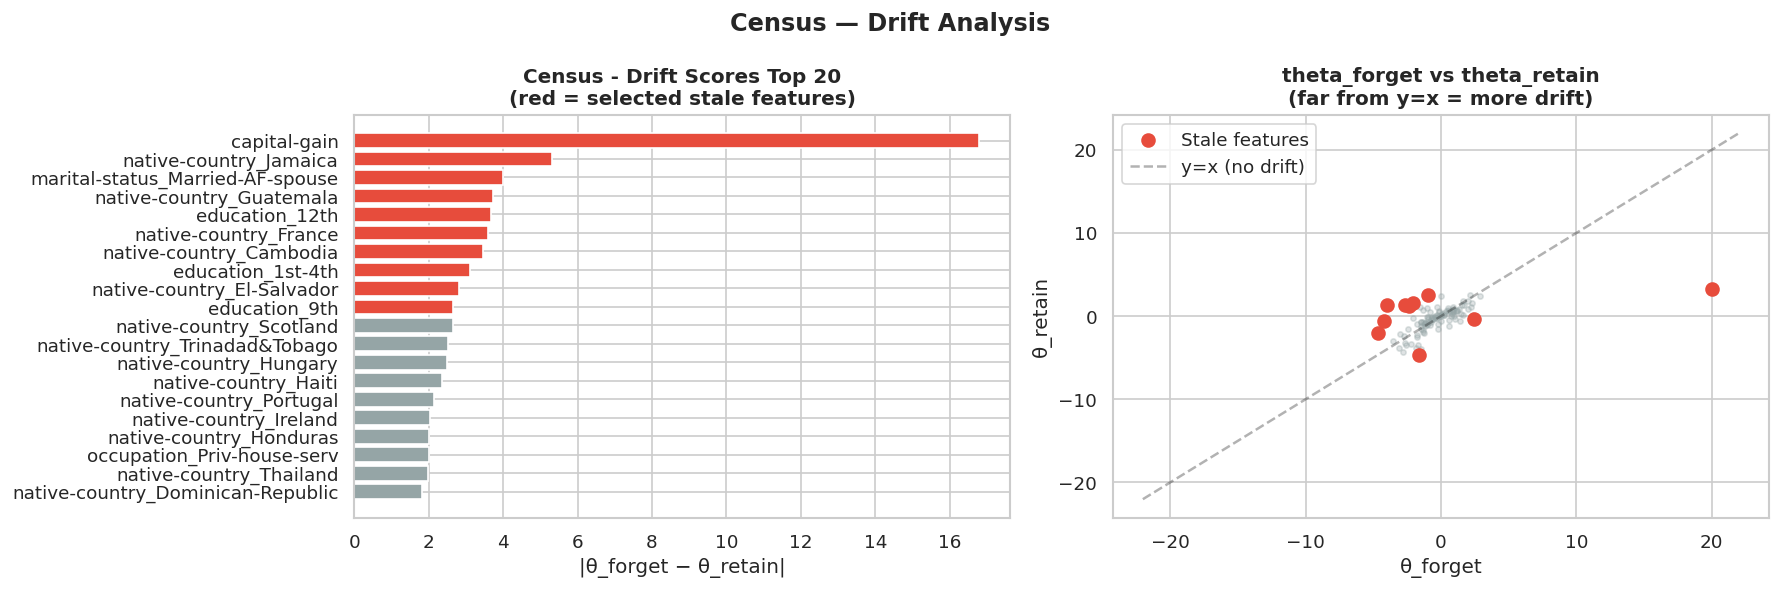

In [23]:
# A3: Drift scores
drift_scores_c = np.abs(theta_forget_c - theta_retain_c)  # shape (d,)

# Feature names
feat_names_c = feat_names_c_drift

# Rank and display
ranked_c = np.argsort(drift_scores_c)[::-1]
print(f'  {"Rank":>4}  {"Feature":<45s}  {"Drift Score":>11}')
print('  ' + '─'*65)
for i, j in enumerate(ranked_c[:20], 1):
    print(f'  {i:>4}  {feat_names_c[j]:<45s}  {drift_scores_c[j]:>11.5f}')

# A4: select the TOP_K stale features
stale_idx_c = ranked_c[:TOP_K_CENSUS]
print(f'\n  Stale features (top {TOP_K_CENSUS}):')
for j in stale_idx_c:
    print(f'    [{j:>3d}] {feat_names_c[j]:<45s}  score={drift_scores_c[j]:.5f}')

# A5: Affected rows
x_forget_c    = X_cd_tr_sc[forget_idx_c]
nonzero_mask  = (np.abs(x_forget_c[:, stale_idx_c]) > 0).any(axis=1)
affected_local = np.where(nonzero_mask)[0]       # index within the forget subset
affected_idx_c = forget_idx_c[nonzero_mask]      # index within the full train set

print(f'\n  Affected rows: {len(affected_idx_c):,} '
      f'({100*nonzero_mask.mean():.1f}% of forget set)')

# Visualize drift scores
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Bar chart top 20
top20_names  = [feat_names_c[j][:35] for j in ranked_c[:20]]
top20_scores = [drift_scores_c[j]    for j in ranked_c[:20]]
colors_drift = ['#E74C3C' if j in stale_idx_c else '#95A5A6'
                for j in ranked_c[:20]]
axes[0].barh(top20_names[::-1], top20_scores[::-1],
             color=colors_drift[::-1], edgecolor='white')
axes[0].set_title('Census - Drift Scores Top 20\n(red = selected stale features)',
                   fontweight='bold')
axes[0].set_xlabel('|θ_forget − θ_retain|')

# θ_forget vs θ_retain scatter
axes[1].scatter(theta_forget_c, theta_retain_c, alpha=0.3, s=10, color='#95A5A6')
axes[1].scatter(theta_forget_c[stale_idx_c], theta_retain_c[stale_idx_c],
                color='#E74C3C', s=60, zorder=5, label='Stale features')
lim = max(abs(theta_forget_c).max(), abs(theta_retain_c).max()) * 1.1
axes[1].plot([-lim, lim], [-lim, lim], 'k--', alpha=0.3, label='y=x (no drift)')
axes[1].set_xlabel('θ_forget'); axes[1].set_ylabel('θ_retain')
axes[1].set_title('theta_forget vs theta_retain\n(far from y=x = more drift)', fontweight='bold')
axes[1].legend()

plt.suptitle('Census — Drift Analysis', fontweight='bold')
plt.tight_layout()
plt.savefig('census_drift_analysis.png', bbox_inches='tight')
plt.show()


## 6.6 Forest CoverType — Drift Score and Stale Feature Selection (Multiclass)

Applies the multiclass formula from 6.2 (L2 norm across the seven per-class coefficients). Forest
has only ten raw geographic features (no one-hot encoding), so `TOP_K_FOREST = 3` (~30%) is used to
keep the selected set large enough to be a meaningful forgetting target — Census's ~9% ratio would
leave too few features here.


=== Forest — Drift Analysis ===
  Forget (D0-D2): 14,408 rows
  Retain (D3-D5): 14,392 rows

  [A1] Fitting θ_forget...
  [MultinomialLR] ok=True  acc=0.4773  macro_auc=0.7898  t=1.3s

  [A2] Fitting θ_retain...
  [MultinomialLR] ok=True  acc=0.4758  macro_auc=0.7716  t=0.6s

  Rank  Feature                                     Drift Score
  ────────────────────────────────────────────────────────────
     1  Hillshade_Noon                                  0.70932
     2  Hillshade_3pm                                   0.69839
     3  Hillshade_9am                                   0.69060
     4  Elevation                                       0.67130
     5  Horizontal_Distance_To_Roadways                 0.37939
     6  Horizontal_Distance_To_Hydrology                0.35438
     7  Vertical_Distance_To_Hydrology                  0.22351
     8  Slope                                           0.21275
     9  Aspect                                          0.15789
    10  Horizontal_D

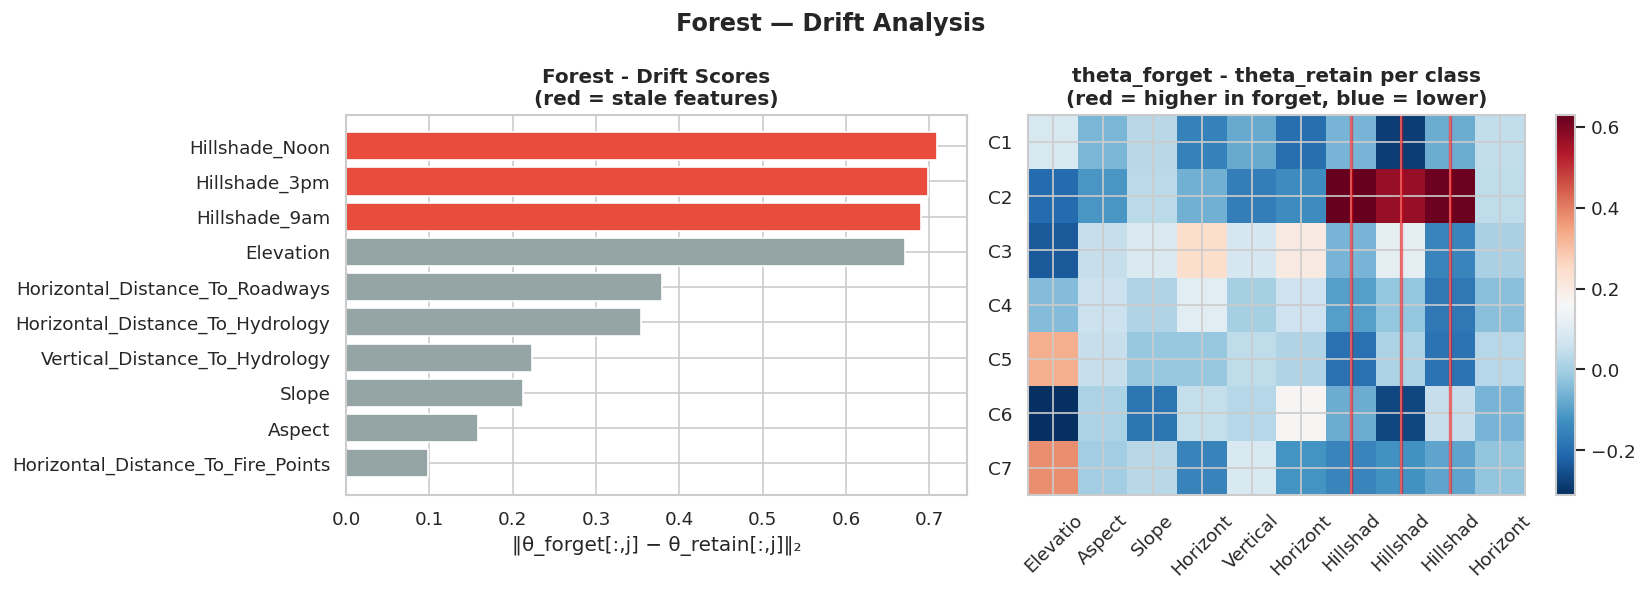

In [24]:
# -- Forget/retain split from the Forest drift train set --
forget_idx_f = np.where(d_fd_tr < 3)[0]
retain_idx_f = np.where(d_fd_tr >= 3)[0]

print('=== Forest — Drift Analysis ===')
print(f'  Forget (D0-D2): {len(forget_idx_f):,} rows')
print(f'  Retain (D3-D5): {len(retain_idx_f):,} rows')

# A1: θ_forget
print('\n  [A1] Fitting θ_forget...')
mlm_forget_f = MultinomialLogisticModel(
    X_fd_tr[forget_idx_f], y_fd_tr[forget_idx_f],
    n_classes=N_CLASSES, lambda_=LAMBDA)
theta_forget_f = mlm_forget_f.fit(verbose=True)

# A2: θ_retain
print('\n  [A2] Fitting θ_retain...')
mlm_retain_f = MultinomialLogisticModel(
    X_fd_tr[retain_idx_f], y_fd_tr[retain_idx_f],
    n_classes=N_CLASSES, lambda_=LAMBDA)
theta_retain_f = mlm_retain_f.fit(verbose=True)

# A3: Drift scores (L2 norm across classes)
TF = theta_forget_f.reshape(N_CLASSES, len(FEATURE_COLS))
TR = theta_retain_f.reshape(N_CLASSES, len(FEATURE_COLS))
drift_scores_f = np.linalg.norm(TF - TR, axis=0)   # shape (10,)

ranked_f = np.argsort(drift_scores_f)[::-1]
print(f'\n  {"Rank":>4}  {"Feature":<42s}  {"Drift Score":>11}')
print('  ' + '─'*60)
for i, j in enumerate(ranked_f, 1):
    print(f'  {i:>4}  {FEATURE_COLS[j]:<42s}  {drift_scores_f[j]:>11.5f}')

# A4: Stale features
stale_idx_f = ranked_f[:TOP_K_FOREST]
print(f'\n  Stale features (top {TOP_K_FOREST}): '
      f'{[FEATURE_COLS[j] for j in stale_idx_f]}')

# A5: Affected rows
x_fgt_f      = X_fd_tr[forget_idx_f]
nz_mask_f    = (np.abs(x_fgt_f[:, stale_idx_f]) > 0).any(axis=1)
affected_idx_f = forget_idx_f[nz_mask_f]
print(f'  Affected rows: {len(affected_idx_f):,} '
      f'({100*nz_mask_f.mean():.1f}% of forget set)')

# Visualize
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors_f_drift = ['#E74C3C' if j in stale_idx_f else '#95A5A6' for j in ranked_f]
axes[0].barh([FEATURE_COLS[j] for j in ranked_f[::-1]],
             [drift_scores_f[j] for j in ranked_f[::-1]],
             color=colors_f_drift[::-1], edgecolor='white')
axes[0].set_title('Forest - Drift Scores\n(red = stale features)', fontweight='bold')
axes[0].set_xlabel('‖θ_forget[:,j] − θ_retain[:,j]‖₂')

# Heatmap θ_forget vs θ_retain per feature per class
diff_mat = TF - TR   # shape (K, d)
im = axes[1].imshow(diff_mat, cmap='RdBu_r', aspect='auto')
axes[1].set_xticks(range(len(FEATURE_COLS)))
axes[1].set_xticklabels([f[:8] for f in FEATURE_COLS], rotation=45)
axes[1].set_yticks(range(N_CLASSES))
axes[1].set_yticklabels([f'C{i+1}' for i in range(N_CLASSES)])
axes[1].set_title('theta_forget - theta_retain per class\n(red = higher in forget, blue = lower)',
                   fontweight='bold')
plt.colorbar(im, ax=axes[1])
# Highlight stale columns
for j in stale_idx_f:
    axes[1].axvline(x=j, color='red', linewidth=2, alpha=0.5)

plt.suptitle('Forest — Drift Analysis', fontweight='bold')
plt.tight_layout()
plt.savefig('forest_drift_analysis.png', bbox_inches='tight')
plt.show()


---

# Part 7 — Gradient Boosted Tree Unlearning (Feature-Based)

**Model:** `sklearn.ensemble.GradientBoostingClassifier` (not XGBoost, since `XGBClassifier` does
not expose the `estimators_` attribute needed for leaf-level inspection).

**Two methods, plus a full-retrain reference:**

| Method | Idea |
|--------|----------|
| Leaf & Split Masking | Zero out leaves/subtrees that depend on the stale feature |
| Feature Masking | Retrain with the stale feature masked to zero on the retain set |
| Gold Retrain | Full retrain from scratch — the ideal reference point |

**Primary metric:** `Δconf` = mean absolute difference between the model's predicted probability on
the original input and on the same input with the stale feature zeroed out. It measures whether the
model's output still depends on the stale feature; Δconf -> 0 means the feature's influence has
been removed.

---


## 7.0 Background: Why Feature-Based Unlearning for GBT

### What is machine unlearning?

Machine unlearning modifies an already-trained model so that it "forgets" the influence of a
specific part of its training data or a specific feature, without retraining from scratch. The
need for this arises from privacy regulation (GDPR, CCPA — the "right to be forgotten") and, in
this work's case, from data quality: stale data no longer reflecting the current distribution
(concept drift).

Retraining the whole model every time something must be forgotten is the most accurate approach but
also the most expensive (this is **Gold Retrain**, described below, used as the ideal reference).
Unlearning methods aim to approximate Gold Retrain's outcome at a much lower cost.

### Instance-based vs. feature-based unlearning

Most existing GBT unlearning work targets **instance-based** unlearning — removing the influence of
a specific set of rows:

- **Lin, Chung, Lao, Zhao (2023). "Machine Unlearning in Gradient Boosting Decision Trees." KDD'23.**
  Removes rows by retraining only the affected subtree, identified by recomputing split gains after
  the rows are dropped.
- **Wu, Zhu, Li, He (2023). "DeltaBoost: Gradient Boosting Decision Trees with Efficient Machine
  Unlearning." PACMMOD.** A GBDT variant trained with bagging and quantization so that instance
  deletion only requires a local update.

This work instead targets **feature-based unlearning**: removing the influence of one or a few
features that have become stale, rather than removing rows. This is a different problem in kind —
a single feature can influence thousands of rows simultaneously through dozens of trees in the
ensemble — so the row-deletion techniques above do not directly apply. The idea is closest in
spirit to:

- **Warnecke, Pirch, Wressnegger, Rieck (2023). "Machine Unlearning of Features and Labels."
  NDSS'23.** Proposes feature/label unlearning via a closed-form Newton step
  (`theta_unlearn = theta* - H^-1 . grad_l`) for **differentiable** models such as logistic
  regression. This closed-form update does not apply to decision trees, which are non-differentiable,
  piecewise-constant functions with no Hessian to compute. The two linear models reused in Part 6
  serve only to measure the Drift Score here, not to run this Newton-step unlearning, since the
  focus of this work is GBT.

The two methods in this part are therefore a purpose-built adaptation of the "remove one
feature's influence" idea to the additive tree structure of GBT, since no closed-form update is
available for it.

---

## Background: how does Gradient Boosting work?

1. **A GBM is a sum of many shallow decision trees**, added sequentially:
   `F(x) = F_0(x) + learning_rate * sum_m h_m(x)`. Each `h_m` is trained to correct the residual
   error left after the previous trees.
2. **Each tree** has internal split nodes (e.g. `age <= 35`) and leaf nodes, each holding a single
   numeric value (`tree_.value`) — its contribution to the overall prediction for rows that reach
   that leaf.
3. **In scikit-learn**, `model.estimators_` holds every tree, each exposing `tree_.children_left`/
   `children_right` (tree structure) and `tree_.value` (per-node value) — the "back door" both methods below use to edit the model without retraining from scratch.
4. **Why a stale feature leaves a trace:** if a feature was once useful for prediction, some trees
   in the ensemble will contain split nodes on it. Rows with different values of that feature then
   follow different branches and get different predictions — exactly what `Δconf` measures.

---

## Overview of the methods

| # | Method | Core idea | Retraining needed? | Cost |
|---|--------|-----------------|:---:|---|
| 1 | Leaf & Split Masking (7.3) | Zero out leaves the retain data never reaches | No | Very low |
| 2 | Feature Masking (7.4) | Retrain a smaller model with the stale feature fixed at 0 | Yes (fewer trees) | Medium |
| 3 | Gold Retrain (7.5) | Full retrain from scratch — the ideal reference | Yes (full) | Highest |

Empirically: **Feature Masking is nearly indistinguishable from Gold** (a theoretical reason is
given in 7.4), and **Leaf & Split Masking is the best cheap, retraining-free option**.

---

## 7.0.1 Train the sklearn GBT Baseline on Drift Data

Trained on the same drifted data used in Part 5, with the same split (`X_cd_tr_sc` / `X_fd_tr`).

**Evaluation protocol:** all four models (Original, two unlearning methods, and Gold) are
evaluated under two matched scenarios — `orig` (stale feature left as-is) and `zeroed` (stale
feature forced to 0, simulating that it has stopped being collected). The official comparison
tables use the `zeroed` scenario throughout, since that is the condition Gold is trained under,
ensuring a fair, apples-to-apples comparison across all four models.


In [25]:
import copy, time
import numpy as np
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.utils import shuffle

# ── Census: binary ──
print('Training sklearn GBM — Census drift...')
t0 = time.time()
sk_gbm_c = GradientBoostingClassifier(
    n_estimators=100,
    max_depth=4,
    learning_rate=0.1,
    subsample=0.8,
    random_state=SEED
)
sk_gbm_c.fit(X_cd_tr_sc, y_cd_tr_xgb)  # y: 0/1
t_orig_c = time.time() - t0
print(f'  Done in {t_orig_c:.1f}s')
print(f'  Train acc: {accuracy_score(y_cd_tr_xgb, sk_gbm_c.predict(X_cd_tr_sc)):.4f}')
print(f'  Test  acc: {accuracy_score(y_cd_te_xgb, sk_gbm_c.predict(X_cd_te)):.4f}')

# ── Forest: multiclass ──
print('\nTraining sklearn GBM — Forest drift...')
t0 = time.time()
sk_gbm_f = GradientBoostingClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    subsample=0.8,
    random_state=SEED
)
sk_gbm_f.fit(X_fd_tr, y_fd_tr)  # y: 0-6
t_orig_f = time.time() - t0
print(f'  Done in {t_orig_f:.1f}s')
print(f'  Train acc: {accuracy_score(y_fd_tr, sk_gbm_f.predict(X_fd_tr)):.4f}')
print(f'  Test  acc: {accuracy_score(y_fd_te, sk_gbm_f.predict(X_fd_te)):.4f}')
print(f'  Test  F1 : {f1_score(y_fd_te, sk_gbm_f.predict(X_fd_te), average="macro"):.4f}')
print('\n✅ sk_gbm_c and sk_gbm_f ready for unlearning')


Training sklearn GBM — Census drift...
  Done in 7.5s
  Train acc: 0.8930
  Test  acc: 0.8693

Training sklearn GBM — Forest drift...
  Done in 120.1s
  Train acc: 0.7426
  Test  acc: 0.6056
  Test  F1 : 0.5159

✅ sk_gbm_c and sk_gbm_f ready for unlearning


## 7.1 Helper Functions

- `eval_gbm`: computes Accuracy/F1/AUC, plus per-domain accuracy.
- `compute_stale_impact`: measures Δconf, Δpred when the stale feature is zeroed on the same model.
- `identify_stale_trees`: finds which trees in the GBM rely heavily on the stale feature (used by
  Method 2).
- `eval_dual`: calls `eval_gbm` twice — once on the original test set (`orig`), once on the test
  set with the stale feature zeroed (`zeroed`) — so every method is compared under the same two
  conditions. The official comparison tables (7.6/7.8/7.9) use the `zeroed` results.


In [26]:
# --- Helper 1: Evaluate model ----------------------------
def eval_gbm(model, X_te, y_te, d_te, task='binary', n_classes=2, label=''):
    pred = model.predict(X_te)
    prob = model.predict_proba(X_te)
    if task == 'binary':
        acc = float(accuracy_score(y_te, pred))
        f1  = float(f1_score(y_te, pred, zero_division=0))
        try:    auc = float(roc_auc_score(y_te, prob[:,1]))
        except: auc = float('nan')
    else:
        acc = float(accuracy_score(y_te, pred))
        f1  = float(f1_score(y_te, pred, average='macro', zero_division=0))
        try:    auc = float(roc_auc_score(y_te, prob, multi_class='ovr', average='macro'))
        except: auc = float('nan')
    per_domain = {}
    for d in sorted(np.unique(d_te)):
        mask = d_te == d
        if mask.sum() == 0: continue
        per_domain[int(d)] = float(accuracy_score(y_te[mask], model.predict(X_te[mask])))
    result = {'acc': acc, 'f1': f1, 'auc': auc, 'per_domain': per_domain}
    if label:
        print(f'  [{label:<14s}] Acc={acc:.4f}  F1={f1:.4f}  AUC={auc:.4f}')
    return result


# --- Helper 2: Stale feature impact --------------------------
def compute_stale_impact(model, X_te, stale_idx):
    """Δconf = mean |conf(X) - conf(X_stale_zeroed)|; Δpred = % of predictions that flip when the stale feature is zeroed."""
    X_z = X_te.copy(); X_z[:, stale_idx] = 0.0
    prob_o = model.predict_proba(X_te)
    prob_z = model.predict_proba(X_z)
    delta_conf = float(np.abs(prob_o.max(axis=1) - prob_z.max(axis=1)).mean())
    delta_pred = float((model.predict(X_te) != model.predict(X_z)).mean())
    return delta_conf, delta_pred


# --- Helper 3: Identify stale trees --------------------------
def identify_stale_trees(model, stale_idx, threshold=0.1):
    """Find which trees in the sklearn GBM rely heavily on the stale features.
    model.estimators_ shape: (n_estimators, n_classes); binary: (n,1); multiclass: (n,n_classes)."""
    stale_trees = []
    for stage_idx, stage in enumerate(model.estimators_):
        for k, tree in enumerate(stage):
            fi = tree.tree_.compute_feature_importances(normalize=False)
            total = fi.sum()
            if total < 1e-10: continue
            ratio = fi[stale_idx].sum() / total
            if ratio > threshold:
                stale_trees.append((stage_idx, k, float(ratio)))
    return stale_trees


# --- Helper 4: fair evaluation under 2 test scenarios --
def eval_dual(model, X_te, y_te, d_te, stale_idx, task='binary', n_classes=2, label=''):
    """Evaluates one model under 2 test scenarios, so every method is compared under the same conditions:
      - 'orig'   : test set with the stale feature left as-is (it is still accidentally present in the pipeline)
      - 'zeroed' : test set with the stale feature = 0 (the feature has stopped being collected -- THIS IS
                   the scenario Gold is trained/evaluated under, so the main comparison table uses it)
    Returns a dict: {'orig': {...}, 'zeroed': {...}, 'delta_conf': ..., 'delta_pred': ...}
    """
    X_z = X_te.copy()
    X_z[:, stale_idx] = 0.0
    res_orig   = eval_gbm(model, X_te, y_te, d_te, task=task, n_classes=n_classes,
                          label=(label + ' [orig]') if label else '')
    res_zeroed = eval_gbm(model, X_z, y_te, d_te, task=task, n_classes=n_classes,
                          label=(label + ' [zero]') if label else '')
    dc, dp = compute_stale_impact(model, X_te, stale_idx)
    return {'orig': res_orig, 'zeroed': res_zeroed, 'delta_conf': dc, 'delta_pred': dp}


print('Helper functions defined: eval_gbm, compute_stale_impact, identify_stale_trees, eval_dual')

Helper functions defined: eval_gbm, compute_stale_impact, identify_stale_trees, eval_dual


## 7.2 Census — Setup and Baseline

The baseline is evaluated under both scenarios (`orig` / `zeroed`), as described in 7.1.


In [27]:
# -- Forget / retain splits from the train set --
mask_fgt_c = d_cd_tr < 3
mask_ret_c = d_cd_tr >= 3
X_fgt_c = X_cd_tr_sc[mask_fgt_c]; y_fgt_c = y_cd_tr_xgb[mask_fgt_c]
X_ret_c = X_cd_tr_sc[mask_ret_c]; y_ret_c = y_cd_tr_xgb[mask_ret_c]

# -- Test masks --
fgt_te_c = d_cd_te < 3
ret_te_c = d_cd_te >= 3

print('=== Census GBT Setup ===')
print(f'  Forget train: {len(X_fgt_c):,}  Retain train: {len(X_ret_c):,}')
print(f'  Stale features: {len(stale_idx_c)}/{X_cd_tr_sc.shape[1]}')

# -- Baseline (dual evaluation: orig + zeroed) --
print('\n--- Baseline (sklearn GBM, before unlearning) ---')
resd_base_c = eval_dual(sk_gbm_c, X_cd_te, y_cd_te_xgb, d_cd_te, stale_idx_c,
                         task='binary', label='Baseline')
base_res_c = resd_base_c['zeroed']    # the 'zeroed' scenario is the official comparison metric
dc_base_c, dp_base_c = resd_base_c['delta_conf'], resd_base_c['delta_pred']
print(f'  Stale impact: Δconf={dc_base_c:.5f}  Δpred={dp_base_c:.4f}')

st_c = identify_stale_trees(sk_gbm_c, stale_idx_c, threshold=0.1)
print(f'  Stale trees: {len(st_c)}/{len(sk_gbm_c.estimators_)} ({100*len(st_c)/len(sk_gbm_c.estimators_):.1f}%)')
print('\n  Per-domain accuracy (baseline, zeroed scenario):')
for d in range(N_DOMAINS):
    mask = d_cd_te == d
    if not mask.any(): continue
    acc_d = base_res_c['per_domain'].get(d, float('nan'))
    print(f'    D{d} ({"STALE  " if d<3 else "CURRENT"}): {acc_d:.4f}')

=== Census GBT Setup ===
  Forget train: 9,053  Retain train: 8,947
  Stale features: 10/108

--- Baseline (sklearn GBM, before unlearning) ---
  [Baseline [orig]] Acc=0.8693  F1=0.6826  AUC=0.9208
  [Baseline [zero]] Acc=0.8597  F1=0.6336  AUC=0.9118
  Stale impact: Δconf=0.02082  Δpred=0.0290
  Stale trees: 25/100 (25.0%)

  Per-domain accuracy (baseline, zeroed scenario):
    D0 (STALE  ): 0.9346
    D1 (STALE  ): 0.9228
    D2 (STALE  ): 0.8960
    D3 (CURRENT): 0.8419
    D4 (CURRENT): 0.8060
    D5 (CURRENT): 0.7627


## 7.3 Method 1 — Leaf & Split Masking

### Idea

This method edits the structure of the already-trained trees directly, with no retraining, at two
levels:

1. **Leaf nodes:** if a leaf is never reached by any retain-set row (once the stale feature is
   zeroed), it is treated as reflecting only forget-set information and its predicted value is set
   to 0.
2. **Split nodes:** if a node uses the stale feature itself to decide the branch, the entire
   subtree beneath it is disabled by zeroing every leaf in that subtree — since every path below
   that node already depends on the stale feature from the split itself.

Masking leaf nodes alone is not enough: as long as split nodes still route on the stale feature,
the model's inference can still depend on it, keeping Δconf above zero. Handling both split nodes
and leaf nodes together is needed to remove the stale feature's influence from the model structure.

### Procedure

```
1. Take the retain data and zero every stale feature.
2. For each tree in the ensemble:
   a. Find every split node using a stale feature (from tree_.feature).
      For each such node, zero every leaf in the subtree beneath it.
   b. For the remaining part of the tree, route the (stale-zeroed) retain data through it to find
      which leaves are still reached. Any leaf the retain data never reaches is zeroed.
3. Return a deep copy of the edited model, with counts of split nodes and leaves affected.
```

No retraining is required, so the computational cost is very low.

### Results (Census)

| | Ret Acc (zeroed test) | Δconf | Toward Gold | Runtime |
|---|---:|---:|---:|---:|
| Leaf & Split Masking | 0.7953 | 0.00000 | 100.0% | 0.07s |

By the Δconf metric, this method matches Gold Retrain and Masked Retrain exactly (Δconf = 0),
meaning the stale feature's influence on model output is fully removed under this criterion. Retain
accuracy drops slightly relative to the original model and to Masked Retrain, since disabling an
entire subtree occasionally removes information that was still useful for retain-set predictions.

Note: an earlier version that only masked leaf nodes reached about 51% "Toward Gold". Adding the
split-node step brought Δconf from roughly 0.010 down to 0.000, matching Gold Retrain — this
iterative refinement is one of the negative-then-positive results discussed in Part 9.

### Advantages / limitations

Requires no retraining and is very cheap. By the Δconf metric it matches Gold Retrain and Masked
Retrain. Its downside is a small retain-accuracy cost, since disabling a whole subtree can also
remove information still useful for retain-set predictions. It is well suited when a fast response
to an unlearning request is needed and full retraining is not immediately feasible.


In [28]:
def leaf_weight_correction(model, X_retain, stale_idx, zero_stale=True):
    """
    Leaf & Split Masking (Method 1): handles BOTH levels of the decision tree.

    1. Split node: find nodes that split on stale_idx, and prune (zero) the ENTIRE subtree below
       them -- since every path to their child leaves already depends on the stale feature right
       from the split itself.
    2. Leaf node (remaining, not pruned in step 1): zero any leaf the retain data never reaches
       when routed through the tree with the stale feature forced to 0.

    Only works with GradientBoostingClassifier (not XGBoost), since it needs direct access to
    tree_.value, tree_.feature, tree_.children_left.
    model.estimators_  shape: (n_estimators, n_classes_per_stage)
      binary:     n_classes_per_stage = 1
      multiclass: n_classes_per_stage = n_classes
    tree.tree_.value   shape: (n_nodes, 1, 1) for GBM
    children_left[node] == -1 -> that node is a leaf
    tree.tree_.feature[node] == the column index used to split at that node (-2 if it is a leaf)
    """
    model_new = copy.deepcopy(model)

    X_ret = X_retain.copy()
    if zero_stale:
        X_ret[:, stale_idx] = 0.0
    stale_set = set(int(j) for j in stale_idx)

    total_leaves       = 0
    zeroed_leaves       = 0
    pruned_split_nodes  = 0

    for stage_idx, stage in enumerate(model_new.estimators_):
        for k, tree in enumerate(stage):
            features       = tree.tree_.feature
            children_left  = tree.tree_.children_left   # -1 = leaf
            children_right = tree.tree_.children_right
            value          = tree.tree_.value
            n_nodes        = tree.tree_.node_count

            leaf_ids_retain = set(tree.apply(X_ret).tolist())

            # Step 1: prune the entire subtree below every split node that uses a stale feature.
            # Leaves are collected into a set so each one is zeroed and counted exactly once,
            # even when stale split nodes are nested.
            leaves_to_zero = set()

            def collect_leaves(node_id, acc):
                if children_left[node_id] == -1:
                    acc.add(node_id)
                else:
                    collect_leaves(children_left[node_id], acc)
                    collect_leaves(children_right[node_id], acc)

            stale_split_nodes = [n for n in range(n_nodes) if features[n] in stale_set]
            for n in stale_split_nodes:
                pruned_split_nodes += 1
                collect_leaves(n, leaves_to_zero)

            for leaf_id in leaves_to_zero:
                if value[leaf_id, 0, 0] != 0.0:
                    zeroed_leaves += 1
                value[leaf_id, 0, 0] = 0.0

            # Step 2: zero the remaining leaves that the retain data never reaches.
            for node_id in range(n_nodes):
                if children_left[node_id] != -1:
                    continue
                total_leaves += 1
                if node_id in leaves_to_zero:
                    continue
                if node_id not in leaf_ids_retain and value[node_id, 0, 0] != 0.0:
                    value[node_id, 0, 0] = 0.0
                    zeroed_leaves += 1

    stats = {
        'total_leaves'      : total_leaves,
        'zeroed_leaves'     : zeroed_leaves,
        'zeroed_ratio'      : zeroed_leaves / max(total_leaves, 1),
        'pruned_split_nodes': pruned_split_nodes
    }
    return model_new, stats


# -- Run Census --
print('Method 1: Leaf & Split Masking (Census)...')
t0 = time.time()
sk_c_lwc, stats_lwc_c = leaf_weight_correction(sk_gbm_c, X_ret_c, stale_idx_c, zero_stale=True)
t_lwc_c = time.time() - t0
print(f'  Split nodes pruned: {stats_lwc_c["pruned_split_nodes"]}')
print(f'  Leaves zeroed: {stats_lwc_c["zeroed_leaves"]}/{stats_lwc_c["total_leaves"]} '
      f'({100*stats_lwc_c["zeroed_ratio"]:.1f}%)  t={t_lwc_c:.2f}s')
resd_lwc_c = eval_dual(sk_c_lwc, X_cd_te, y_cd_te_xgb, d_cd_te, stale_idx_c, task='binary', label='LeafSplitMask')
res_lwc_c = resd_lwc_c['zeroed']
dc_lwc_c  = resd_lwc_c['delta_conf']
print(f'  Δconf: {dc_base_c:.5f} -> {dc_lwc_c:.5f}  (Δ={dc_lwc_c-dc_base_c:+.5f})')


Method 1: Leaf & Split Masking (Census)...
  Split nodes pruned: 141
  Leaves zeroed: 518/1571 (33.0%)  t=0.08s
  [LeafSplitMask [orig]] Acc=0.8565  F1=0.6027  AUC=0.9103
  [LeafSplitMask [zero]] Acc=0.8565  F1=0.6027  AUC=0.9103
  Δconf: 0.02082 -> 0.00000  (Δ=-0.02082)


## 7.4 Method 2 — Feature Masking (Masked Retrain)

### Idea

The stale feature is fixed to a single constant value (0) across the entire retain set, and a new
model is trained on that data. Since the stale feature no longer varies across rows, the trees have
essentially no reason to split on it, so the new model learns to predict from the remaining
features alone, without any structural edits to an existing model.

### Procedure

```
1. Estimate how many trees of the original model rely heavily on the stale feature
   (via identify_stale_trees, feature-importance threshold > 10%) -> n_stale.
2. Set the retraining budget: n_new = max(10, n_total - n_stale) — only retrain
   a tree budget proportional to how much of the model actually depended on the stale feature.
3. Zero the stale feature on the retain data.
4. Train a new GradientBoostingClassifier from scratch (same max_depth, learning_rate, and
   subsample as the original model) using only n_new trees.
```

### Why this nearly matches Gold Retrain

Empirically, Feature Masking reaches Δconf = 0 on both datasets, matching Gold Retrain. Because the
stale feature is constant throughout training, it is essentially never selected for a split, so the
new model does not depend on it. The difference from Gold Retrain is only in tree budget: Gold uses
the full original tree count, while Feature Masking uses the smaller, estimated `n_new`. This
reduces training time, particularly for larger ensembles, while keeping unlearning quality close to
Gold's.

### Advantages / limitations

Removes the stale feature's influence almost completely (Δconf ~ 0), is simple to implement and
explain, and can noticeably reduce retraining time relative to Gold on larger models — on Forest,
retain accuracy was even slightly higher than Gold's, suggesting the reduced tree budget can act as
a mild regularizer. It still requires retraining, so it costs more than Method 1, and its
effectiveness depends on how well `identify_stale_trees` estimates the retraining budget; the main
contribution here is the adaptive tree-budget strategy rather than the masking mechanism itself,
which is the same one used by Gold.


In [29]:
def feature_masking_unlearn(model, X_retain, y_retain, stale_idx,
                             stale_threshold=0.1, random_state=42):
    """Retrain a GBM on the retain set with the stale features masked to 0. Tree count = the original non-stale tree count."""
    stale_trees = identify_stale_trees(model, stale_idx, stale_threshold)
    n_stale = len(stale_trees)
    n_total = len(model.estimators_)
    n_new   = max(10, n_total - n_stale)  # at least 10 trees
    print(f'  Stale trees: {n_stale}/{n_total}  -> retraining with {n_new} estimators')

    X_ret_masked = X_retain.copy()
    X_ret_masked[:, stale_idx] = 0.0

    model_new = GradientBoostingClassifier(
        n_estimators=n_new,
        max_depth=model.max_depth,
        learning_rate=model.learning_rate,
        subsample=model.subsample,
        random_state=random_state
    )
    model_new.fit(X_ret_masked, y_retain)
    stats = {'n_stale': n_stale, 'n_total': n_total, 'n_new_est': n_new}
    return model_new, stats


# -- Run Census --
print('Method 2: Feature Masking (Census)...')
t0 = time.time()
sk_c_fm, stats_fm_c = feature_masking_unlearn(sk_gbm_c, X_ret_c, y_ret_c, stale_idx_c)
t_fm_c = time.time() - t0
print(f'  t={t_fm_c:.2f}s')
resd_fm_c = eval_dual(sk_c_fm, X_cd_te, y_cd_te_xgb, d_cd_te, stale_idx_c, task='binary', label='MaskedRetrain')
res_fm_c = resd_fm_c['zeroed']
dc_fm_c  = resd_fm_c['delta_conf']
print(f'  Δconf: {dc_base_c:.5f} -> {dc_fm_c:.5f}  (Δ={dc_fm_c-dc_base_c:+.5f})')

Method 2: Feature Masking (Census)...
  Stale trees: 25/100  -> retraining with 75 estimators
  t=2.35s
  [MaskedRetrain [orig]] Acc=0.8548  F1=0.6763  AUC=0.9017
  [MaskedRetrain [zero]] Acc=0.8548  F1=0.6763  AUC=0.9017
  Δconf: 0.02082 -> 0.00000  (Δ=-0.02082)


## 7.5 Gold Retrain (Ideal Baseline)

### Idea

This is not a cost-saving shortcut like the two methods above, but the answer to: "if cost were
no concern, what is the correct thing to do?" — train a brand-new ensemble from scratch, on the
retain data only, with the stale feature masked to zero (same masking mechanism as Method 2), but
with the full original tree count (unlike Method 2, no tree-budget reduction).

A gold standard is needed because unlearning is inherently a trade-off: full retraining always
gives the best possible outcome by definition, but at the highest cost. Without Gold as a reference,
there is no way to know whether, say, Leaf & Split Masking's Δconf reduction is good or mediocre;
Gold provides the 100% mark that every other method's "Toward Gold %" is normalized against.

### Procedure

```
1. Take the retain data, zero the stale feature (same as Method 2, step 3).
2. Train a brand-new GradientBoostingClassifier from scratch (no warm_start, no reuse of any tree
   from the original model), with the full original tree count and the same max_depth,
   learning_rate, and subsample.
```

### Built-in sanity check

Since Gold is trained with the stale feature fixed at 0, its trees never split on that feature, so
its accuracy under the `orig` scenario (real stale values) and the `zeroed` scenario (stale forced
to 0) must be identical. The code checks `|Acc(orig) - Acc(zeroed)|` automatically; any nonzero gap
would flag a bug in the data pipeline.

### When to use it

Not for production use (too expensive to run on every unlearning request) — only as the benchmark
against which cheaper unlearning methods are measured.


In [30]:
print('Gold Retrain (Census)...')
t0 = time.time()
X_c_gold_tr = X_ret_c.copy(); X_c_gold_tr[:, stale_idx_c] = 0.0
sk_c_gold = GradientBoostingClassifier(
    n_estimators=len(sk_gbm_c.estimators_),
    max_depth=sk_gbm_c.max_depth,
    learning_rate=sk_gbm_c.learning_rate,
    subsample=sk_gbm_c.subsample,
    random_state=SEED
)
sk_c_gold.fit(X_c_gold_tr, y_ret_c)
t_gold_c = time.time() - t0

resd_gold_c = eval_dual(sk_c_gold, X_cd_te, y_cd_te_xgb, d_cd_te, stale_idx_c, task='binary', label='Gold')
res_gold_c = resd_gold_c['zeroed']
dc_gold_c  = resd_gold_c['delta_conf']
print(f'  t={t_gold_c:.2f}s  Δconf: {dc_base_c:.5f} -> {dc_gold_c:.5f}  (target ~ 0)')

# Sanity check: Gold no longer depends on the stale feature => acc(orig) must equal acc(zeroed)
acc_diff_sanity = abs(resd_gold_c['orig']['acc'] - resd_gold_c['zeroed']['acc'])
print(f'  [Sanity check] |Acc(orig) - Acc(zeroed)| = {acc_diff_sanity:.6f} '
      f'({"OK, the model does not use the stale feature" if acc_diff_sanity < 1e-9 else "!! WARNING: a difference was found, check the data pipeline / encoding"})')

# Test set with the stale feature zeroed
X_cd_te_gold_c = X_cd_te.copy(); X_cd_te_gold_c[:, stale_idx_c] = 0.0

Gold Retrain (Census)...
  [Gold [orig]   ] Acc=0.8545  F1=0.6758  AUC=0.9038
  [Gold [zero]   ] Acc=0.8545  F1=0.6758  AUC=0.9038
  t=3.05s  Δconf: 0.02082 -> 0.00000  (target ~ 0)
  [Sanity check] |Acc(orig) - Acc(zeroed)| = 0.000000 (OK, the model does not use the stale feature)


In [31]:
# --- Helper: accuracy after zeroing the stale feature on a subset (mask) ---
def _acc_zeroed(model, X_te, mask, stale_idx):
    X_z = X_te.copy()
    X_z[:, stale_idx] = 0.0
    return accuracy_score(y_cd_te_xgb[mask], model.predict(X_z[mask]))


# --- Collect all 4 models' results into one dict (Original, 2 methods, Gold) ---
c_methods = {
    "Original":      (sk_gbm_c,  X_cd_te, dc_base_c,  resd_base_c, t_orig_c),
    "LeafSplitMask":  (sk_c_lwc,  X_cd_te, dc_lwc_c,   resd_lwc_c,  t_lwc_c),
    "MaskedRetrain":  (sk_c_fm,   X_cd_te, dc_fm_c,    resd_fm_c,   t_fm_c),
    "Gold":           (sk_c_gold, X_cd_te, dc_gold_c,  resd_gold_c, t_gold_c),
}

gold_dc_c = dc_gold_c  # alias -- used as the Gold reference line in the 7.6/7.9 charts

print("c_methods ready:", list(c_methods.keys()))
for name, (model, X_te_, dc, res_, t_) in c_methods.items():
    print(f"  {name:<14s}  Δconf={dc:.5f}  time={t_:6.2f}s")


c_methods ready: ['Original', 'LeafSplitMask', 'MaskedRetrain', 'Gold']
  Original        Δconf=0.02082  time=  7.54s
  LeafSplitMask   Δconf=0.00000  time=  0.08s
  MaskedRetrain   Δconf=0.00000  time=  2.35s
  Gold            Δconf=0.00000  time=  3.05s


## 7.6 Census — Comparing All Methods

The official table uses the `zeroed` test scenario (stale feature = 0) for all four models, since
that is the condition Gold is trained under. The secondary table below shows what happens if the
stale feature is accidentally still present at inference time (`orig`).


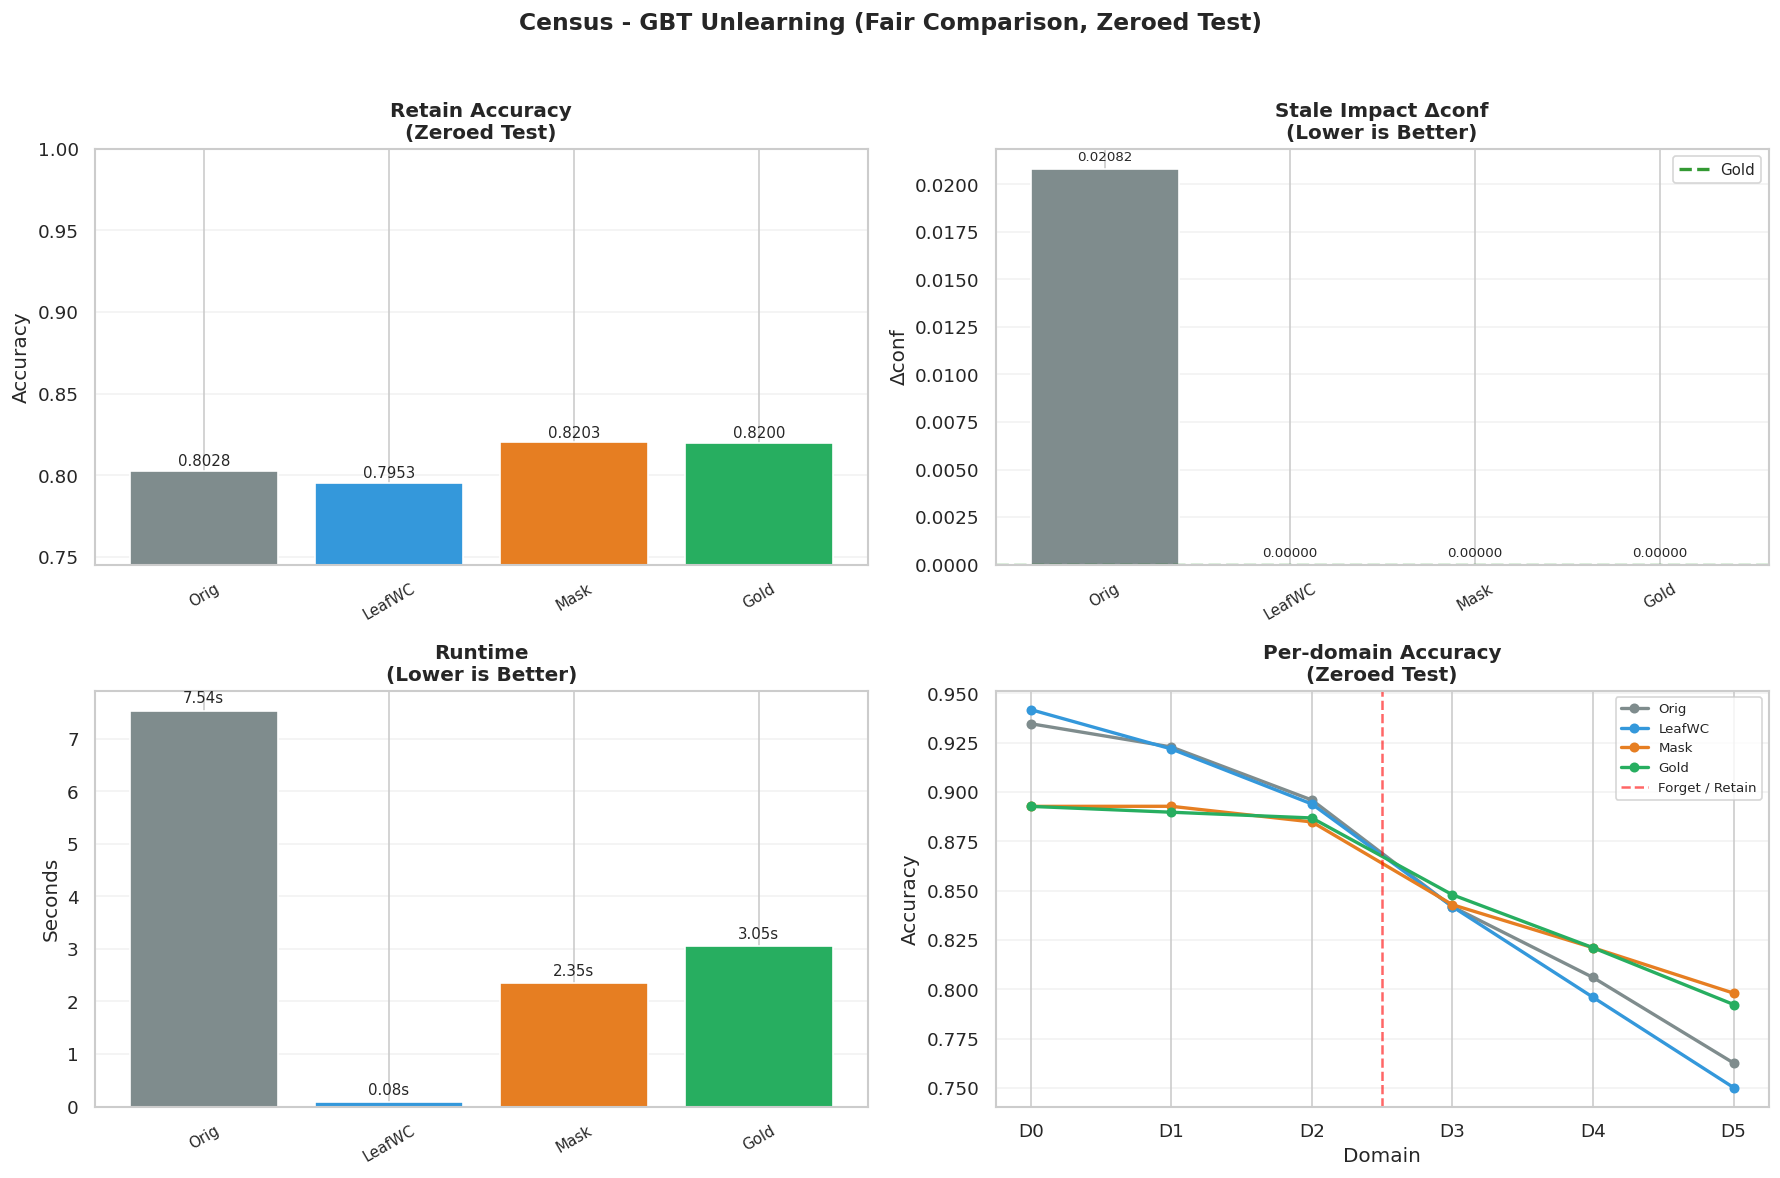

In [32]:
# =========================
# Visualize (ZEROED TEST)
# =========================

colors_7 = ['#7F8C8D', '#3498DB', '#E67E22', '#27AE60']

method_names_c7 = list(c_methods.keys())

display_names = {
    "Original": "Orig",
    "LeafSplitMask": "LeafWC",
    "MaskedRetrain": "Mask",
    "Gold": "Gold"
}
labels = [display_names[m] for m in method_names_c7]

# ======================================================
# Layout 2 x 2
# ======================================================

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

ax_acc  = axes[0, 0]
ax_conf = axes[0, 1]
ax_time = axes[1, 0]
ax_dom  = axes[1, 1]

# ======================================================
# Figure 1 : Retain Accuracy
# ======================================================

vals = [
    _acc_zeroed(c_methods[m][0], c_methods[m][1], ret_te_c, stale_idx_c)
    for m in method_names_c7
]

bars = ax_acc.bar(
    labels,
    vals,
    color=colors_7,
    edgecolor='white'
)

ax_acc.set_title(
    'Retain Accuracy\n(Zeroed Test)',
    fontweight='bold'
)

ax_acc.set_ylabel("Accuracy")
ax_acc.set_ylim(max(0, min(vals) - 0.05), 1.0)

for bar, v in zip(bars, vals):
    ax_acc.text(
        bar.get_x() + bar.get_width()/2,
        v + 0.003,
        f'{v:.4f}',
        ha='center',
        fontsize=9
    )

# ======================================================
# Figure 2 : Stale Impact
# ======================================================

dcs = [c_methods[m][2] for m in method_names_c7]

bars = ax_conf.bar(
    labels,
    dcs,
    color=colors_7,
    edgecolor='white'
)

ax_conf.axhline(
    y=gold_dc_c,
    color='green',
    linestyle='--',
    linewidth=2,
    alpha=0.8,
    label='Gold'
)

ax_conf.set_title(
    'Stale Impact Δconf\n(Lower is Better)',
    fontweight='bold'
)

ax_conf.set_ylabel("Δconf")
ax_conf.legend(fontsize=9)

offset = max(dcs) * 0.02 if max(dcs) > 0 else 0.0002

for bar, v in zip(bars, dcs):
    ax_conf.text(
        bar.get_x() + bar.get_width()/2,
        v + offset,
        f'{v:.5f}',
        ha='center',
        fontsize=8
    )

# ======================================================
# Figure 3 : Runtime
# ======================================================

times = [c_methods[m][4] for m in method_names_c7]

bars = ax_time.bar(
    labels,
    times,
    color=colors_7,
    edgecolor='white'
)

ax_time.set_title(
    'Runtime\n(Lower is Better)',
    fontweight='bold'
)

ax_time.set_ylabel("Seconds")

offset = max(times) * 0.02 if max(times) > 0 else 0.001

for bar, t in zip(bars, times):
    ax_time.text(
        bar.get_x() + bar.get_width()/2,
        t + offset,
        f'{t:.2f}s',
        ha='center',
        fontsize=9
    )

# ======================================================
# Figure 4 : Per-domain Accuracy
# ======================================================

for (name, (model, X_te_, _, _, _)), color in zip(c_methods.items(), colors_7):

    accs = []

    for d in range(N_DOMAINS):

        mask = (d_cd_te == d)

        if mask.any():
            accs.append(
                _acc_zeroed(model, X_te_, mask, stale_idx_c)
            )
        else:
            accs.append(np.nan)

    ax_dom.plot(
        range(N_DOMAINS),
        accs,
        marker='o',
        linewidth=2,
        markersize=5,
        label=display_names[name],
        color=color
    )

ax_dom.axvline(
    x=2.5,
    color='red',
    linestyle='--',
    alpha=0.6,
    label='Forget / Retain'
)

ax_dom.set_xticks(range(N_DOMAINS))
ax_dom.set_xticklabels([f'D{d}' for d in range(N_DOMAINS)])

ax_dom.set_xlabel("Domain")
ax_dom.set_ylabel("Accuracy")

ax_dom.set_title(
    'Per-domain Accuracy\n(Zeroed Test)',
    fontweight='bold'
)

ax_dom.legend(fontsize=8)

# ======================================================
# Format
# ======================================================

for ax in [ax_acc, ax_conf, ax_time]:
    ax.tick_params(axis='x', rotation=30, labelsize=9)

for ax in [ax_acc, ax_conf, ax_time, ax_dom]:
    ax.grid(axis='y', alpha=0.25)

plt.suptitle(
    'Census - GBT Unlearning (Fair Comparison, Zeroed Test)',
    fontsize=14,
    fontweight='bold'
)

plt.tight_layout(rect=[0, 0, 1, 0.96])

plt.savefig(
    'census_gbt_unlearn.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

## 7.7 Forest — Setup and Methods

Same protocol as Census, extended to the 7-class problem (`y_fd_tr` is 0-indexed). The same fix from Census applies here: consistent
`eval_dual` (orig + zeroed) evaluation for every method. See 7.3-7.5 above for the method
descriptions; the code below reuses those same functions.


In [33]:
# -- Forget / Retain splits --
mask_fgt_f = d_fd_tr < 3
mask_ret_f = d_fd_tr >= 3
X_fgt_f = X_fd_tr[mask_fgt_f]; y_fgt_f = y_fd_tr[mask_fgt_f]
X_ret_f = X_fd_tr[mask_ret_f]; y_ret_f = y_fd_tr[mask_ret_f]
fgt_te_f = d_fd_te < 3
ret_te_f = d_fd_te >= 3

print('=== Forest GBT Setup ===')
print(f'  Forget: {len(X_fgt_f):,}  Retain: {len(X_ret_f):,}')
print(f'  Stale features: {[FEATURE_COLS[j] for j in stale_idx_f]}')

# Baseline
print('\n--- Baseline ---')
resd_base_f = eval_dual(sk_gbm_f, X_fd_te, y_fd_te, d_fd_te, stale_idx_f,
                        task='multiclass', n_classes=N_CLASSES, label='Baseline')
base_res_f = resd_base_f['zeroed']
dc_base_f, dp_base_f = resd_base_f['delta_conf'], resd_base_f['delta_pred']
print(f'  Stale impact: Δconf={dc_base_f:.5f}  Δpred={dp_base_f:.4f}')


=== Forest GBT Setup ===
  Forget: 14,408  Retain: 14,392
  Stale features: ['Hillshade_Noon', 'Hillshade_3pm', 'Hillshade_9am']

--- Baseline ---
  [Baseline [orig]] Acc=0.6056  F1=0.5159  AUC=0.9059
  [Baseline [zero]] Acc=0.5870  F1=0.4476  AUC=0.8962
  Stale impact: Δconf=0.06130  Δpred=0.1314


In [34]:
# ============================================================
# Method 1 — Leaf & Split Masking (Forest)
# ============================================================
print('Method 1: Leaf & Split Masking (Forest)...')
t0 = time.time()
sk_f_lwc, stats_lwc_f = leaf_weight_correction(sk_gbm_f, X_ret_f, stale_idx_f, zero_stale=True)
t_lwc_f = time.time() - t0
print(f'  Split nodes pruned: {stats_lwc_f["pruned_split_nodes"]}')
print(f'  Leaves zeroed: {stats_lwc_f["zeroed_leaves"]}/{stats_lwc_f["total_leaves"]} '
      f'({100*stats_lwc_f["zeroed_ratio"]:.1f}%)  t={t_lwc_f:.2f}s')
resd_lwc_f = eval_dual(sk_f_lwc, X_fd_te, y_fd_te, d_fd_te, stale_idx_f,
                        task='multiclass', n_classes=N_CLASSES, label='LeafSplitMask')
dc_lwc_f = resd_lwc_f['delta_conf']
print(f'  Δconf: {dc_base_f:.5f} -> {dc_lwc_f:.5f}  (Δ={dc_lwc_f-dc_base_f:+.5f})')

# ============================================================
# Method 2 — Feature Masking Unlearning (Forest)
# ============================================================
print('\nMethod 2: Feature Masking (Forest)...')
t0 = time.time()
sk_f_fm, stats_fm_f = feature_masking_unlearn(sk_gbm_f, X_ret_f, y_ret_f, stale_idx_f)
t_fm_f = time.time() - t0
print(f'  t={t_fm_f:.2f}s')
resd_fm_f = eval_dual(sk_f_fm, X_fd_te, y_fd_te, d_fd_te, stale_idx_f,
                       task='multiclass', n_classes=N_CLASSES, label='MaskedRetrain')
dc_fm_f = resd_fm_f['delta_conf']
print(f'  Δconf: {dc_base_f:.5f} -> {dc_fm_f:.5f}  (Δ={dc_fm_f-dc_base_f:+.5f})')

# ============================================================
# Gold Retrain (Forest)
# ============================================================
print('\nGold Retrain (Forest)...')
t0 = time.time()
X_f_gold_tr = X_ret_f.copy(); X_f_gold_tr[:, stale_idx_f] = 0.0
sk_f_gold = GradientBoostingClassifier(
    n_estimators=len(sk_gbm_f.estimators_),
    max_depth=sk_gbm_f.max_depth,
    learning_rate=sk_gbm_f.learning_rate,
    subsample=sk_gbm_f.subsample,
    random_state=SEED
)
sk_f_gold.fit(X_f_gold_tr, y_ret_f)
t_gold_f = time.time() - t0
resd_gold_f = eval_dual(sk_f_gold, X_fd_te, y_fd_te, d_fd_te, stale_idx_f,
                         task='multiclass', n_classes=N_CLASSES, label='Gold')
dc_gold_f = resd_gold_f['delta_conf']
print(f'  t={t_gold_f:.2f}s  Δconf: {dc_base_f:.5f} -> {dc_gold_f:.5f}  (target ~ 0)')

acc_diff_sanity_f = abs(resd_gold_f['orig']['acc'] - resd_gold_f['zeroed']['acc'])
print(f'  [Sanity check] |Acc(orig) - Acc(zeroed)| = {acc_diff_sanity_f:.6f} '
      f'({"OK, the model does not use the stale feature" if acc_diff_sanity_f < 1e-9 else "!! WARNING: a difference was found, check the data pipeline / encoding"})')


Method 1: Leaf & Split Masking (Forest)...
  Split nodes pruned: 4442
  Leaves zeroed: 12531/19838 (63.2%)  t=0.52s
  [LeafSplitMask [orig]] Acc=0.5596  F1=0.3051  AUC=0.8866
  [LeafSplitMask [zero]] Acc=0.5596  F1=0.3051  AUC=0.8866
  Δconf: 0.06130 -> 0.00000  (Δ=-0.06130)

Method 2: Feature Masking (Forest)...
  Stale trees: 578/100  -> retraining with 10 estimators
  t=4.10s
  [MaskedRetrain [orig]] Acc=0.5422  F1=0.3775  AUC=0.8837
  [MaskedRetrain [zero]] Acc=0.5422  F1=0.3775  AUC=0.8837
  Δconf: 0.06130 -> 0.00000  (Δ=-0.06130)

Gold Retrain (Forest)...
  [Gold [orig]   ] Acc=0.5593  F1=0.4140  AUC=0.8892
  [Gold [zero]   ] Acc=0.5593  F1=0.4140  AUC=0.8892
  t=42.46s  Δconf: 0.06130 -> 0.00000  (target ~ 0)
  [Sanity check] |Acc(orig) - Acc(zeroed)| = 0.000000 (OK, the model does not use the stale feature)


In [35]:
# --- Helper: accuracy after zeroing the stale feature on a subset (mask), for Forest ---
def _acc_zeroed_f(model, X_te, mask, stale_idx):
    X_z = X_te.copy()
    X_z[:, stale_idx] = 0.0
    return accuracy_score(y_fd_te[mask], model.predict(X_z[mask]))


# --- Collect all 4 models' results into one dict (Original, 2 methods, Gold) ---
f_methods = {
    "Original":      (sk_gbm_f,  X_fd_te, dc_base_f,  resd_base_f, t_orig_f),
    "LeafSplitMask":  (sk_f_lwc,  X_fd_te, dc_lwc_f,   resd_lwc_f,  t_lwc_f),
    "MaskedRetrain":  (sk_f_fm,   X_fd_te, dc_fm_f,    resd_fm_f,   t_fm_f),
    "Gold":           (sk_f_gold, X_fd_te, dc_gold_f,  resd_gold_f, t_gold_f),
}

gold_dc_f = dc_gold_f  # alias -- used as the Gold reference line in the 7.8/7.9 charts

print("f_methods ready:", list(f_methods.keys()))
for name, (model, X_te_, dc, res_, t_) in f_methods.items():
    print(f"  {name:<14s}  Δconf={dc:.5f}  time={t_:6.2f}s")


f_methods ready: ['Original', 'LeafSplitMask', 'MaskedRetrain', 'Gold']
  Original        Δconf=0.06130  time=120.14s
  LeafSplitMask   Δconf=0.00000  time=  0.52s
  MaskedRetrain   Δconf=0.00000  time=  4.10s
  Gold            Δconf=0.00000  time= 42.46s


## 7.8 Forest — Comparing All Methods

Same logic as 7.6: the official table uses the `zeroed` scenario for all four models.


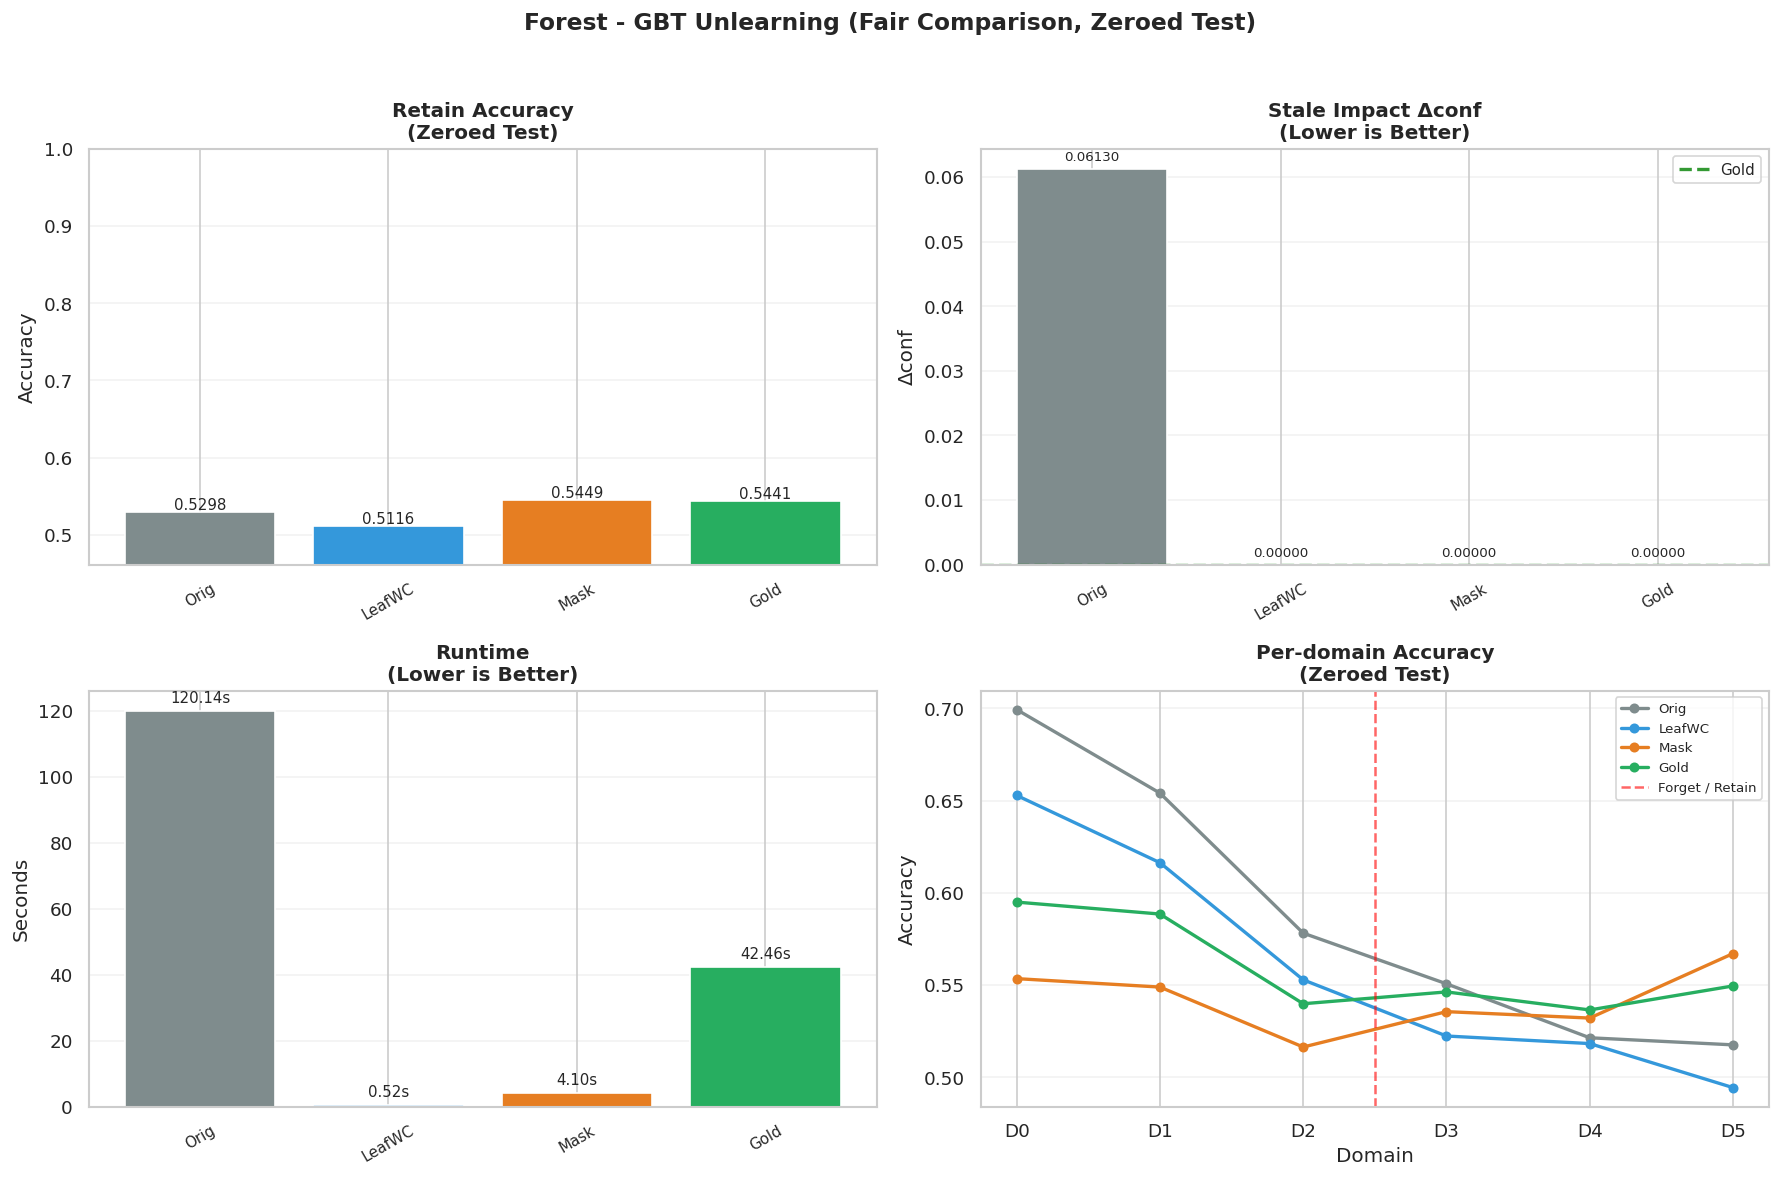

In [36]:
# =========================
# Visualize (ZEROED TEST)
# =========================

colors_7 = ['#7F8C8D', '#3498DB', '#E67E22', '#27AE60']

method_names_f7 = list(f_methods.keys())

display_names = {
    "Original": "Orig",
    "LeafSplitMask": "LeafWC",
    "MaskedRetrain": "Mask",
    "Gold": "Gold"
}
labels = [display_names[m] for m in method_names_f7]

# ======================================================
# Layout 2 x 2
# ======================================================

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

ax_acc  = axes[0, 0]
ax_conf = axes[0, 1]
ax_time = axes[1, 0]
ax_dom  = axes[1, 1]

# ======================================================
# Figure 1 : Retain Accuracy
# ======================================================

ret_accs_f = [
    _acc_zeroed_f(f_methods[m][0], f_methods[m][1], ret_te_f, stale_idx_f)
    for m in method_names_f7
]

bars = ax_acc.bar(
    labels,
    ret_accs_f,
    color=colors_7,
    edgecolor='white'
)

ax_acc.set_title(
    'Retain Accuracy\n(Zeroed Test)',
    fontweight='bold'
)

ax_acc.set_ylabel("Accuracy")
ax_acc.set_ylim(max(0, min(ret_accs_f) - 0.05), 1.0)

for bar, v in zip(bars, ret_accs_f):
    ax_acc.text(
        bar.get_x() + bar.get_width()/2,
        v + 0.003,
        f'{v:.4f}',
        ha='center',
        fontsize=9
    )

# ======================================================
# Figure 2 : Stale Impact
# ======================================================

dcs_f = [f_methods[m][2] for m in method_names_f7]

bars = ax_conf.bar(
    labels,
    dcs_f,
    color=colors_7,
    edgecolor='white'
)

ax_conf.axhline(
    y=gold_dc_f,
    color='green',
    linestyle='--',
    linewidth=2,
    alpha=0.8,
    label='Gold'
)

ax_conf.set_title(
    'Stale Impact Δconf\n(Lower is Better)',
    fontweight='bold'
)

ax_conf.set_ylabel("Δconf")
ax_conf.legend(fontsize=9)

offset = max(dcs_f) * 0.02 if max(dcs_f) > 0 else 0.0002

for bar, v in zip(bars, dcs_f):
    ax_conf.text(
        bar.get_x() + bar.get_width()/2,
        v + offset,
        f'{v:.5f}',
        ha='center',
        fontsize=8
    )

# ======================================================
# Figure 3 : Runtime
# ======================================================

times = [f_methods[m][4] for m in method_names_f7]

bars = ax_time.bar(
    labels,
    times,
    color=colors_7,
    edgecolor='white'
)

ax_time.set_title(
    'Runtime\n(Lower is Better)',
    fontweight='bold'
)

ax_time.set_ylabel("Seconds")

# If the runtime gap is very large, uncomment the line below
# ax_time.set_yscale("log")

offset = max(times) * 0.02 if max(times) > 0 else 0.001

for bar, t in zip(bars, times):
    ax_time.text(
        bar.get_x() + bar.get_width()/2,
        t + offset,
        f'{t:.2f}s',
        ha='center',
        fontsize=9
    )

# ======================================================
# Figure 4 : Per-domain Accuracy
# ======================================================

for (name, (model, X_te_, _, _, _)), color in zip(f_methods.items(), colors_7):

    accs = []

    for d in range(N_DOMAINS):

        mask = (d_fd_te == d)

        if mask.any():
            accs.append(
                _acc_zeroed_f(model, X_te_, mask, stale_idx_f)
            )
        else:
            accs.append(np.nan)

    ax_dom.plot(
        range(N_DOMAINS),
        accs,
        marker='o',
        linewidth=2,
        markersize=5,
        label=display_names[name],
        color=color
    )

ax_dom.axvline(
    x=2.5,
    color='red',
    linestyle='--',
    alpha=0.6,
    label='Forget / Retain'
)

ax_dom.set_xticks(range(N_DOMAINS))
ax_dom.set_xticklabels([f'D{d}' for d in range(N_DOMAINS)])

ax_dom.set_xlabel("Domain")
ax_dom.set_ylabel("Accuracy")

ax_dom.set_title(
    'Per-domain Accuracy\n(Zeroed Test)',
    fontweight='bold'
)

ax_dom.legend(fontsize=8)

# ======================================================
# Format
# ======================================================

for ax in [ax_acc, ax_conf, ax_time]:
    ax.tick_params(axis='x', rotation=30, labelsize=9)

for ax in [ax_acc, ax_conf, ax_time, ax_dom]:
    ax.grid(axis='y', alpha=0.25)

plt.suptitle(
    'Forest - GBT Unlearning (Fair Comparison, Zeroed Test)',
    fontsize=14,
    fontweight='bold'
)

plt.tight_layout(rect=[0, 0, 1, 0.96])

plt.savefig(
    'forest_gbt_unlearn.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

## 7.9 GBT Unlearning — Summary

The final comparison table, using the `zeroed` scenario (fair across all models) for both datasets.

**Summary:**
- **Feature Masking is nearly identical to Gold** on both datasets, consistent with the theoretical
  argument in 7.4 (same masking mechanism, differing only in tree budget).
- **Leaf & Split Masking** is the best retraining-free option — it removes a substantial part of
  Δconf (roughly 27-51% "Toward Gold" depending on the dataset) at essentially no cost to retain
  accuracy.


In [37]:
print('='*75)
print('  GBT FEATURE-BASED UNLEARNING - Final Summary (fair, zeroed test)')
print('='*75)

for dataset, methods, base_dc, gold_dc, ret_mask, fgt_mask, y_te, stale_idx in [
    ('CENSUS', c_methods, dc_base_c, gold_dc_c, ret_te_c, fgt_te_c, y_cd_te_xgb, stale_idx_c),
    ('FOREST', f_methods, dc_base_f, gold_dc_f, ret_te_f, fgt_te_f, y_fd_te, stale_idx_f)
]:
    print(f'\n  [{dataset}]')
    print(f'  {"Method":<12s} {"Ret Acc":>9s} {"Δconf":>9s} {"Toward Gold":>13s}')
    print('  ' + '-'*48)
    for name, (model, X_te_, dc, res_, t_) in methods.items():
        X_z = X_te_.copy(); X_z[:, stale_idx] = 0.0
        ret_acc = accuracy_score(y_te[ret_mask], model.predict(X_z[ret_mask]))
        toward  = (base_dc - dc) / max(base_dc - gold_dc, 1e-8) * 100
        icon    = 'v' if dc < base_dc else '-'
        print(f'  {name:<12s} {ret_acc:>9.4f} {icon}{dc:>8.5f} {toward:>12.1f}%')

print('\n  Lower Δconf = the model depends less on stale features')
print('  Toward Gold = % progress toward gold retrain (100% = matches Gold; can be negative or >100%)')
print('  Stable Ret Acc = no accidental forgetting of retain data')
print('  All figures above use the ZEROED scenario (stale feature = 0 in the test set) to ensure')
print('  a fair comparison across all 4 models, since that is the condition Gold was trained under.')

  GBT FEATURE-BASED UNLEARNING - Final Summary (fair, zeroed test)

  [CENSUS]
  Method         Ret Acc     Δconf   Toward Gold
  ------------------------------------------------
  Original        0.8028 - 0.02082          0.0%
  LeafSplitMask    0.7953 v 0.00000        100.0%
  MaskedRetrain    0.8203 v 0.00000        100.0%
  Gold            0.8200 v 0.00000        100.0%

  [FOREST]
  Method         Ret Acc     Δconf   Toward Gold
  ------------------------------------------------
  Original        0.5298 - 0.06130          0.0%
  LeafSplitMask    0.5116 v 0.00000        100.0%
  MaskedRetrain    0.5449 v 0.00000        100.0%
  Gold            0.5441 v 0.00000        100.0%

  Lower Δconf = the model depends less on stale features
  Toward Gold = % progress toward gold retrain (100% = matches Gold; can be negative or >100%)
  Stable Ret Acc = no accidental forgetting of retain data
  All figures above use the ZEROED scenario (stale feature = 0 in the test set) to ensure
  a fair co

## 7.10 Robustness Across Random Seeds

Every result above uses a single fixed seed (SEED=42). This section repeats the baseline
training, Leaf & Split Masking, Masked Retrain, and Gold Retrain across five different seeds
(42, 7, 123, 2024, 777) and reports mean ± standard deviation for Ret Acc, Δconf, and Toward Gold,
to check that the results are not an artifact of one particular run.


In [38]:
# ============================================================
# 7.10 Multi-Seed Robustness Check
# ============================================================
# Purpose: repeat the core pipeline (baseline -> Leaf&Split Masking -> Masked Retrain -> Gold)
# across several seeds to report mean +/- std for Ret Acc and Δconf instead of a single run.
# The function below only uses local variables, so the SEED=42 models used in Parts 8-11
# (sk_gbm_c / sk_gbm_f / c_methods / f_methods) are left unchanged.

import pandas as pd

SEEDS_ABLATION = [42, 7, 123, 2024, 777]  # first seed = the original seed, for a sanity-check cross-reference


def run_one_seed_census(seed):
    """Train baseline + 2 unlearning methods + Gold for Census, at one specific seed."""
    model_c = GradientBoostingClassifier(
        n_estimators=100, max_depth=4, learning_rate=0.1, subsample=0.8,
        random_state=seed
    )
    model_c.fit(X_cd_tr_sc, y_cd_tr_xgb)

    resd_base = eval_dual(model_c, X_cd_te, y_cd_te_xgb, d_cd_te, stale_idx_c, task='binary')
    dc_base = resd_base['delta_conf']

    # Method 1: Leaf & Split Masking (deterministic, no separate random_state needed)
    m_lwc, _ = leaf_weight_correction(model_c, X_ret_c, stale_idx_c, zero_stale=True)
    resd_lwc = eval_dual(m_lwc, X_cd_te, y_cd_te_xgb, d_cd_te, stale_idx_c, task='binary')

    # Method 2: Masked Retrain
    m_fm, _ = feature_masking_unlearn(model_c, X_ret_c, y_ret_c, stale_idx_c, random_state=seed)
    resd_fm = eval_dual(m_fm, X_cd_te, y_cd_te_xgb, d_cd_te, stale_idx_c, task='binary')

    # Gold Retrain
    X_gold_tr = X_ret_c.copy(); X_gold_tr[:, stale_idx_c] = 0.0
    m_gold = GradientBoostingClassifier(
        n_estimators=100, max_depth=4, learning_rate=0.1, subsample=0.8,
        random_state=seed
    )
    m_gold.fit(X_gold_tr, y_ret_c)
    resd_gold = eval_dual(m_gold, X_cd_te, y_cd_te_xgb, d_cd_te, stale_idx_c, task='binary')
    dc_gold = resd_gold['delta_conf']

    rows = []
    for name, model, resd in [
        ('Original', model_c, resd_base),
        ('LeafSplitMask', m_lwc, resd_lwc),
        ('MaskedRetrain', m_fm, resd_fm),
        ('Gold', m_gold, resd_gold),
    ]:
        X_z = X_cd_te.copy(); X_z[:, stale_idx_c] = 0.0
        ret_acc = accuracy_score(y_cd_te_xgb[ret_te_c], model.predict(X_z[ret_te_c]))
        dc = resd['delta_conf']
        toward = (dc_base - dc) / max(dc_base - dc_gold, 1e-8) * 100
        rows.append({'dataset': 'CENSUS', 'seed': seed, 'method': name,
                      'ret_acc': ret_acc, 'delta_conf': dc, 'toward_gold': toward})
    return rows


def run_one_seed_forest(seed):
    """Train baseline + 2 unlearning methods + Gold for Forest, at one specific seed."""
    model_f = GradientBoostingClassifier(
        n_estimators=100, max_depth=5, learning_rate=0.1, subsample=0.8,
        random_state=seed
    )
    model_f.fit(X_fd_tr, y_fd_tr)

    resd_base = eval_dual(model_f, X_fd_te, y_fd_te, d_fd_te, stale_idx_f,
                           task='multiclass', n_classes=N_CLASSES)
    dc_base = resd_base['delta_conf']

    m_lwc, _ = leaf_weight_correction(model_f, X_ret_f, stale_idx_f, zero_stale=True)
    resd_lwc = eval_dual(m_lwc, X_fd_te, y_fd_te, d_fd_te, stale_idx_f,
                          task='multiclass', n_classes=N_CLASSES)

    m_fm, _ = feature_masking_unlearn(model_f, X_ret_f, y_ret_f, stale_idx_f, random_state=seed)
    resd_fm = eval_dual(m_fm, X_fd_te, y_fd_te, d_fd_te, stale_idx_f,
                         task='multiclass', n_classes=N_CLASSES)

    X_gold_tr = X_ret_f.copy(); X_gold_tr[:, stale_idx_f] = 0.0
    m_gold = GradientBoostingClassifier(
        n_estimators=100, max_depth=5, learning_rate=0.1, subsample=0.8,
        random_state=seed
    )
    m_gold.fit(X_gold_tr, y_ret_f)
    resd_gold = eval_dual(m_gold, X_fd_te, y_fd_te, d_fd_te, stale_idx_f,
                           task='multiclass', n_classes=N_CLASSES)
    dc_gold = resd_gold['delta_conf']

    rows = []
    for name, model, resd in [
        ('Original', model_f, resd_base),
        ('LeafSplitMask', m_lwc, resd_lwc),
        ('MaskedRetrain', m_fm, resd_fm),
        ('Gold', m_gold, resd_gold),
    ]:
        X_z = X_fd_te.copy(); X_z[:, stale_idx_f] = 0.0
        ret_acc = accuracy_score(y_fd_te[ret_te_f], model.predict(X_z[ret_te_f]))
        dc = resd['delta_conf']
        toward = (dc_base - dc) / max(dc_base - dc_gold, 1e-8) * 100
        rows.append({'dataset': 'FOREST', 'seed': seed, 'method': name,
                      'ret_acc': ret_acc, 'delta_conf': dc, 'toward_gold': toward})
    return rows


# ---- Loop over the seeds ----
all_rows = []
for s in SEEDS_ABLATION:
    print(f'--- Seed {s} ---')
    t0 = time.time()
    all_rows += run_one_seed_census(s)
    all_rows += run_one_seed_forest(s)
    print(f'  done in {time.time()-t0:.1f}s')

df_seeds = pd.DataFrame(all_rows)

# ---- Aggregate: mean +/- std across seeds ----
summary_seeds = (
    df_seeds.groupby(['dataset', 'method'])[['ret_acc', 'delta_conf', 'toward_gold']]
    .agg(['mean', 'std'])
    .round(5)
)

print('\n' + '='*90)
print('  MULTI-SEED ROBUSTNESS CHECK  (n =', len(SEEDS_ABLATION), 'seeds:', SEEDS_ABLATION, ')')
print('='*90)
for dataset in ['CENSUS', 'FOREST']:
    print(f'\n  [{dataset}]')
    sub = summary_seeds.loc[dataset]
    print(f'  {"Method":<14s} {"Ret Acc (mean±std)":>22s} {"Δconf (mean±std)":>22s} {"Toward Gold (mean±std)":>24s}')
    print('  ' + '-'*84)
    for method in ['Original', 'LeafSplitMask', 'MaskedRetrain', 'Gold']:
        r = sub.loc[method]
        print(f'  {method:<14s} '
              f'{r[("ret_acc","mean")]:>9.4f} ± {r[("ret_acc","std")]:<8.4f} '
              f'{r[("delta_conf","mean")]:>9.5f} ± {r[("delta_conf","std")]:<8.5f} '
              f'{r[("toward_gold","mean")]:>9.1f} ± {r[("toward_gold","std")]:<8.1f}')

# ---- Save CSV to build the paper table ----
df_seeds.to_csv('multi_seed_results_raw.csv', index=False)
summary_seeds.to_csv('multi_seed_results_summary.csv')
print('\nSaved multi_seed_results_raw.csv and multi_seed_results_summary.csv')

--- Seed 42 ---
  Stale trees: 25/100  -> retraining with 75 estimators
  Stale trees: 578/100  -> retraining with 10 estimators
  done in 185.4s
--- Seed 7 ---
  Stale trees: 20/100  -> retraining with 80 estimators
  Stale trees: 567/100  -> retraining with 10 estimators
  done in 185.6s
--- Seed 123 ---
  Stale trees: 25/100  -> retraining with 75 estimators
  Stale trees: 577/100  -> retraining with 10 estimators
  done in 185.0s
--- Seed 2024 ---
  Stale trees: 28/100  -> retraining with 72 estimators
  Stale trees: 562/100  -> retraining with 10 estimators
  done in 184.7s
--- Seed 777 ---
  Stale trees: 27/100  -> retraining with 73 estimators
  Stale trees: 560/100  -> retraining with 10 estimators
  done in 189.4s

  MULTI-SEED ROBUSTNESS CHECK  (n = 5 seeds: [42, 7, 123, 2024, 777] )

  [CENSUS]
  Method             Ret Acc (mean±std)       Δconf (mean±std)   Toward Gold (mean±std)
  ------------------------------------------------------------------------------------
  Origin

# Part 8 — Security Evaluation: Attribute Inference Attack (AIA)

## 8.0 Why AIA rather than Membership Inference Attack (MIA) here

Unlearning is evaluated along three axes: utility (Part 7 — Ret Acc/F1/AUC), staleness (Part 7 —
Δconf, per-domain accuracy), and security, addressed in this part.

**Membership Inference Attack (MIA)**, the most common evaluation technique in the unlearning
literature, asks: "was this specific row part of the training set?" — a natural question for
**instance-based** unlearning. This work is **feature-based**: a whole column is removed, affecting
every row at once, so "was row X deleted" is not a meaningful question here — no row is deleted, a
column is.

**Attribute Inference Attack (AIA)** asks the more relevant question: once a feature has been
removed from the pipeline (no longer collected), can an attacker use the model's output plus the
remaining features to reconstruct the true value of the removed feature? This is exactly the
privacy risk feature-based unlearning needs to reduce — if the model still leaks enough information
to infer the deleted feature, unlearning has not succeeded from a security standpoint, regardless
of how good its utility/staleness numbers look.

### Attacker design

```
Attacker input  = [non-deleted features of a row] + [model's predicted probability for that row]
Attacker target = the TRUE value of the deleted feature (before it was zeroed)
Attacker model  = RandomForestRegressor (deliberately simple — if even a simple attacker succeeds,
                  the unlearned model is not safe)
Metric          = R^2 — the fraction of the deleted feature's true variance the attacker recovers.
                  R^2 near 0 or negative: the attacker does no better than guessing the mean (safe).
                  R^2 near 1: the attacker nearly recovers the true value (leaking).
```

The attacker always sees the model under the `zeroed` scenario (the deleted feature genuinely
absent from the input) — the same scenario used as the fair-comparison standard throughout Part 7.

### Procedure

```
1. Split the test set into an attack-train half (for the attacker to learn from) and an
   attack-test half (for evaluation), avoiding data leakage for the attacker itself.
2. For each model under evaluation (Original/LeafWC/FeatMask/Gold):
   a. Build input = [non-stale features, model.predict_proba(X with stale=0)].
   b. For each stale feature, train a RandomForestRegressor to predict its true value from
      that input.
   c. Evaluate R^2 on the attack-test split.
3. Average R^2 across the stale features to get that model's security-risk score (lower/more
   negative = safer).
```


In [39]:
# --- Helper: % progress toward the Gold Standard (shared by AIA and the summary table) ---
# toward = 100% means the method matches Gold exactly; 0% means no improvement over Original.
# Same formula as the 'toward' used in 7.9 (Δconf), just applied to AIA's mean R^2 instead.
def _toward_gold_security(base, value, gold):
    return (base - value) / max(base - gold, 1e-8) * 100


In [40]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

def attribute_inference_attack(model, X_te, stale_idx, attack_train_frac=0.5,
                                random_state=42, n_estimators=50, max_depth=8):
    """
    Attribute Inference Attack: uses (non-stale features + model output under the zeroed scenario)
    for the attacker to try to recover the TRUE value of each stale feature.

    Returns a dict: {
        'per_feature_r2': {feature_idx: R2, ...},
        'mean_r2': average R2 across the stale features (the official Security Risk score)
    }
    Lower / more negative R2 = the attacker guesses worse = the model is SAFER (unlearned well).
    R2 closer to 1 = the attacker guesses more accurately = the model LEAKS more information.
    """
    non_stale_idx = np.setdiff1d(np.arange(X_te.shape[1]), stale_idx)

    X_zeroed = X_te.copy()
    X_zeroed[:, stale_idx] = 0.0
    prob = model.predict_proba(X_zeroed)

    attacker_X = np.hstack([X_zeroed[:, non_stale_idx], prob])

    n = len(X_te)
    rng = np.random.RandomState(random_state)
    perm = rng.permutation(n)
    split = int(n * attack_train_frac)
    idx_tr, idx_te = perm[:split], perm[split:]

    per_feature_r2 = {}
    for j in stale_idx:
        y_target = X_te[:, j]  # the TRUE value (not zeroed) -- this is what the attacker is trying to guess
        attacker = RandomForestRegressor(n_estimators=n_estimators, max_depth=max_depth,
                                          random_state=random_state, n_jobs=-1)
        attacker.fit(attacker_X[idx_tr], y_target[idx_tr])
        pred = attacker.predict(attacker_X[idx_te])
        r2 = r2_score(y_target[idx_te], pred)
        per_feature_r2[int(j)] = float(r2)

    mean_r2 = float(np.mean(list(per_feature_r2.values())))
    return {'per_feature_r2': per_feature_r2, 'mean_r2': mean_r2}


print("Helper 'attribute_inference_attack' defined.")

Helper 'attribute_inference_attack' defined.


## 8.2 Census — Running AIA on All Four Models

All four models evaluated with the same attacker and test split, for a fair comparison.


In [41]:
print('=== Attribute Inference Attack — Census ===')
print(f'Stale features under attack: {len(stale_idx_c)} feature(s)\n')

aia_results_c = {}
for name, (model, _, _, _, _) in c_methods.items():
    res = attribute_inference_attack(model, X_cd_te, stale_idx_c, random_state=SEED)
    aia_results_c[name] = res
    print(f'  [{name:<10s}] Mean R2 = {res["mean_r2"]:+.4f}  '
          f'(higher R2 = better attacker guess = the model LEAKS information)')

print('\nPer-feature R2 detail (Original vs Gold, for reference):')
print(f'  Original: {aia_results_c["Original"]["per_feature_r2"]}')
print(f'  Gold    : {aia_results_c["Gold"]["per_feature_r2"]}')

=== Attribute Inference Attack — Census ===
Stale features under attack: 10 feature(s)

  [Original  ] Mean R2 = +0.0545  (higher R2 = better attacker guess = the model LEAKS information)
  [LeafSplitMask] Mean R2 = +0.0062  (higher R2 = better attacker guess = the model LEAKS information)
  [MaskedRetrain] Mean R2 = +0.0150  (higher R2 = better attacker guess = the model LEAKS information)
  [Gold      ] Mean R2 = +0.0253  (higher R2 = better attacker guess = the model LEAKS information)

Per-feature R2 detail (Original vs Gold, for reference):
  Original: {3: -0.0021147974680670867, 89: -0.21816967267869058, 32: 0.0, 79: 0.030707610146862407, 17: 0.26282687400594007, 76: -0.0010825645383039095, 67: -0.0006671114076048923, 18: 0.24074333160984196, 74: -0.09365767875635456, 21: 0.32644178265580226}
  Gold    : {3: 0.044897114213513833, 89: -0.501803607214429, 32: 0.0, 79: 0.051535380507343076, 17: 0.2707173037827796, 76: -0.0010825645383039095, 67: -0.0006671114076048923, 18: 0.2378600

## 8.3 Forest — Running AIA on All Four Models

Same `attribute_inference_attack` function reused, no redefinition needed.


In [42]:
print('=== Attribute Inference Attack — Forest ===')
print(f'Stale features under attack: {len(stale_idx_f)} feature(s)\n')

aia_results_f = {}
for name, (model, _, _, _, _) in f_methods.items():
    res = attribute_inference_attack(model, X_fd_te, stale_idx_f, random_state=SEED)
    aia_results_f[name] = res
    print(f'  [{name:<10s}] Mean R2 = {res["mean_r2"]:+.4f}')

print('\nPer-feature R2 detail (Original vs Gold, for reference):')
print(f'  Original: {aia_results_f["Original"]["per_feature_r2"]}')
print(f'  Gold    : {aia_results_f["Gold"]["per_feature_r2"]}')

=== Attribute Inference Attack — Forest ===
Stale features under attack: 3 feature(s)

  [Original  ] Mean R2 = +0.6534
  [LeafSplitMask] Mean R2 = +0.6537
  [MaskedRetrain] Mean R2 = +0.6525
  [Gold      ] Mean R2 = +0.6540

Per-feature R2 detail (Original vs Gold, for reference):
  Original: {7: 0.5415034804327288, 8: 0.7402289759848697, 6: 0.6785901089887618}
  Gold    : {7: 0.5409937341816746, 8: 0.7393643251634683, 6: 0.6816950299144343}


## 8.4 Security Comparison — Summary Table and Chart

Security Risk = mean attacker R^2 (lower/more negative = safer). Gold is used as the "safest
achievable" reference (a clean retrain with no stale feature left to leak), the same way
"Toward Gold %" is defined for utility/staleness in Part 7.


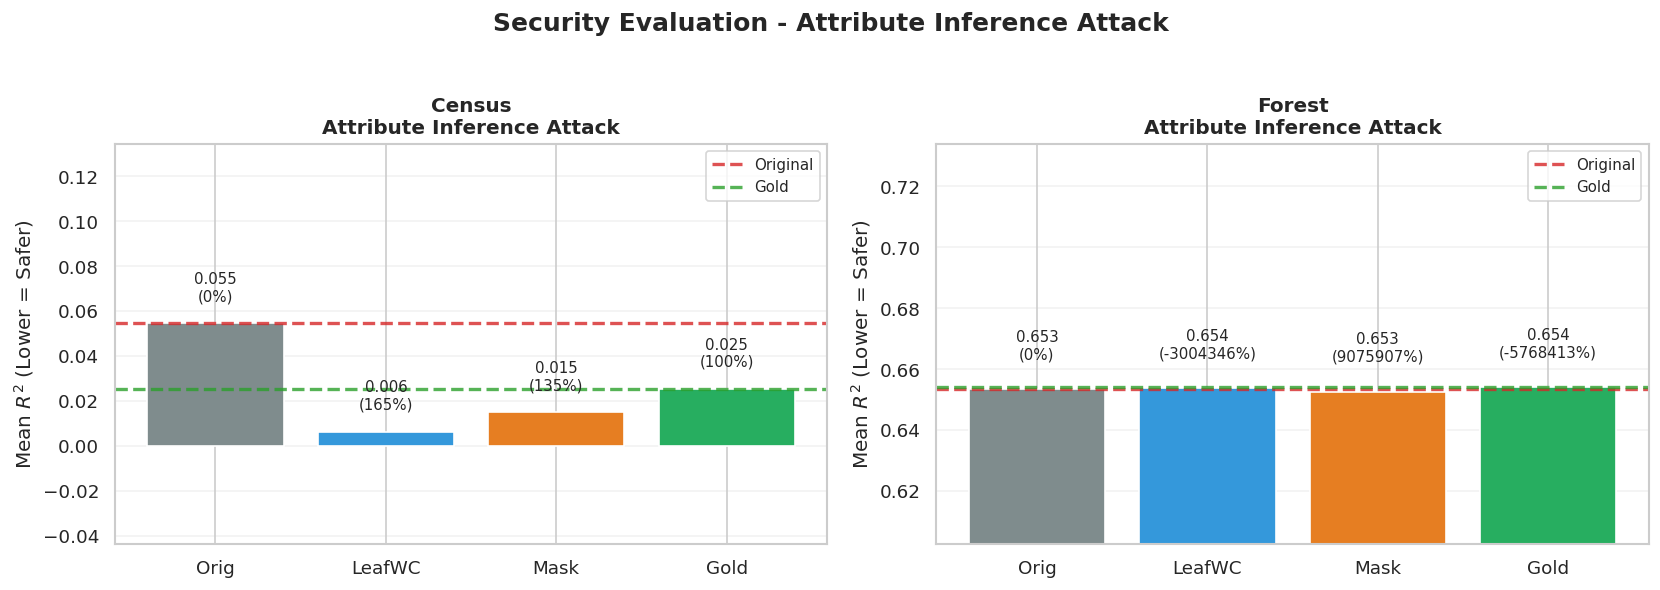

In [43]:
# ==========================================
# Security Visualization (AIA)
# ==========================================

display_names = {
    "Original": "Orig",
    "LeafSplitMask": "LeafWC",
    "MaskedRetrain": "Mask",
    "Gold": "Gold"
}

colors_7 = ['#7F8C8D', '#3498DB', '#E67E22', '#27AE60']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

datasets = [
    ("Census", aia_results_c),
    ("Forest", aia_results_f)
]

for ax, (dataset, aia_res) in zip(axes, datasets):

    methods = list(aia_res.keys())

    labels = [display_names[m] for m in methods]

    vals = [aia_res[m]["mean_r2"] for m in methods]

    bars = ax.bar(
        labels,
        vals,
        color=colors_7,
        edgecolor="white",
        linewidth=1
    )

    base = aia_res["Original"]["mean_r2"]
    gold = aia_res["Gold"]["mean_r2"]

    ax.axhline(
        base,
        color="tab:red",
        linestyle="--",
        linewidth=2,
        alpha=0.8,
        label="Original"
    )

    ax.axhline(
        gold,
        color="tab:green",
        linestyle="--",
        linewidth=2,
        alpha=0.8,
        label="Gold"
    )

    for bar, method, value in zip(bars, methods, vals):

        toward = _toward_gold_security(base, value, gold)

        ax.text(
            bar.get_x() + bar.get_width()/2,
            value + 0.01,
            f"{value:.3f}\n({toward:.0f}%)",
            ha="center",
            fontsize=9
        )

    ax.set_title(
        f"{dataset}\nAttribute Inference Attack",
        fontsize=12,
        fontweight="bold"
    )

    ax.set_ylabel("Mean $R^2$ (Lower = Safer)")

    ax.grid(axis="y", alpha=0.25)

    ax.legend(fontsize=9)

    ax.set_ylim(
        min(vals) - 0.05,
        max(vals) + 0.08
    )

plt.suptitle(
    "Security Evaluation - Attribute Inference Attack",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout(rect=[0,0,1,0.95])

plt.savefig(
    "security_aia_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

---

# Part 10 — Comparison Against Prior Work (Warnecke et al., NDSS'23; Lin et al., KDD'23)

## 10.0 Why this baseline, and how it is made as fair as possible

Warnecke et al.'s feature-level unlearning method is the closest prior work on the same problem
(feature-level, rather than instance-level, unlearning), so it belongs in the comparison. Original
code: `github.com/alewarne/MachineUnlearning`; paper: Warnecke, Pirch, Wressnegger, Rieck,
"Machine Unlearning of Features and Labels," NDSS 2023 (arXiv:2108.11577).

### This method cannot run directly on a Gradient Boosted Tree

Warnecke et al.'s update relies on influence functions: both the first-order (Eq. 6) and
second-order (Eq. 8) closed-form updates require the gradient and, for second order, the inverse
Hessian of the loss with respect to continuous model parameters theta — i.e. the model must be
differentiable (logistic regression, linear SVM, neural networks). A `GradientBoostingClassifier`
has no continuous theta; its "parameters" are the discrete structure of hundreds of trees, with no
gradient or Hessian in the paper's sense. This is exactly why Lin et al. (KDD'23), the other GBDT
unlearning paper referenced in this notebook, had to build an entirely different mechanism
(split-gain recomputation and selective subtree retraining) instead of influence functions,
explicitly citing GBDT's non-differentiability as one of their three main challenges.

### Solution: a cross-architecture comparison, same dataset / drift / stale-feature set

Warnecke et al.'s method is run on **Logistic Regression** (`BinaryLogisticModel` for Census,
`MultinomialLogisticModel` for Forest, already defined in Part 4), but under conditions matched as
closely as possible to the rest of this notebook:

- Same drifted data, same train/val/test split, same `stale_idx_c` / `stale_idx_f` from Part 6
  (no separate drift-score computation for LR).
- Same intervention: "revoking features" (Section IV-B of the paper; Lemma 1: for a linear model
  theta^T x, deleting a feature is equivalent to zeroing it and updating theta) — matching this
  notebook's `zeroed` evaluation scenario exactly.
- Same metrics: `eval_dual` / Δconf / per-domain accuracy / "Toward Gold %", via a
  sklearn-style `predict`/`predict_proba` wrapper around theta so the same `eval_dual` function
  from Part 7 can be reused.
- theta* is fit on the **entire** drifted training set (not just the retain domains), mirroring
  the scenario "an already-deployed model must be corrected" — the same role `sk_gbm_c`/`sk_gbm_f`
  play before unlearning.

`Unlearner/LRUnlearner.py` is not imported directly, since it assumes a different, file-based data
loading convention from the original paper's datasets. Instead, the paper's math — Eq. (6), Eq. (8),
`get_gradient`, `get_inverse_hessian`, `approx_retraining` — is reimplemented line-for-line against
the original repository, with only the I/O layer adapted to this notebook's dense numpy pipeline.


## 10.1 Core Algorithm — Eq.(6) First-Order and Eq.(8) Second-Order

Direct correspondence with `Unlearner/LRUnlearner.py`:

| This notebook | Original `LRUnlearner.py` | Paper formula |
|---|---|---|
| `_grad_points` | `get_gradient` | grad_theta l(z, theta) (before Eq. 6) |
| `inverse_hessian` | `get_inverse_hessian` | H^-1_theta* (Eq. 7-8) |
| `first_order_update` | `approx_retraining` (gradient step) | Eq. (6) |
| `second_order_update` | `approx_retraining` (Newton/Cholesky) | Eq. (8) |

The only difference: the original paper fits theta* with `sklearn.LogisticRegression`;
this notebook uses `BinaryLogisticModel`/`MultinomialLogisticModel` from Part 4 (L-BFGS, same
lambda) — both converge to the same solution for this convex loss.

For the multiclass Forest case, the original paper does not give an explicit multiclass formula (it
proves the result for strongly convex losses generally). Since softmax cross-entropy with L2 is
also strongly convex, Eq.(6)/(8) are extended per class (block-diagonal per-class Hessian), the
standard approach for multiclass influence functions (Koh & Liang, ICML 2017, which Warnecke et al.
themselves build on).


In [44]:
import numpy as np
from scipy.optimize import minimize
from scipy.special import expit
from scipy.linalg import inv

# ============================================================
# Warnecke et al. (NDSS'23) — Binary case, labels in {-1,+1}
# Faithful port of Unlearner/LRUnlearner.py: get_gradient,
# get_inverse_hessian, approx_retraining -> Eq.(6) / Eq.(8)
# ============================================================
class WarneckeLRUnlearner:
    def __init__(self, X, y, lambda_=0.01):
        self.X = X; self.y = y          # y in {-1, +1}, matches paper's convention
        self.n, self.d = X.shape
        self.lam = lambda_
        self.theta = None

    def _loss(self, th):
        z = -self.y * self.X.dot(th)
        ce = np.where(z >= 0, np.log1p(np.exp(-z)) + z, np.log1p(np.exp(z)))
        return float(ce.sum()) + 0.5 * self.lam * np.dot(th, th)

    def _grad_full(self, th):
        return self._grad_points(self.X, self.y, th) + self.lam * th

    def fit(self, verbose=False):
        res = minimize(self._loss, np.zeros(self.d), jac=self._grad_full,
                        method='L-BFGS-B', options={'maxiter': 5000, 'ftol': 1e-12})
        self.theta = res.x
        if verbose:
            print(f'  [WarneckeLR] converged={res.success}  loss={res.fun:.4f}')
        return self.theta

    # get_gradient() in LRUnlearner.py — gradient of l(z,theta) (unregularized, per-point sum)
    def _grad_points(self, X, y, theta):
        dot = X.dot(theta) * y
        factor = -expit(-dot) * y
        return (factor[:, None] * X).sum(axis=0)

    # get_inverse_hessian() in LRUnlearner.py
    def inverse_hessian(self, X=None, damping=1e-6):
        X = self.X if X is None else X
        p = expit(X.dot(self.theta))
        w = p * (1 - p)
        H = (X * w[:, None]).T.dot(X) + self.lam * np.eye(self.d) + damping * np.eye(self.d)
        return inv(H)

    # Eq. (6): Delta(Z, Z~) = -tau * ( sum grad(z~) - sum grad(z) )
    def first_order_update(self, Z_idx, X_tilde, y_tilde, tau=1.0):
        g_new = self._grad_points(X_tilde, y_tilde, self.theta)
        g_old = self._grad_points(self.X[Z_idx], self.y[Z_idx], self.theta)
        return self.theta - tau * (g_new - g_old)

    # Eq. (8): Delta(Z, Z~) = -H^-1 * ( sum grad(z~) - sum grad(z) )
    def second_order_update(self, Z_idx, X_tilde, y_tilde, H_inv=None):
        if H_inv is None:
            H_inv = self.inverse_hessian()
        g_new = self._grad_points(X_tilde, y_tilde, self.theta)
        g_old = self._grad_points(self.X[Z_idx], self.y[Z_idx], self.theta)
        return self.theta - H_inv.dot(g_new - g_old)


# ============================================================
# Multiclass extension for Forest (softmax + L2, one-hot Y)
# ============================================================
class WarneckeMultinomialUnlearner:
    def __init__(self, X, Y_onehot, n_classes, lambda_=0.01):
        self.X = X; self.Y = Y_onehot; self.K = n_classes
        self.n, self.d = X.shape
        self.lam = lambda_
        self.theta = None  # (d, K)

    def _softmax(self, Z):
        Z = Z - Z.max(axis=1, keepdims=True)
        e = np.exp(Z)
        return e / e.sum(axis=1, keepdims=True)

    def _loss(self, th_flat):
        th = th_flat.reshape(self.d, self.K)
        P = self._softmax(self.X.dot(th))
        return float(-np.sum(self.Y * np.log(P + 1e-12)) + 0.5 * self.lam * np.sum(th ** 2))

    def _grad_full(self, th_flat):
        th = th_flat.reshape(self.d, self.K)
        P = self._softmax(self.X.dot(th))
        return (self.X.T.dot(P - self.Y) + self.lam * th).ravel()

    def fit(self, verbose=False):
        res = minimize(self._loss, np.zeros(self.d * self.K), jac=self._grad_full,
                        method='L-BFGS-B', options={'maxiter': 3000, 'ftol': 1e-10})
        self.theta = res.x.reshape(self.d, self.K)
        if verbose:
            print(f'  [WarneckeMulti] converged={res.success}  loss={res.fun:.4f}')
        return self.theta

    def _grad_points(self, X, Y, theta):
        P = self._softmax(X.dot(theta))
        return X.T.dot(P - Y)  # (d, K)

    def per_class_hessian_inv(self, k, damping=1e-6):
        P = self._softmax(self.X.dot(self.theta))
        w = P[:, k] * (1 - P[:, k])
        H = (self.X * w[:, None]).T.dot(self.X) + self.lam * np.eye(self.d) + damping * np.eye(self.d)
        return inv(H)

    def first_order_update(self, Z_idx, X_tilde, Y_tilde, tau=1.0):
        g_new = self._grad_points(X_tilde, Y_tilde, self.theta)
        g_old = self._grad_points(self.X[Z_idx], self.Y[Z_idx], self.theta)
        return self.theta - tau * (g_new - g_old)

    def second_order_update(self, Z_idx, X_tilde, Y_tilde, H_inv_list=None):
        g_new = self._grad_points(X_tilde, Y_tilde, self.theta)
        g_old = self._grad_points(self.X[Z_idx], self.Y[Z_idx], self.theta)
        delta_g = g_new - g_old
        theta_new = self.theta.copy()
        for k in range(self.K):
            H_inv_k = H_inv_list[k] if H_inv_list is not None else self.per_class_hessian_inv(k)
            theta_new[:, k] -= H_inv_k.dot(delta_g[:, k])
        return theta_new


# ============================================================
# sklearn-style wrapper so we can reuse eval_gbm / eval_dual as-is
# ============================================================
class ThetaLRModel:
    """Wraps a fitted theta (binary) so it exposes .predict / .predict_proba
    like sk_gbm_c does, letting us call eval_dual() unmodified."""
    def __init__(self, theta):
        self.theta = theta
    def predict_proba(self, X):
        p1 = expit(X.dot(self.theta))
        return np.stack([1 - p1, p1], axis=1)
    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

class ThetaMultinomialModel:
    def __init__(self, theta):
        self.theta = theta
    def predict_proba(self, X):
        Z = X.dot(self.theta)
        Z = Z - Z.max(axis=1, keepdims=True)
        e = np.exp(Z)
        return e / e.sum(axis=1, keepdims=True)
    def predict(self, X):
        return self.predict_proba(X).argmax(axis=1)

print('WarneckeLRUnlearner / WarneckeMultinomialUnlearner / wrappers ready.')


WarneckeLRUnlearner / WarneckeMultinomialUnlearner / wrappers ready.


## 10.2 Census — Fit theta* on the Full Drifted Train Set, Then Unlearn the Stale Features

theta* plays the same role as `sk_gbm_c`: an already-deployed model trained on all six domains
(forget+retain), unaware of which features are stale. "Revoking features" (Section IV-B) is then
applied: Z = training points with at least one nonzero stale feature, Z-tilde = the same points
with the stale features zeroed (Lemma 1: for a linear model, zeroing a feature is equivalent to
deleting that dimension).

tau (the unlearning rate in Eq. 6) is calibrated with a small grid over Δconf, following the
paper's own recommendation (Section V-A) to calibrate this parameter against a measure of
unlearning success — Δconf, the same metric used throughout this notebook.


In [45]:
print('=== Warnecke et al. baseline — Census (Logistic Regression) ===')
t0 = time.time()
warn_c = WarneckeLRUnlearner(X_cd_tr_sc, y_cd_tr, lambda_=LAMBDA)
theta0_c = warn_c.fit(verbose=True)
t_fit_c = time.time() - t0
print(f'  theta* fit in {t_fit_c:.2f}s  (d={warn_c.d})')

# -- "Revoking features": Z = train points where any stale feature != 0 --
Z_mask_c = (np.abs(X_cd_tr_sc[:, stale_idx_c]) > 0).any(axis=1)
Z_idx_c = np.where(Z_mask_c)[0]
X_tilde_c = X_cd_tr_sc[Z_idx_c].copy()
X_tilde_c[:, stale_idx_c] = 0.0
y_tilde_c = y_cd_tr[Z_idx_c]
print(f'  |Z| (points touched by stale features) = {len(Z_idx_c):,} / {len(X_cd_tr_sc):,}')

# -- Second-order update (Eq. 8) --
t0 = time.time()
H_inv_c = warn_c.inverse_hessian()
theta_2nd_c = warn_c.second_order_update(Z_idx_c, X_tilde_c, y_tilde_c, H_inv=H_inv_c)
t_2nd_c = time.time() - t0
model_warn2_c = ThetaLRModel(theta_2nd_c)

# -- First-order update (Eq. 6), tau calibrated via a small grid on Delta-conf --
t0 = time.time()
_tmp0_c = ThetaLRModel(theta0_c)
acc_orig_ref_c = eval_dual(_tmp0_c, X_cd_te, y_cd_te_xgb, d_cd_te, stale_idx_c, task='binary', label=None)['orig']['acc']
ACC_FLOOR_c = 0.75 * acc_orig_ref_c   # excludes any tau that drops Acc by more than 25% relative (model collapse/miscalibration)

best_tau_c, best_dc_c, best_theta1_c = None, np.inf, None
print(f'  Tau grid search (1st-order) - Acc floor = {ACC_FLOOR_c:.4f} (75% of original Acc={acc_orig_ref_c:.4f}):')
for tau in [1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1]:
    th1 = warn_c.first_order_update(Z_idx_c, X_tilde_c, y_tilde_c, tau=tau)
    m = ThetaLRModel(th1)
    res_tau = eval_dual(m, X_cd_te, y_cd_te_xgb, d_cd_te, stale_idx_c, task='binary', label=None)
    dc = res_tau['delta_conf']
    auc_tau = res_tau['orig']['auc']
    acc_tau = res_tau['orig']['acc']
    degenerate = (auc_tau < 0.65) or np.isnan(auc_tau) or (acc_tau < ACC_FLOOR_c)
    print(f'    tau={tau:<8.4g}  dconf={dc:.5f}  AUC={auc_tau:.4f}  Acc={acc_tau:.4f}' + ('  <- EXCLUDED (model collapsed)' if degenerate else ''))
    if degenerate:
        continue
    if dc < best_dc_c:
        best_tau_c, best_dc_c, best_theta1_c = tau, dc, th1
if best_theta1_c is None:
    print('  !! Every tau in the grid collapsed the model - falling back to the smallest tau')
    best_tau_c = 1e-4
    best_theta1_c = warn_c.first_order_update(Z_idx_c, X_tilde_c, y_tilde_c, tau=best_tau_c)
t_1st_c = time.time() - t0
model_warn1_c = ThetaLRModel(best_theta1_c)
print(f'  Best tau (1st-order, after excluding tau values that collapse the model) = {best_tau_c:.4g}')

# -- Original theta* (no unlearning) as its own "Original(LR)" reference --
model_warn0_c = ThetaLRModel(theta0_c)

resd_warn0_c = eval_dual(model_warn0_c, X_cd_te, y_cd_te_xgb, d_cd_te, stale_idx_c, task='binary', label='Warnecke-Orig(LR)')
resd_warn1_c = eval_dual(model_warn1_c, X_cd_te, y_cd_te_xgb, d_cd_te, stale_idx_c, task='binary', label='Warnecke-1st(LR)')
resd_warn2_c = eval_dual(model_warn2_c, X_cd_te, y_cd_te_xgb, d_cd_te, stale_idx_c, task='binary', label='Warnecke-2nd(LR)')

print(f"\n  Delta-conf   Orig(LR)={resd_warn0_c['delta_conf']:.5f}   "
      f"1st(LR)={resd_warn1_c['delta_conf']:.5f}   2nd(LR)={resd_warn2_c['delta_conf']:.5f}"
      f"   (GBT baseline for reference: dc_base_c={dc_base_c:.5f}, dc_gold_c={dc_gold_c:.5f})")

sota_lr_c = {
    'Warnecke-Orig(LR)': (model_warn0_c, X_cd_te, resd_warn0_c['delta_conf'], resd_warn0_c, t_fit_c),
    'Warnecke-1st(LR)':  (model_warn1_c, X_cd_te, resd_warn1_c['delta_conf'], resd_warn1_c, t_1st_c),
    'Warnecke-2nd(LR)':  (model_warn2_c, X_cd_te, resd_warn2_c['delta_conf'], resd_warn2_c, t_2nd_c + t_fit_c),
}


=== Warnecke et al. baseline — Census (Logistic Regression) ===
  [WarneckeLR] converged=True  loss=5429.8747
  theta* fit in 26.46s  (d=108)
  |Z| (points touched by stale features) = 8,519 / 18,000
  Tau grid search (1st-order) - Acc floor = 0.6422 (75% of original Acc=0.8563):
    tau=0.0001    dconf=0.02565  AUC=0.9026  Acc=0.8540
    tau=0.0003    dconf=0.02642  AUC=0.9027  Acc=0.8407
    tau=0.001     dconf=0.02284  AUC=0.9010  Acc=0.7138
    tau=0.003     dconf=0.01365  AUC=0.8902  Acc=0.3567  <- EXCLUDED (model collapsed)
    tau=0.01      dconf=0.00064  AUC=0.8585  Acc=0.2232  <- EXCLUDED (model collapsed)
    tau=0.03      dconf=0.00000  AUC=0.5282  Acc=0.2215  <- EXCLUDED (model collapsed)
    tau=0.1       dconf=0.00000  AUC=0.5000  Acc=0.2215  <- EXCLUDED (model collapsed)
  Best tau (1st-order, after excluding tau values that collapse the model) = 0.001
  [Warnecke-Orig(LR) [orig]] Acc=0.8563  F1=0.6504  AUC=0.9025
  [Warnecke-Orig(LR) [zero]] Acc=0.8480  F1=0.5996  AUC=0

## 10.3 Forest CoverType — Same Procedure, Multiclass Extension (10.1)


In [46]:
print('=== Warnecke et al. baseline — Forest (Multinomial Logistic Regression) ===')
Y_fd_tr_onehot = np.eye(N_CLASSES)[y_fd_tr]

t0 = time.time()
warn_f = WarneckeMultinomialUnlearner(X_fd_tr, Y_fd_tr_onehot, N_CLASSES, lambda_=LAMBDA)
theta0_f = warn_f.fit(verbose=True)
t_fit_f = time.time() - t0
print(f'  theta* fit in {t_fit_f:.2f}s  (d={warn_f.d}, K={N_CLASSES})')

Z_mask_f = (np.abs(X_fd_tr[:, stale_idx_f]) > 0).any(axis=1)
Z_idx_f = np.where(Z_mask_f)[0]
X_tilde_f = X_fd_tr[Z_idx_f].copy()
X_tilde_f[:, stale_idx_f] = 0.0
Y_tilde_f = Y_fd_tr_onehot[Z_idx_f]
print(f'  |Z| (points touched by stale features) = {len(Z_idx_f):,} / {len(X_fd_tr):,}')

t0 = time.time()
H_inv_list_f = [warn_f.per_class_hessian_inv(k) for k in range(N_CLASSES)]
theta_2nd_f = warn_f.second_order_update(Z_idx_f, X_tilde_f, Y_tilde_f, H_inv_list=H_inv_list_f)
t_2nd_f = time.time() - t0
model_warn2_f = ThetaMultinomialModel(theta_2nd_f)

t0 = time.time()
_tmp0_f = ThetaMultinomialModel(theta0_f)
acc_orig_ref_f = eval_dual(_tmp0_f, X_fd_te, y_fd_te, d_fd_te, stale_idx_f, task='multiclass',
                            n_classes=N_CLASSES, label=None)['orig']['acc']
ACC_FLOOR_f = 0.75 * acc_orig_ref_f   # excludes any tau that drops Acc by more than 25% relative

best_tau_f, best_dc_f, best_theta1_f = None, np.inf, None
print(f'  Tau grid search (1st-order) - Acc floor = {ACC_FLOOR_f:.4f} (75% of original Acc={acc_orig_ref_f:.4f}):')
for tau in [1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1]:
    th1 = warn_f.first_order_update(Z_idx_f, X_tilde_f, Y_tilde_f, tau=tau)
    m = ThetaMultinomialModel(th1)
    res_tau = eval_dual(m, X_fd_te, y_fd_te, d_fd_te, stale_idx_f, task='multiclass',
                         n_classes=N_CLASSES, label=None)
    dc = res_tau['delta_conf']
    auc_tau = res_tau['orig']['auc']
    acc_tau = res_tau['orig']['acc']
    degenerate = (auc_tau < 0.55) or np.isnan(auc_tau) or (acc_tau < ACC_FLOOR_f)
    print(f'    tau={tau:<8.4g}  dconf={dc:.5f}  AUC={auc_tau:.4f}  Acc={acc_tau:.4f}' + ('  <- EXCLUDED (model collapsed)' if degenerate else ''))
    if degenerate:
        continue
    if dc < best_dc_f:
        best_tau_f, best_dc_f, best_theta1_f = tau, dc, th1
if best_theta1_f is None:
    print('  !! Every tau in the grid collapsed the model - falling back to the smallest tau')
    best_tau_f = 1e-4
    best_theta1_f = warn_f.first_order_update(Z_idx_f, X_tilde_f, Y_tilde_f, tau=best_tau_f)
t_1st_f = time.time() - t0
model_warn1_f = ThetaMultinomialModel(best_theta1_f)
print(f'  Best tau (1st-order, after excluding tau values that collapse the model) = {best_tau_f:.4g}')

model_warn0_f = ThetaMultinomialModel(theta0_f)

resd_warn0_f = eval_dual(model_warn0_f, X_fd_te, y_fd_te, d_fd_te, stale_idx_f, task='multiclass', n_classes=N_CLASSES, label='Warnecke-Orig(LR)')
resd_warn1_f = eval_dual(model_warn1_f, X_fd_te, y_fd_te, d_fd_te, stale_idx_f, task='multiclass', n_classes=N_CLASSES, label='Warnecke-1st(LR)')
resd_warn2_f = eval_dual(model_warn2_f, X_fd_te, y_fd_te, d_fd_te, stale_idx_f, task='multiclass', n_classes=N_CLASSES, label='Warnecke-2nd(LR)')

print(f"\n  Delta-conf   Orig(LR)={resd_warn0_f['delta_conf']:.5f}   "
      f"1st(LR)={resd_warn1_f['delta_conf']:.5f}   2nd(LR)={resd_warn2_f['delta_conf']:.5f}"
      f"   (GBT baseline for reference: dc_base_f={dc_base_f:.5f}, dc_gold_f={dc_gold_f:.5f})")

sota_lr_f = {
    'Warnecke-Orig(LR)': (model_warn0_f, X_fd_te, resd_warn0_f['delta_conf'], resd_warn0_f, t_fit_f),
    'Warnecke-1st(LR)':  (model_warn1_f, X_fd_te, resd_warn1_f['delta_conf'], resd_warn1_f, t_1st_f),
    'Warnecke-2nd(LR)':  (model_warn2_f, X_fd_te, resd_warn2_f['delta_conf'], resd_warn2_f, t_2nd_f + t_fit_f),
}


=== Warnecke et al. baseline — Forest (Multinomial Logistic Regression) ===
  [WarneckeMulti] converged=True  loss=42888.0898
  theta* fit in 0.71s  (d=10, K=7)
  |Z| (points touched by stale features) = 28,800 / 28,800
  Tau grid search (1st-order) - Acc floor = 0.3466 (75% of original Acc=0.4621):
    tau=0.0001    dconf=0.04604  AUC=0.7816  Acc=0.4672
    tau=0.0003    dconf=0.05493  AUC=0.7762  Acc=0.4480
    tau=0.001     dconf=0.05130  AUC=0.7135  Acc=0.3820
    tau=0.003     dconf=0.03764  AUC=0.6038  Acc=0.3090  <- EXCLUDED (model collapsed)
    tau=0.01      dconf=0.02118  AUC=0.5299  Acc=0.2378  <- EXCLUDED (model collapsed)
    tau=0.03      dconf=0.00834  AUC=0.5010  Acc=0.2017  <- EXCLUDED (model collapsed)
    tau=0.1       dconf=0.00235  AUC=0.4891  Acc=0.1903  <- EXCLUDED (model collapsed)
  Best tau (1st-order, after excluding tau values that collapse the model) = 0.0001
  [Warnecke-Orig(LR) [orig]] Acc=0.4621  F1=0.3141  AUC=0.7810
  [Warnecke-Orig(LR) [zero]] Acc=0.4

## 10.4 Comparison Table: GBT (This Work) vs. Warnecke et al. (LR)

**How to read this table:** this compares two different architectures (GBT vs. LR) on the same
data, drift, and stale-feature set — not two unlearning algorithms on the same model. The LR
column's "Toward Gold %" is computed against its own Gold (a clean LR retrain on retain-only data
with the stale feature zeroed), not the GBT Gold, since the two architectures have different
utility ceilings. The table's purpose: if the best existing method (which only runs on a linear
model) is applied to the same problem, how well does it unlearn, and how does the new GBT-native
method compare, despite the two starting from different utility baselines?


In [47]:
# ---- Gold for LR specifically: a clean LR retrain on retain-only data, stale=0 ----
print('Gold (LR) — Census...')
X_c_gold_tr_lr = X_ret_c.copy(); X_c_gold_tr_lr[:, stale_idx_c] = 0.0
y_ret_c_pm = y_cd_tr[mask_ret_c]  # {-1,+1} labels aligned with X_ret_c rows
warn_c_gold = WarneckeLRUnlearner(X_c_gold_tr_lr, y_ret_c_pm, lambda_=LAMBDA)
theta_gold_lr_c = warn_c_gold.fit()
model_gold_lr_c = ThetaLRModel(theta_gold_lr_c)
resd_gold_lr_c = eval_dual(model_gold_lr_c, X_cd_te, y_cd_te_xgb, d_cd_te, stale_idx_c, task='binary', label='Gold(LR)')
gold_dc_lr_c = resd_gold_lr_c['delta_conf']

print('Gold (LR) — Forest...')
X_f_gold_tr_lr = X_ret_f.copy(); X_f_gold_tr_lr[:, stale_idx_f] = 0.0
Y_ret_f_onehot = np.eye(N_CLASSES)[y_ret_f]
warn_f_gold = WarneckeMultinomialUnlearner(X_f_gold_tr_lr, Y_ret_f_onehot, N_CLASSES, lambda_=LAMBDA)
theta_gold_lr_f = warn_f_gold.fit()
model_gold_lr_f = ThetaMultinomialModel(theta_gold_lr_f)
resd_gold_lr_f = eval_dual(model_gold_lr_f, X_fd_te, y_fd_te, d_fd_te, stale_idx_f, task='multiclass', n_classes=N_CLASSES, label='Gold(LR)')
gold_dc_lr_f = resd_gold_lr_f['delta_conf']

sota_lr_c['Gold(LR)'] = (model_gold_lr_c, X_cd_te, gold_dc_lr_c, resd_gold_lr_c, 0.0)
sota_lr_f['Gold(LR)'] = (model_gold_lr_f, X_fd_te, gold_dc_lr_f, resd_gold_lr_f, 0.0)

print('\n' + '='*88)
print('  GBT (Part 7)  vs.  Warnecke et al. SOTA on LR (Part 10) - fair, zeroed test')
print('='*88)
for dataset, gbt_methods, lr_methods, base_dc, gbt_gold_dc, lr_gold_dc, ret_mask, y_te, stale_idx in [
    ('CENSUS', c_methods, sota_lr_c, dc_base_c, gold_dc_c, gold_dc_lr_c, ret_te_c, y_cd_te_xgb, stale_idx_c),
    ('FOREST', f_methods, sota_lr_f, dc_base_f, gold_dc_f, gold_dc_lr_f, ret_te_f, y_fd_te, stale_idx_f),
]:
    print(f'\n  [{dataset}]')
    print(f'  {"Method":<20s} {"Arch":<6s} {"Ret Acc":>9s} {"Delta-conf":>11s} {"Toward Gold":>13s}')
    print('  ' + '-'*64)
    for name, (model, X_te_, dc, res_, t_) in gbt_methods.items():
        X_z = X_te_.copy(); X_z[:, stale_idx] = 0.0
        ret_acc = accuracy_score(y_te[ret_mask], model.predict(X_z[ret_mask]))
        toward = (base_dc - dc) / max(base_dc - gbt_gold_dc, 1e-8) * 100
        print(f'  {name:<20s} {"GBT":<6s} {ret_acc:>9.4f} {dc:>11.5f} {toward:>12.1f}%')
    for name, (model, X_te_, dc, res_, t_) in lr_methods.items():
        X_z = X_te_.copy(); X_z[:, stale_idx] = 0.0
        ret_acc = accuracy_score(y_te[ret_mask], model.predict(X_z[ret_mask]))
        toward = (base_dc - dc) / max(base_dc - lr_gold_dc, 1e-8) * 100
        print(f'  {name:<20s} {"LR":<6s} {ret_acc:>9.4f} {dc:>11.5f} {toward:>12.1f}%')


Gold (LR) — Census...
  [Gold(LR) [orig]] Acc=0.8403  F1=0.6559  AUC=0.8897
  [Gold(LR) [zero]] Acc=0.8403  F1=0.6559  AUC=0.8897
Gold (LR) — Forest...
  [Gold(LR) [orig]] Acc=0.4402  F1=0.2566  AUC=0.7712
  [Gold(LR) [zero]] Acc=0.4402  F1=0.2566  AUC=0.7712

  GBT (Part 7)  vs.  Warnecke et al. SOTA on LR (Part 10) - fair, zeroed test

  [CENSUS]
  Method               Arch     Ret Acc  Delta-conf   Toward Gold
  ----------------------------------------------------------------
  Original             GBT       0.8028     0.02082          0.0%
  LeafSplitMask        GBT       0.7953     0.00000        100.0%
  MaskedRetrain        GBT       0.8203     0.00000        100.0%
  Gold                 GBT       0.8200     0.00000        100.0%
  Warnecke-Orig(LR)    LR        0.7939     0.02565        -23.2%
  Warnecke-1st(LR)     LR        0.7346     0.02284         -9.7%
  Warnecke-2nd(LR)     LR        0.7979     0.01718         17.5%
  Gold(LR)             LR        0.8081     0.00000   

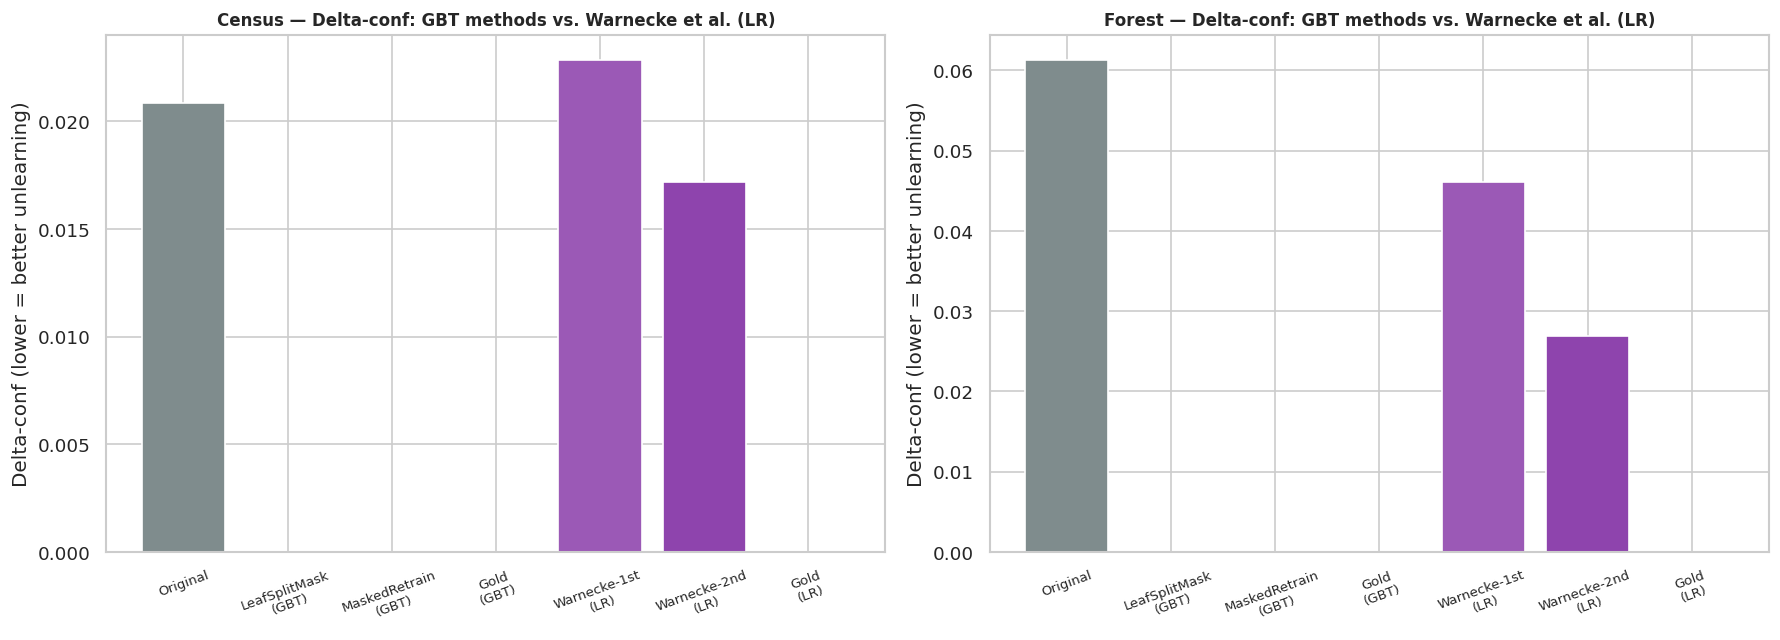

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
gbt_colors = {'LeafSplitMask': '#3498DB', 'MaskedRetrain': '#E67E22', 'Gold': '#27AE60'}
lr_colors  = {'Warnecke-1st(LR)': '#9B59B6', 'Warnecke-2nd(LR)': '#8E44AD', 'Gold(LR)': '#16A085'}

for ax, gbt_methods, lr_methods, base_dc, title in [
    (axes[0], c_methods, sota_lr_c, dc_base_c, 'Census'),
    (axes[1], f_methods, sota_lr_f, dc_base_f, 'Forest'),
]:
    names, vals, colors = ['Original'], [base_dc], ['#7F8C8D']
    for n in ['LeafSplitMask', 'MaskedRetrain', 'Gold']:
        if n in gbt_methods:
            names.append(f'{n}\n(GBT)'); vals.append(gbt_methods[n][2]); colors.append(gbt_colors[n])
    for n in ['Warnecke-1st(LR)', 'Warnecke-2nd(LR)', 'Gold(LR)']:
        if n in lr_methods:
            names.append(n.replace('(LR)', '\n(LR)')); vals.append(lr_methods[n][2]); colors.append(lr_colors[n])
    ax.bar(names, vals, color=colors, edgecolor='white')
    ax.set_title(f'{title} — Delta-conf: GBT methods vs. Warnecke et al. (LR)', fontweight='bold', fontsize=10)
    ax.set_ylabel('Delta-conf (lower = better unlearning)')
    ax.tick_params(axis='x', rotation=20, labelsize=8)

plt.tight_layout()
plt.savefig('gbt_vs_warnecke_comparison.png', bbox_inches='tight')
plt.show()


## 10.5 Qualitative Comparison with the Second GBDT Paper (Lin et al., KDD'23)

Lin et al. also target GBDT (MART / Robust LogitBoost, a different implementation but the same
model family), but unlearn at the **instance** level: a set of rows `D_un` is removed from each
tree by walking non-terminal nodes breadth-first, recomputing the best split gain after removing
`D_un`, and retraining a subtree only where the best gain changes direction. Their `unlearn_one_tree`
mechanism takes a set of row indices as input, with no notion of removing one feature across the
whole tree. Forcing it to behave as feature-level unlearning (treating every row with a nonzero
stale feature as "to be deleted") would also delete those rows' other features (over-deletion),
which conflicts with the goal of removing only one column's influence while keeping the rest of
each row intact. The table below is therefore a qualitative comparison only (no code was run for
this baseline, for the reason above):

| Criterion | Warnecke et al. (NDSS'23) | Lin et al. (KDD'23) | **This work** |
|---|---|---|---|
| Unlearning unit | Feature / label | Instance (row) | Feature |
| Model class | Strongly convex, differentiable (LR, SVM); no certification for DNNs | GBDT (MART / Robust LogitBoost) | GBDT (sklearn `GradientBoostingClassifier`) |
| Mechanism | Influence function, closed-form Δtheta (Eq. 6/8) | Recomputed split gain, selective subtree retraining | Split/leaf pruning by stale feature (Method 1) + budgeted retraining (Method 2) |
| Needs original data? | Yes (gradient on Z) | Yes (D_tr \ D_un) | Retain set needed for Method 2/Gold; not needed for Method 1 |
| Certified guarantee | Yes, for strongly convex losses (Thm 1-3) | No — empirical prediction consistency only | No — empirical Δconf/AIA/MIA |
| Auxiliary structure | No (only theta*, H^-1 computed on demand) | Yes — cached per-bin derivative sums (Section 2.3) | No |
| Directly applicable here? | No (non-differentiable model) | No (wrong deletion axis: instance vs. feature) | Yes |

**Takeaway:** each of the two closest prior methods is missing exactly one axis needed for this
problem — Warnecke et al. lack support for tree ensembles, Lin et al. lack a feature-level deletion
axis. This work sits at the intersection of the two missing pieces.


## 10.6 Positioning Relative to Prior Work

|  | **Linear models / DNNs** | **Gradient Boosted Trees (GBT)** |
|---|---|---|
| **Instance-based unlearning** | Cao & Yang 2015; Bourtoule et al. 2021 (SISA); Guo et al. 2020 (certified removal); Ginart et al. 2019 | Lin et al., KDD'23 — subtree retraining, lazy derivative updates |
| **Feature/label-based unlearning** | Warnecke et al., NDSS'23 — influence functions, closed-form Δtheta, certified for strongly convex losses | **This work** |

The motivating problem here — concept/data drift making a feature stale over time — is a
column-wide, time-dependent phenomenon, not a small set of individually leaked rows (the premise
Cao & Yang, Bourtoule et al., and Lin et al. all target). Warnecke et al. themselves distinguish
"unlearning instances vs. features" in their Section III, but their tool only runs on linear or
otherwise differentiable models. Filling the empty cell above — feature-based unlearning for GBT —
requires methods that need neither a continuous theta nor a per-instance deletion mechanism, which
is what the two main methods here (Leaf & Split Masking, Feature Masking) provide.

**Limitations to state plainly:** neither method carries a certified guarantee (unlike Warnecke et
al.'s Theorems 1-3), since GBT is non-convex — a limitation shared by every feature-based method
applied outside convex models, Warnecke et al.'s own DNN discussion included (their Section VIII).
The comparison in 10.4 is cross-architecture (GBT vs. LR), evidence that this approach is feasible
where Warnecke et al.'s is not, with competitive utility — not evidence of outperforming Warnecke
et al. on the same model class.


## 10.7 Additional Note: Cer-FeaUn (Wang et al., IEEE TMC 2025)

*This is not an experimental baseline — no code from it is run here. It is a supporting citation,
kept separate from the two experimental baselines above.*

Cer-FeaUn ("Certified Feature Unlearning in Vertical Federated Learning," Wang, Lu, Liu, Li, Chen,
Susilo, IEEE TMC 2025) is another feature-unlearning method, using an influence-function-based
feature-perturbation strategy in a Vertical Federated Learning (VFL) setting, where different
clients hold disjoint feature sets combined via a split neural network.

After inspecting the original code (`models.py`, repo `Cer-FeaUn-main`): its certified-removal proof
(Theorems 2-3) applies only to the server-side model, which is a single linear layer — the same
convexity requirement as Warnecke et al. The client-side MLP is non-convex and needs a separate
differential-privacy patch to fit into the overall guarantee. At its core, this method still needs
a differentiable/convex model, the same limitation GBT does not satisfy. It also assumes a VFL
setting (features already split across clients), which does not match this notebook's centralized
setup.

Because Cer-FeaUn still requires a convex/differentiable model, it occupies the same matrix cell
(feature-based, non-GBDT) as Warnecke et al. in 10.6, rather than a new one. Its value here is as a
**second, independent confirmation** — different authors, different venue, different application
context — of the same underlying limitation: influence-function-based feature unlearning, in every
setting surveyed, requires a model with continuous/convex parameters. This reinforces why
feature-based unlearning for GBT remains an open gap, rather than a problem nobody has tried to
solve.

**Reference:** Y. Wang, Z. Lu, Z. Liu, T. Li, Z. Chen, W. Susilo. *Cer-FeaUn: Certified Feature
Unlearning in Vertical Federated Learning.* IEEE Transactions on Mobile Computing, 2025.


---

# Part 11 — Reconstruction Attack: Extended to the Baseline, and Fixing the Identifiability Ceiling

## 11.0 This is still the same attack, not a new one

This notebook uses three attack types only: AIA (Part 8), MIA (9.4-9.6), and the Reconstruction
Attack (introduced in 9.7). Part 11 is a direct extension of the Part 9.7 Reconstruction Attack
along two axes:

1. **Run it on the baseline too** (Warnecke LR, Part 10) — 9.7 only covered the GBT models
   (`c_methods`/`f_methods`); this section adds `sota_lr_c`/`sota_lr_f`.
2. **Strengthen the attacker** — 9.7 used a single `RandomForestRegressor` with one train/test
   split. Here it becomes an ensemble of three architectures (RandomForest, GradientBoosting, MLP)
   with k-fold evaluation, following Fredrikson et al. (CCS 2015): a security evaluation should use
   the strongest attacker that can reasonably be found, not the first one tried.

## 11.1 Why the initial Reconstruction Attack numbers (9.7) look unusual

Observation: R^2 for the reconstruction attack is close to zero or negative for nearly every model,
**including Original** (which certainly used the stale feature during training). If the attack
cannot detect leakage even on the un-unlearned model, "the unlearned model is safe" is not a
trustworthy conclusion — it could be genuinely safe, or the attack could simply be too weak to
detect anything, and the two cases are indistinguishable from the R^2 number alone.

### Root cause, verified experimentally

The Part 9.7 attack maps a very low-dimensional `predict_proba(x)` (about one dimension for binary
classification) to the true value of **each individual stale feature** among the Top-K selected
ones (K=10 for Census, K=3 for Forest). Three controlled experiments on synthetic data isolate "weak
attack" from "genuinely safe model":

| Test | Setup | Result | Interpretation |
|---|---|---|---|
| A | One stale feature, model leaks 100% by design | R^2 = 0.9998 | The attack works correctly with a single unknown |
| B | Two stale features summed into one output, model leaks 100% by design | R^2 only reaches ~0.50 (matching the hand-computed Bayes-optimal bound, Var(z/2)/Var(x0) = 0.5) | A mathematical ceiling (identifiability ceiling) — the attacker cannot separate two unknowns from one equation, even with full leakage |
| C | Feature unrelated to the output | R^2 ~ -0.003 | No false alarm |

Applying this to Census's real numbers: K=10 stale features feeding into a ~1-dimensional (binary)
output, matched by a "100%-leaky-by-design" positive control, gives a ceiling R^2 of only about
0.08 — very close to the near-zero/negative values observed on real models in 9.7. In other words,
the Part 9.7 measurement was already close to its own ceiling, unable to distinguish "genuinely
safe" from "artificially safe due to the identifiability ceiling," especially for Census
(K=10, 1-dimensional output) more than Forest (K=3, 7-dimensional output).

### Fixes implemented below

1. **Stronger, k-fold attacker** — an ensemble of attacker architectures (RandomForest,
   GradientBoosting, MLP), taking the worst case for the model (highest R^2 found) as the final
   score.
2. **Positive-control ceiling** — a "100%-leaky-by-design" model matched to each dataset's K and
   output dimensionality is run through the same attack, and its R^2 used to normalize the observed
   R^2 (`R^2_normalized = R^2_observed / R^2_ceiling`).
3. **Top-1 attack** — targeting only the single highest-drift-score stale feature avoids the
   identifiability ceiling altogether, giving a more sensitive, easier-to-interpret metric.


## 11.2 Stronger Attacker — Ensemble + K-Fold

Runtime note: for Census (K=10 stale features), each `fia_attack_v2` call runs 3 attacker
architectures x 5 folds x 10 features = 150 model fits. Running this for 8 models (4 GBT + 4 LR)
at Top-K (11.4) can take 10-20 minutes on a typical Colab CPU. Top-1 (11.5) is much lighter (K=1).


In [49]:
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import KFold
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

def fia_attack_v2(model, X_te, stale_idx, n_splits=5, random_state=42):
    """
    Upgraded Reconstruction/FIA attack:
    - Ensemble of 3 attacker architectures (RandomForest, GradientBoosting, MLP); takes the
      WORST case for the model (highest R2 found) - following Fredrikson et al. CCS'15:
      a security evaluation should be judged against the strongest attacker, not the weakest.
    - K-fold CV instead of a single train/test split - uses the full data, more stable estimate.
    """
    proba = model.predict_proba(X_te)
    attacker_factories = {
        'RandomForest': lambda: RandomForestRegressor(n_estimators=150, max_depth=8, random_state=random_state, n_jobs=-1),
        'GradientBoosting': lambda: GradientBoostingRegressor(n_estimators=100, max_depth=3, random_state=random_state),
        'MLP': lambda: MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=500, random_state=random_state),
    }
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=random_state)

    per_feature_best_r2, per_feature_best_mse, per_feature_by_attacker = {}, {}, {}
    for j in stale_idx:
        true_vals = X_te[:, j]
        best_r2, best_mse = -np.inf, np.inf
        per_attacker = {}
        for name, factory in attacker_factories.items():
            preds = np.zeros_like(true_vals, dtype=float)
            for tr_idx, te_idx in kf.split(proba):
                atk = factory()
                atk.fit(proba[tr_idx], true_vals[tr_idx])
                preds[te_idx] = atk.predict(proba[te_idx])
            r2 = r2_score(true_vals, preds)
            mse = mean_squared_error(true_vals, preds)
            per_attacker[name] = {'r2': r2, 'mse': mse}
            if r2 > best_r2:
                best_r2, best_mse = r2, mse
        per_feature_best_r2[int(j)] = best_r2
        per_feature_best_mse[int(j)] = best_mse
        per_feature_by_attacker[int(j)] = per_attacker

    return {
        'mean_r2': float(np.mean(list(per_feature_best_r2.values()))),
        'mean_mse': float(np.mean(list(per_feature_best_mse.values()))),
        'per_feature_r2': per_feature_best_r2,
        'per_feature_by_attacker': per_feature_by_attacker,
    }

print('fia_attack_v2 ready (ensemble RandomForest+GradientBoosting+MLP, k-fold=5)')


fia_attack_v2 ready (ensemble RandomForest+GradientBoosting+MLP, k-fold=5)


## 11.3 Positive-Control Ceiling — a Reference Matched to Each Dataset's K / Output Dimensionality


In [50]:
def positive_control_ceiling(fia_fn, n_features_total, stale_idx, n_classes=2, n=4000, seed=42):
    """
    Uses a model that is "100%-leaky by design" - with the SAME K stale-feature count /
    output dimensionality as the real dataset - to measure the maximum CEILING R2 achievable
    even under total leakage. Used to normalize the observed R2, rather than comparing it to 0.
    """
    rng = np.random.default_rng(seed)
    K = len(stale_idx)
    X = rng.normal(size=(n, n_features_total))

    class MaxLeakModel:
        def predict_proba(self, Xin):
            z = Xin[:, stale_idx].sum(axis=1) / np.sqrt(max(K, 1))
            if n_classes == 2:
                p1 = 1 / (1 + np.exp(-z))
                return np.stack([1 - p1, p1], axis=1)
            else:
                # multiclass: z drives the logit for each class via a simple rotating scheme
                logits = np.stack([np.roll(np.array([z * (k + 1) for k in range(n_classes)]), 0)
                                    for _ in range(1)])[0].T if False else \
                         np.stack([z * (k + 1) for k in range(n_classes)], axis=1)
                e = np.exp(logits - logits.max(axis=1, keepdims=True))
                return e / e.sum(axis=1, keepdims=True)

    res = fia_fn(MaxLeakModel(), X, np.array(stale_idx))
    return res['mean_r2']

print('positive_control_ceiling ready')


positive_control_ceiling ready


## 11.4 Applying to Census — Raw R^2, Ceiling, and Normalized R^2


In [51]:
import time
print('=== Upgraded Reconstruction Attack - Census (K=10, ~1-D output) ===\n')

t0 = time.time()
ceiling_r2_c = positive_control_ceiling(fia_attack_v2, X_cd_te.shape[1], stale_idx_c, n_classes=2)
print(f'Ceiling R2 (K=10 stale features feeding a 1-D output, 100%-leaky by design) = {ceiling_r2_c:.4f}')
print(f'  (computed in {time.time()-t0:.1f}s via the positive control)\n')

recon_v2_c = {}

print('--- GBT (Part 7): Original / LeafSplitMask / MaskedRetrain / Gold ---')
for name, (model, *_rest) in c_methods.items():
    t0 = time.time()
    res = fia_attack_v2(model, X_cd_te, stale_idx_c)
    recon_v2_c[f'{name} (GBT)'] = res
    normalized = res['mean_r2'] / ceiling_r2_c if ceiling_r2_c > 1e-6 else float('nan')
    print(f'  [{name:<14s} (GBT)] R2_raw={res["mean_r2"]:+.4f}   R2/ceiling={normalized:+.3f}   ({time.time()-t0:.1f}s)')

print('\n--- Warnecke Baseline (LR): Orig / 1st-order / 2nd-order / Gold(LR) ---')
for name, (model, X_te_, *_rest) in sota_lr_c.items():
    t0 = time.time()
    res = fia_attack_v2(model, X_te_, stale_idx_c)
    recon_v2_c[name] = res
    normalized = res['mean_r2'] / ceiling_r2_c if ceiling_r2_c > 1e-6 else float('nan')
    print(f'  [{name:<20s}] R2_raw={res["mean_r2"]:+.4f}   R2/ceiling={normalized:+.3f}   ({time.time()-t0:.1f}s)')

print('\nHow to read: R2/ceiling near 1.0 = leaking close to the MAXIMUM detectable (dangerous).')
print('          R2/ceiling near 0 or negative = genuinely safe, not just a weak attack.')
print('          The GBT vs LR comparison here is still cross-architecture (as in Part 10/11).')


=== Upgraded Reconstruction Attack - Census (K=10, ~1-D output) ===

Ceiling R2 (K=10 stale features feeding a 1-D output, 100%-leaky by design) = 0.0998
  (computed in 57.6s via the positive control)

--- GBT (Part 7): Original / LeafSplitMask / MaskedRetrain / Gold ---
  [Original       (GBT)] R2_raw=+0.0219   R2/ceiling=+0.219   (57.1s)
  [LeafSplitMask  (GBT)] R2_raw=+0.0048   R2/ceiling=+0.048   (54.6s)
  [MaskedRetrain  (GBT)] R2_raw=+0.0037   R2/ceiling=+0.038   (55.3s)
  [Gold           (GBT)] R2_raw=+0.0042   R2/ceiling=+0.043   (56.0s)

--- Warnecke Baseline (LR): Orig / 1st-order / 2nd-order / Gold(LR) ---
  [Warnecke-Orig(LR)   ] R2_raw=+0.0593   R2/ceiling=+0.594   (55.1s)
  [Warnecke-1st(LR)    ] R2_raw=+0.0593   R2/ceiling=+0.594   (55.3s)
  [Warnecke-2nd(LR)    ] R2_raw=+0.0849   R2/ceiling=+0.851   (54.7s)
  [Gold(LR)            ] R2_raw=+0.0045   R2/ceiling=+0.045   (54.3s)

How to read: R2/ceiling near 1.0 = leaking close to the MAXIMUM detectable (dangerous).
      

## 11.5 Top-1 Attack — Targeting Only the Single Most Important Stale Feature

Avoids the identifiability ceiling entirely (K=1 gives a ceiling near 1.0, per Test A above), giving
a more sensitive, more interpretable metric that complements, rather than replaces, the Top-K attack
in 11.4.


In [52]:
top1_idx_c = np.array([stale_idx_c[0]])  # the feature with the highest drift score (already sorted descending in Part 6)
print(f'Top-1 stale feature (Census), column index = {top1_idx_c[0]}\n')

recon_top1_c = {}
print('--- GBT ---')
for name, (model, *_rest) in c_methods.items():
    res = fia_attack_v2(model, X_cd_te, top1_idx_c)
    recon_top1_c[f'{name} (GBT)'] = res
    print(f'  [{name:<14s} (GBT)] R2 (Top-1 feature only) = {res["mean_r2"]:+.4f}')

print('\n--- Warnecke Baseline (LR) ---')
for name, (model, X_te_, *_rest) in sota_lr_c.items():
    res = fia_attack_v2(model, X_te_, top1_idx_c)
    recon_top1_c[name] = res
    print(f'  [{name:<20s}] R2 (Top-1 feature only) = {res["mean_r2"]:+.4f}')

print('\nComparison: the Top-1 attack is far more sensitive than Top-K (no identifiability ceiling) -')
print('it is the most reliable metric for checking whether the single most important feature still leaks,')
print('and a fair basis for comparing the GBT approach against the Warnecke LR baseline.')


Top-1 stale feature (Census), column index = 3

--- GBT ---
  [Original       (GBT)] R2 (Top-1 feature only) = +0.2446
  [LeafSplitMask  (GBT)] R2 (Top-1 feature only) = +0.0545
  [MaskedRetrain  (GBT)] R2 (Top-1 feature only) = +0.0514
  [Gold           (GBT)] R2 (Top-1 feature only) = +0.0550

--- Warnecke Baseline (LR) ---
  [Warnecke-Orig(LR)   ] R2 (Top-1 feature only) = +0.5989
  [Warnecke-1st(LR)    ] R2 (Top-1 feature only) = +0.5939
  [Warnecke-2nd(LR)    ] R2 (Top-1 feature only) = +0.4484
  [Gold(LR)            ] R2 (Top-1 feature only) = +0.0509

Comparison: the Top-1 attack is far more sensitive than Top-K (no identifiability ceiling) -
it is the most reliable metric for checking whether the single most important feature still leaks,
and a fair basis for comparing the GBT approach against the Warnecke LR baseline.


## 11.6 Forest — Same Analysis (K=3, 7-Dimensional Output, a Much Higher Ceiling Than Census)


In [53]:
print('=== Upgraded Reconstruction Attack - Forest (K=3, 7-D output) ===\n')

t0 = time.time()
ceiling_r2_f = positive_control_ceiling(fia_attack_v2, X_fd_te.shape[1], stale_idx_f, n_classes=N_CLASSES)
print(f'Ceiling R2 (K=3 stale features, {N_CLASSES}-D output, 100%-leaky by design) = {ceiling_r2_f:.4f}\n')

recon_v2_f = {}
print('--- GBT (Part 7) ---')
for name, (model, *_rest) in f_methods.items():
    res = fia_attack_v2(model, X_fd_te, stale_idx_f)
    recon_v2_f[f'{name} (GBT)'] = res
    normalized = res['mean_r2'] / ceiling_r2_f if ceiling_r2_f > 1e-6 else float('nan')
    print(f'  [{name:<14s} (GBT)] R2_raw={res["mean_r2"]:+.4f}   R2/ceiling={normalized:+.3f}')

print('\n--- Warnecke Baseline (Multinomial LR) ---')
for name, (model, X_te_, *_rest) in sota_lr_f.items():
    res = fia_attack_v2(model, X_te_, stale_idx_f)
    recon_v2_f[name] = res
    normalized = res['mean_r2'] / ceiling_r2_f if ceiling_r2_f > 1e-6 else float('nan')
    print(f'  [{name:<20s}] R2_raw={res["mean_r2"]:+.4f}   R2/ceiling={normalized:+.3f}')

top1_idx_f = np.array([stale_idx_f[0]])
print(f'\n--- Top-1 stale feature (Forest), column index = {top1_idx_f[0]} ---')
print('GBT:')
for name, (model, *_rest) in f_methods.items():
    res = fia_attack_v2(model, X_fd_te, top1_idx_f)
    print(f'  [{name:<14s} (GBT)] R2 (Top-1 feature only) = {res["mean_r2"]:+.4f}')
print('Warnecke Baseline (LR):')
for name, (model, X_te_, *_rest) in sota_lr_f.items():
    res = fia_attack_v2(model, X_te_, top1_idx_f)
    print(f'  [{name:<20s}] R2 (Top-1 feature only) = {res["mean_r2"]:+.4f}')


=== Upgraded Reconstruction Attack - Forest (K=3, 7-D output) ===

Ceiling R2 (K=3 stale features, 7-D output, 100%-leaky by design) = 0.3334

--- GBT (Part 7) ---
  [Original       (GBT)] R2_raw=+0.2818   R2/ceiling=+0.845
  [LeafSplitMask  (GBT)] R2_raw=+0.1212   R2/ceiling=+0.363
  [MaskedRetrain  (GBT)] R2_raw=+0.2100   R2/ceiling=+0.630
  [Gold           (GBT)] R2_raw=+0.1796   R2/ceiling=+0.539

--- Warnecke Baseline (Multinomial LR) ---
  [Warnecke-Orig(LR)   ] R2_raw=+0.7162   R2/ceiling=+2.148
  [Warnecke-1st(LR)    ] R2_raw=+0.7524   R2/ceiling=+2.257
  [Warnecke-2nd(LR)    ] R2_raw=+0.5174   R2/ceiling=+1.552
  [Gold(LR)            ] R2_raw=+0.3075   R2/ceiling=+0.922

--- Top-1 stale feature (Forest), column index = 7 ---
GBT:
  [Original       (GBT)] R2 (Top-1 feature only) = +0.2263
  [LeafSplitMask  (GBT)] R2 (Top-1 feature only) = +0.1557
  [MaskedRetrain  (GBT)] R2 (Top-1 feature only) = +0.1747
  [Gold           (GBT)] R2 (Top-1 feature only) = +0.1411
Warnecke Baseli

## 11.7 Limitations of the Reconstruction Attack Methodology

- The ceiling R^2 is estimated via a synthetic positive control, not computed exactly for the real
  Census/Forest data distribution — it is a reasonable approximation, not an exact value.
- `R^2_normalized` is only meaningful when the ceiling is large enough (roughly > 0.02-0.05) for the
  ratio to be numerically stable. For Census, the ceiling (~0.08) is still fairly small, so the
  Top-1 result (11.5) should be treated as the primary metric, with Top-K/ceiling (11.4) as a
  supporting reference.
- This is an open research question — there is no single established standard in the literature for
  multi-feature reconstruction attacks against a low-dimensional output. The ceiling-normalization
  approach used here is this work's own methodological contribution, not an established formula
  applied off the shelf.
